# Part K2 — Beam matching, harmonic checks and beam-specification variants

| | |
|---|---|
| **Reads** | `outputs/stage1/`, `res/`, `configs/run_pipeline.yaml`, `paper_outputs/pipeline/step5_fit/``fits/` (beam-variant section) |
| **Writes** | `test_outputs/beam_variants/` (Tables 3–4, JSON, NPZ) |
| **Feeds the paper** | nothing directly |

**Pipeline:** the beam-variant section reads the TRIS rings from pipeline step 5's fit files.

In [1]:
%matplotlib inline
import time as _nb_time; _NB_T0 = _nb_time.time()   # notebook run time, printed by the last cell
import os
os.environ["TQDM_DISABLE"] = "1"

import sys
import warnings
from pathlib import Path

import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from scipy.stats import norm

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "run_pipeline.yaml").exists())
sys.path.insert(0, str(REPO / "src"))

warnings.filterwarnings("ignore", category=UserWarning)
from moonrunes.style import use_tris_style, COLORS
use_tris_style()
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white"})

from moonrunes.config import load_config
from moonrunes.stage1_tris_maps import load_stage1, import_limtod_tris

config = load_config(REPO / "configs" / "run_pipeline.yaml")
tris = import_limtod_tris(config)
BORESIGHT_DEC = tris.TRIS_SITE_LATITUDE_DEG
# The default product is the nside 8 run.  outputs/stage1/ holds an older
# nside 16 solve, so load the nside 8 products explicitly.
DEFAULT_RUN = REPO / "outputs" / "stage1"
products = load_stage1(config,
                       maps_path=DEFAULT_RUN / "tris_maps_tris_haslam_v0.npz",
                       manifest_path=DEFAULT_RUN / "stage1_manifest.json")
manifest = products.manifest

# The archive's own per-sample statistical errors, which are what the solver
# weights by. The config floor replaces ONLY the single row published as
# 0.000 K; the other 119 samples keep their published value.
ARCHIVE = config.resolve_path("paths.tris_archive_dir")
_RING_FILE = {600: "TRIS_absolute_600.txt", 820: "TRIS_absolute_820.txt"}
STAT_ERR = {f: np.asarray(tris.read_tris_ring(ARCHIVE / fn).statistical_uncertainty_k,
                          dtype=float)
            for f, fn in _RING_FILE.items()}

FREQS = [int(f) for f in products.frequencies_mhz]
NSIDE = products.nside
NPIX_BAND = products.pixel_indices.size

print("maps     ", products.maps_path)
print("manifest ", products.manifest_path)
print("written  ", manifest["written_utc"])
print()
print(f"run '{manifest['run_name']}': {FREQS} MHz, nside {NSIDE}, "
      f"{NPIX_BAND} pixels in the band, "
      f"{products['data_k'].shape[1]} samples per ring")
print(f"mapmaker {manifest['config_used']['tris']['mapmaker']}, "
      f"solver {manifest['config_used']['tris']['solver']['method']}, "
      f"prior {manifest['config_used']['tris']['prior']['template']}")

maps      /Users/user/Documents/Codes/project3/moonrunes/outputs/stage1/tris_maps_tris_haslam_v0.npz
manifest  /Users/user/Documents/Codes/project3/moonrunes/outputs/stage1/stage1_manifest.json
written   2026-11-16T18:17:43+00:00

run 'tris_haslam_v0': [600, 820] MHz, nside 16, 1272 pixels in the band, 120 samples per ring
mapmaker prior_regularized, solver gmres, prior gsm2008


---
## The elliptical beam for the map route

> **Note:** `beam_matching.kernel` (stage 2 and the map route) is `circular_gaussian`; the pipeline's ring TODs and step 1 use `tris_cuts`. "Default" below means `tris_cuts`.

Stage 2 and the map route smooth every survey to the TRIS beam, so that each point of a
per-pixel SED is seen through the same beam. The simplest choice is a **circular
Gaussian of 23.366°**, the larger TRIS axis, because `hp.smoothing` can only apply a kernel
that is the same in every direction. TRIS's beam is not: **19.155° wide in its E plane and
23.366° in its H plane**, with non-Gaussian shoulders. So every matched map was 22% too
wide along E.

`beam_matching.kernel` chooses the shape (`moonrunes/elliptical_beam.py` has the full
derivation):

| kernel | shape | widths | orientation |
|---|---|---|---|
| `circular_gaussian` | Gaussian (`hp.smoothing`) | 23.366° in every direction | — |
| `elliptical_gaussian` | Gaussian | 19.155° (E) × 23.366° (H) | E plane 7° east of north |
| **`tris_cuts`** (default) | **the measured beam**: archive E and H cuts, blended with cos²φ / sin²φ — the beam limTOD uses for the TOD route | 19.155° × 23.366°, plus the real shoulders | E plane 7° east of north |

#### How the elliptical smoothing works, in four steps

1. **Orientation.** TRIS points at the zenith. Its E plane lies along the meridian, rolled
   7° east (`TRIS_Beam_Profile.txt`, the ring headers, limTOD's
   `TRIS_E_PLANE_EAST_OF_MERIDIAN_DEG`). At the zenith the meridian is the hour circle, so
   on the equatorial sky **E runs north–south (position angle +7°) and H east–west (+97°)**.
   The same orientation is used at every declination.
2. **The kernel at each output point $p$.** For every input pixel $q$: the separation
   $\theta$ and the position angle $\psi$ of $q$ seen from $p$ (north = 0°, east = 90°).
   The weight is the beam $B(\theta, \phi)$ with $\phi = \psi - 7°$. It is zero beyond 90°,
   where the horn sees ground (limTOD's horizon cut).
3. **Normalised convolution**, exactly as for the circular kernel (`PIPELINE.md` A.6):
   $$T_s(p) = \frac{\sum_q K(p,q)\,M(q)\,T(q)}{\sum_q K(p,q)\,M(q)}, \qquad
     w(p) = \frac{\sum_q K(p,q)\,M(q)}{\sum_q K(p,q)}$$
   with $M$ the observed fraction. A pixel is kept only if it was observed **and**
   $w \ge 0.5$ at every evaluation point inside it.
4. **The survey's own beam.** The effective beam is (survey beam) ⊛ (kernel). For Gaussians
   the kernel is $\sqrt{\mathrm{target}^2 - \mathrm{native}^2}$ **per axis**. The measured
   beam has no exact equivalent, so:
   * **native beam ≤ ~1.2°** (Haslam, CHIPASS, Stockert, Rhodes): the kernel is the cut beam
     itself. That widens the E core by at most 0.2% (`max_broadening_fraction`).
   * **broader** (LWA1 35/80, Maipu, ARCADE 2): the cut beam **compressed in angle** along
     E and H to the quadrature widths (`broad_native_kernel: scaled_cuts`), or the
     elliptical Gaussian (`elliptical_gaussian`). Plot 4 measures how close each gets.

It is computed as a direct sum over a working grid (`nside_work` = 64, 0.92° pixels),
evaluated at 4 points per nside 16 pixel and averaged.

#### The plots in this section

1. **The three kernels**, as pictures on the sky.
2. **Their profiles** along the E and H planes, against the archive cuts, and how much
   weight sits in the shoulders.
3. **Which kernel each survey gets**, and why.
4. **A point source through the real smoothing code**: orientation and widths measured on
   the output, for a narrow and for a broad native beam.
5. **Haslam, old kernel vs new**: maps, the difference, and along the TRIS ring.
6. **ARCADE 2's mask edge** under both kernels.
7. **Every map in the map route**: how much the new kernel changes each one in the stripe.

**First run 2026-10-14.** Plots 5–7 smooth real maps and take a few minutes (plot 7:
every survey, twice). The reading of each plot is in the markdown after it.

In [2]:
# Setup for this section.  Self-contained apart from `config`, `tris`, `BORESIGHT_DEC`
# and `load_stage1`, which the first cell of the notebook defines.
from dataclasses import replace
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from moonrunes import elliptical_beam as eb, frames, sky_maps
from moonrunes.stage2_beam_matching import match_to_tris_beam, observed_mask

KERNEL_NOW = str(config.require("beam_matching.kernel"))
SPEC_CUTS = eb.beam_spec_from_config(config, kernel="tris_cuts")      # reads the archive cuts
SPECS = {
    "circular Gaussian (old)": eb.with_kernel(SPEC_CUTS, "circular_gaussian"),
    "elliptical Gaussian": eb.with_kernel(SPEC_CUTS, "elliptical_gaussian"),
    "TRIS cuts (measured)": SPEC_CUTS,
}
KERNEL_KEY = {"circular Gaussian (old)": "circular_gaussian",
              "elliptical Gaussian": "elliptical_gaussian",
              "TRIS cuts (measured)": "tris_cuts"}
KCOL = {"circular Gaussian (old)": "#6b7280", "elliptical Gaussian": "#eb6834",
        "TRIS cuts (measured)": "#256abf"}
PA_E = SPEC_CUTS.e_plane_east_of_meridian_deg            # position angle of the E plane
FWHM_E, FWHM_H = SPEC_CUTS.fwhm_e_deg, SPEC_CUTS.fwhm_h_deg
HALF_DB = -10 * np.log10(2)
DIVB = plt.get_cmap("ring_div").copy()
DIVB.set_bad("#e8e8e6"); DIVB.set_under("white")
SEQB = plt.get_cmap("ring").copy()
SEQB.set_bad("#e8e8e6"); SEQB.set_under("white")

def config_with_kernel(kernel):
    # A copy of the run config with another beam_matching.kernel (nothing is written).
    c = load_config(config.path)
    c._data["beam_matching"]["kernel"] = kernel
    return c

CONFIGS = {label: config_with_kernel(KERNEL_KEY[label]) for label in SPECS}

def fwhm_from_profile(offsets, response):
    # Twice the offset where a peak-normalised profile first falls to half (as in Part K1).
    r = np.asarray(response, dtype=float) / response[0]
    i = int(np.argmax(r < 0.5))
    return 2 * (offsets[i - 1] + (0.5 - r[i - 1]) / (r[i] - r[i - 1]) * (offsets[i] - offsets[i - 1]))

def offset_vectors(ra0, dec0, pa_deg, offsets_deg):
    # Unit vectors at angular distance `offsets_deg` from (ra0, dec0), along the great
    # circle leaving it at position angle `pa_deg` (north = 0, east = 90).  Both
    # `pa_deg` and `offsets_deg` may be arrays of the same shape.
    c = np.array(hp.ang2vec(ra0, dec0, lonlat=True))
    a, d = np.radians(ra0), np.radians(dec0)
    east = np.array([-np.sin(a), np.cos(a), 0.0])
    north = np.array([-np.sin(d) * np.cos(a), -np.sin(d) * np.sin(a), np.cos(d)])
    pa = np.radians(np.asarray(pa_deg, dtype=float)).ravel()[:, None]
    t = np.radians(np.asarray(offsets_deg, dtype=float)).ravel()[:, None]
    direction = np.sin(pa) * east + np.cos(pa) * north
    return np.cos(t) * c + np.sin(t) * direction

print(f"beam_matching.kernel in the config: {KERNEL_NOW}")
print(f"TRIS beam {FWHM_E}° (E) × {FWHM_H}° (H); E plane at position angle {PA_E:+.0f}° "
      f"(H at {PA_E + 90:+.0f}°); kernel zero beyond {SPEC_CUTS.horizon_deg:.0f}°")
print(f"working grid nside {SPEC_CUTS.nside_work} ({hp.nside2resol(SPEC_CUTS.nside_work, arcmin=True) / 60:.2f}° pixels), "
      f"{SPEC_CUTS.eval_subdivision ** 2} evaluation points per output pixel")

beam_matching.kernel in the config: circular_gaussian
TRIS beam 19.155° (E) × 23.366° (H); E plane at position angle +7° (H at +97°); kernel zero beyond 90°
working grid nside 64 (0.92° pixels), 4 evaluation points per output pixel


---
### 1. The three kernels on the sky

Each panel is the kernel around its centre, in decibels relative to its peak, on a flat
grid of **east offset** (x, increasing to the right) and **north offset** (y). The grid is
the azimuthal-equidistant projection: distance from the centre is the true angle and
direction is the true position angle, so the shapes are exact.

* **White contour: half power** (−3 dB). Its width along each axis is the FWHM.
* Grey contours: −10 and −20 dB. Dashed lines: the E plane (7° east of north) and H plane.

**What to look for.** The circular kernel is round. The other two are narrower north–south
than east–west and tilted 7° clockwise from vertical. The measured beam (right) has broader
−10 and −20 dB contours than the elliptical Gaussian: those are the shoulders, which only
the measured kernel carries.

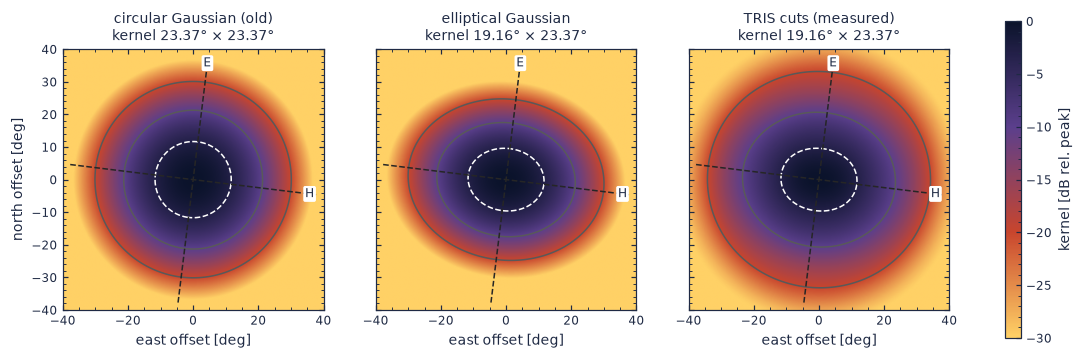

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
for ax, (label, spec) in zip(axes, SPECS.items()):
    kernel = eb.kernel_for(spec, 0.0)                    # a point-like native beam
    x, y, resp = eb.kernel_image(kernel, spec, half_width_deg=40.0, step_deg=0.25)
    db = np.clip(10 * np.log10(np.maximum(resp, 1e-6)), -30, 0)
    im = ax.imshow(db, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()],
                   cmap=SEQB.reversed(), vmin=-30, vmax=0)
    ax.contour(x, y, db, levels=[HALF_DB], colors="white")
    ax.contour(x, y, db, levels=[-20, -10], colors="0.35", linestyles="-")
    for pa, name in ((PA_E, "E"), (PA_E + 90, "H")):
        s, c = np.sin(np.radians(pa)), np.cos(np.radians(pa))
        ax.plot([-38 * s, 38 * s], [-38 * c, 38 * c], "--", color="0.15")
        ax.text(36 * s, 36 * c, name, fontsize=8, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
    ax.set_title(f"{label}\nkernel {kernel.fwhm_e_deg:.2f}° × {kernel.fwhm_h_deg:.2f}°")
    ax.set_xlabel("east offset [deg]")
    ax.set_aspect("equal")
axes[0].set_ylabel("north offset [deg]")
fig.colorbar(im, ax=axes, shrink=0.85, label="kernel [dB rel. peak]")
plt.show()

---
### 2. Profiles along the E and H planes

The same three kernels, cut along the **E plane** (left, position angle 7°) and the
**H plane** (middle, 97°), in dB against angle from the centre. Black dots are the archive's
own cut samples (`TRIS_Beam_Profile.txt`). The horizontal line is half power; each legend
entry gives the FWHM measured from the curve.

**Right: how much weight is in the shoulders.** The fraction of each kernel's total weight
lying beyond angle θ, on a log scale. It is integrated over the sphere: every direction,
weighted by sin θ. A circular and an elliptical Gaussian put almost nothing beyond 30°. The
measured beam puts a visible fraction there, so a bright source 30–60° away contributes to
a smoothed pixel. That is what TRIS itself sees, which is why `tris_cuts` is the default.

**What to look for.** The measured kernel (blue) follows the black dots exactly, including
the slow fall below −10 dB. The circular kernel matches the H-plane width but is too wide
on the E plane.

circular Gaussian (old)    weight beyond 30°:   0.97%   beyond 45°:  0.003%
elliptical Gaussian        weight beyond 30°:   0.47%   beyond 45°:  0.001%
TRIS cuts (measured)       weight beyond 30°:   3.44%   beyond 45°:  0.283%


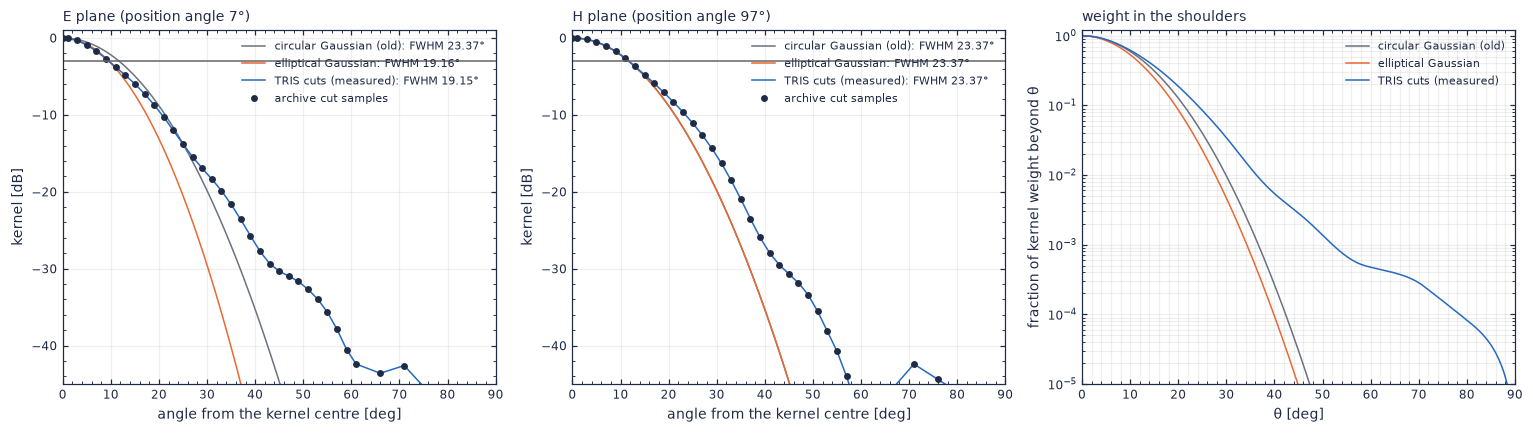

In [4]:
theta = np.arange(0.0, 90.0, 0.05)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))
for ax, (pa, plane, cut_db) in zip(axes[:2], ((PA_E, "E plane", SPEC_CUTS.cut_e_db),
                                              (PA_E + 90, "H plane", SPEC_CUTS.cut_h_db))):
    for label, spec in SPECS.items():
        kernel = eb.kernel_for(spec, 0.0)
        r = eb.kernel_response(kernel, spec, theta, np.full(theta.size, pa))
        ax.plot(theta, 10 * np.log10(np.maximum(r, 1e-7)), color=KCOL[label],
                label=f"{label}: FWHM {fwhm_from_profile(theta, r):.2f}°")
    ax.plot(SPEC_CUTS.cut_angle_deg, cut_db, "o", ms=3.5, color=COLORS["ink"], label="archive cut samples")
    ax.axhline(HALF_DB, color="0.4")
    ax.set_xlim(0, 90); ax.set_ylim(-45, 1)
    ax.set_xlabel("angle from the kernel centre [deg]"); ax.set_ylabel("kernel [dB]")
    ax.set_title(f"{plane} (position angle {pa:.0f}°)", loc="left")
    ax.legend(); ax.grid(alpha=0.2)

# Fraction of the kernel's weight beyond theta (sphere: integrate over position angle with sin(theta)).
th = np.arange(0.0, 90.0, 0.1) + 0.05
pa_grid = np.arange(0.0, 360.0, 1.0)
T, P = np.meshgrid(th, pa_grid, indexing="ij")
ax = axes[2]
for label, spec in SPECS.items():
    kernel = eb.kernel_for(spec, 0.0)
    ring_weight = eb.kernel_response(kernel, spec, T, P).mean(axis=1) * np.sin(np.radians(th))
    beyond = 1.0 - np.cumsum(ring_weight) / ring_weight.sum()
    ax.semilogy(th, np.maximum(beyond, 1e-6), color=KCOL[label], label=label)
    print(f"{label:<26} weight beyond 30°: {100 * np.interp(30, th, beyond):6.2f}%   "
          f"beyond 45°: {100 * np.interp(45, th, beyond):6.3f}%")
ax.set_xlim(0, 90); ax.set_ylim(1e-5, 1.2)
ax.set_xlabel("θ [deg]"); ax.set_ylabel("fraction of kernel weight beyond θ")
ax.set_title("weight in the shoulders", loc="left")
ax.legend(); ax.grid(alpha=0.2, which="both")
plt.tight_layout(); plt.show()

**Reading plot 2 (run 2026-10-14).** On the principal planes, the measured kernel is
19.155° (E) and 23.366° (H), on the archive's own samples. The circular kernel is 23.366°
on both planes, 22% too wide on E. **Weight beyond 30°:** 3.44% for the measured beam,
against 0.97% (circular) and 0.47% (elliptical Gaussian); beyond 45°: 0.28% against
≤ 0.003%. The shoulders are a real few-percent effect, and only `tris_cuts` carries them.

---
### 3. Which kernel each survey gets

The effective beam of a smoothed map is the survey's own beam convolved with the kernel.
So the kernel must be *narrower* than TRIS by the right amount (step 4 at the top of this
section):

* **cut beam, unchanged**: the native beam is narrow enough to neglect. The expected
  effective widths are then a fraction of a percent above TRIS.
* **cut beam, compressed**: the native beam is too broad to neglect. The cut is read at
  `θ × scale`, which shrinks it to the quadrature widths √(target² − native²).

Bars: the kernel's own E (dark) and H (light) widths per survey. Dashed lines: TRIS's
19.155° and 23.366°. A shorter bar means a broader native beam, which needs less extra
smoothing.

survey                              native  kernel E  kernel H  scale E  expect E  expect H  how
LWA1 35 MHz                          4.65°    18.58°    22.90°    1.031    19.16°    23.37°  native beam too broad to neglect (2.90% on E): cut beam compressed to the quadrature core widths (approximate; exact only for Gaussian cores)
LWA1 38 MHz                          4.28°    18.67°    22.97°    1.026    19.16°    23.37°  native beam too broad to neglect (2.47% on E): cut beam compressed to the quadrature core widths (approximate; exact only for Gaussian cores)
LWA1 40 MHz                          4.07°    18.72°    23.01°    1.023    19.16°    23.37°  native beam too broad to neglect (2.23% on E): cut beam compressed to the quadrature core widths (approximate; exact only for Gaussian cores)
LWA1 45 MHz                          3.62°    18.81°    23.08°    1.018    19.16°    23.37°  native beam too broad to neglect (1.77% on E): cut beam compressed to the quadrature core widths (approxi

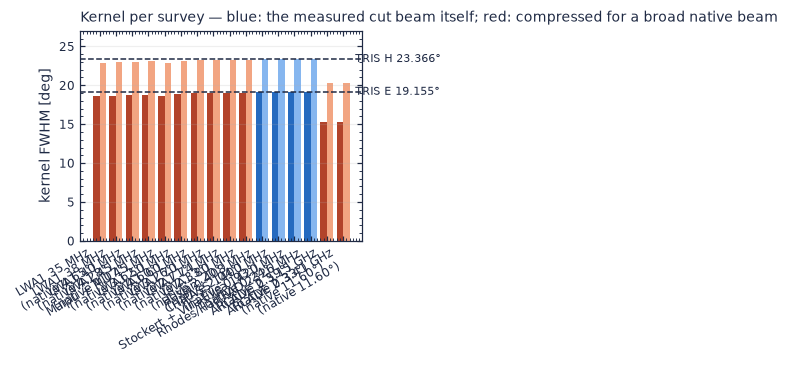

In [5]:
ALL_MAPS = sky_maps.discover(REPO / "res")
MAPS = [m for m in ALL_MAPS if (m["usable"] and m["role"] == "fit") or m["file"] == "HASLAM.fits"]

rows = []
for m in MAPS:
    k = eb.kernel_for(SPEC_CUTS, m["fwhm_deg"])
    rows.append((m["name"], m["fwhm_deg"], k))
print(f"{'survey':<34}{'native':>8}{'kernel E':>10}{'kernel H':>10}{'scale E':>9}"
      f"{'expect E':>10}{'expect H':>10}  how")
for name, native, k in rows:
    print(f"{name:<34}{native:7.2f}°{k.fwhm_e_deg:9.2f}°{k.fwhm_h_deg:9.2f}°{k.scale_e:9.3f}"
          f"{k.expected_e_deg:9.2f}°{k.expected_h_deg:9.2f}°  {k.note}")

fig, ax = plt.subplots()
xpos = np.arange(len(rows))
ke = [k.fwhm_e_deg for _, _, k in rows]
kh = [k.fwhm_h_deg for _, _, k in rows]
compressed = [k.scale_e > 1.0 or k.shape != "tris_cuts" for _, _, k in rows]
ax.bar(xpos - 0.2, ke, width=0.4, color=["#b2432a" if c else "#256abf" for c in compressed],
       label="kernel E width")
ax.bar(xpos + 0.2, kh, width=0.4, color=["#f2a582" if c else "#86b6ef" for c in compressed],
       label="kernel H width")
ax.axhline(FWHM_E, color=COLORS["ink"], ls="--"); ax.axhline(FWHM_H, color=COLORS["ink"], ls="--")
ax.text(len(rows) - 0.5, FWHM_E, " TRIS E 19.155°", va="center", fontsize=7.5)
ax.text(len(rows) - 0.5, FWHM_H, " TRIS H 23.366°", va="center", fontsize=7.5)
ax.set_xticks(xpos)
ax.set_xticklabels([f"{n}\n(native {nat:.2f}°)" for n, nat, _ in rows], rotation=30, ha="right")
ax.set_ylabel("kernel FWHM [deg]"); ax.set_ylim(0, 27)
ax.set_title("Kernel per survey — blue: the measured cut beam itself; red: compressed for a broad native beam",
             loc="left")
ax.grid(axis="y", alpha=0.2)
plt.show()

---
### 4. A point source through the real smoothing code

Plots 1–3 show the kernel as a function. This plot runs it through
`elliptical_beam.smooth_at_positions`, the same code path the pipeline uses, so a mistake
in orientation, units or normalisation would show here and nowhere earlier.

**Top row: a narrow native beam.** One bright working-grid pixel at TRIS's own declination
(RA 180°, Dec +42.4°). Each panel is the smoothed map around it, in dB, on the same
east/north offset grid as plot 1. If the code is right it reproduces plot 1. A tilt the
other way, or E and H swapped, would be visible immediately.

**Bottom row: a broad native beam.** The same source first smoothed with a Gaussian of
ARCADE 2's 11.6° (left pair) or LWA1 35 MHz's 4.65° (right pair), then with the kernel
the pipeline chooses for that survey. Profiles along E and H against the target (the
measured beam, as for a point source):

* **scaled cuts** (the default for broad beams): the cut beam compressed to the quadrature
  widths;
* **elliptical Gaussian**: the per-axis quadrature Gaussian;
* **uncompensated**: the cut beam applied as if the native beam were negligible. This
  shows how much over-smoothing the compensation removes.

**What to look for.** In the top row, FWHMs of 19.155° / 23.366° on the E / H planes for
the two elliptical kernels, and 23.366° both ways for the circular one. In the bottom row,
how close each route lands to the target's FWHM *and* to its shoulders.

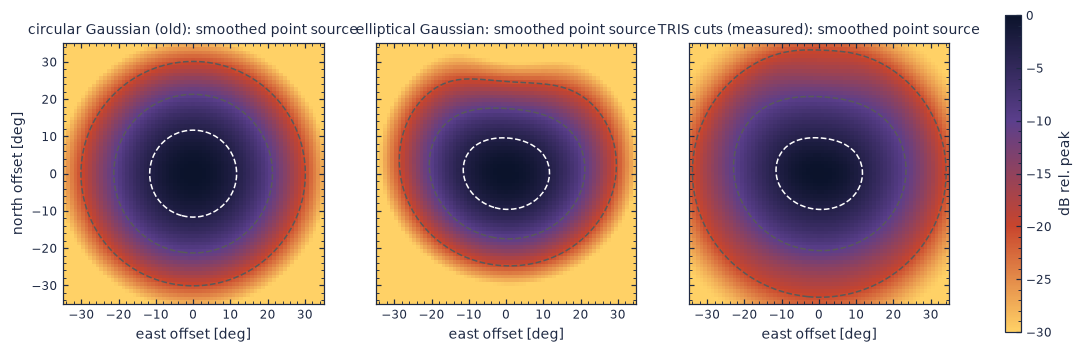

kernel                       E plane (PA 7°)  H plane (PA 97°)       north (Dec)         east (RA)
circular Gaussian (old)              23.366°           23.366°           23.366°           23.366°
elliptical Gaussian                  19.157°           23.203°           19.202°           23.348°
TRIS cuts (measured)                 19.157°           23.242°           19.211°           23.352°
expected: elliptical kernels 19.155° on E and 23.366° on H; circular 23.366° everywhere.
(The single 0.92° source pixel adds < 0.02° in quadrature.)


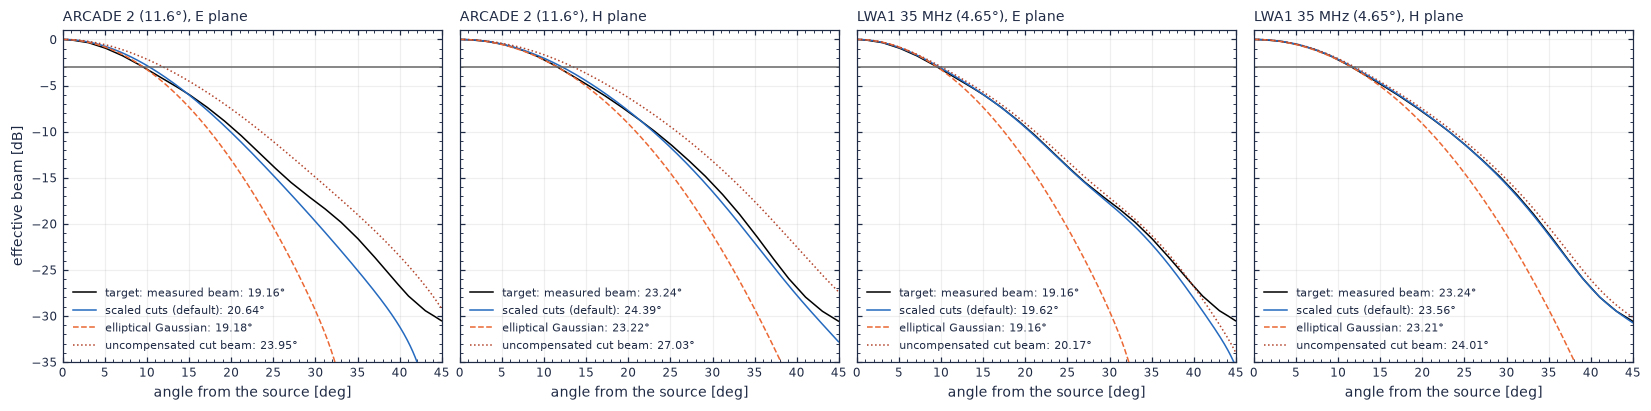

In [6]:
NW = SPEC_CUTS.nside_work
RA0, DEC0 = 180.0, float(BORESIGHT_DEC)
src = np.zeros(hp.nside2npix(NW))
src_pix = hp.ang2pix(NW, RA0, DEC0, lonlat=True)
src[src_pix] = 1.0
RA0, DEC0 = (float(v) for v in hp.pix2ang(NW, src_pix, lonlat=True))   # the pixel's own centre
ALL_SKY = np.ones(src.size, dtype=bool)

# --- top row: the smoothed point source as an image, through the real code --------------
grid_axis = np.arange(-35.0, 35.0 + 1e-9, 1.0)
GX, GY = np.meshgrid(grid_axis, grid_axis)
img_vectors = offset_vectors(RA0, DEC0, np.degrees(np.arctan2(GX, GY)), np.hypot(GX, GY))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
for ax, (label, spec) in zip(axes, SPECS.items()):
    out = eb.smooth_at_positions(src, ALL_SKY, 0.0, spec, img_vectors)
    v = out["values"].reshape(GX.shape)
    db = np.clip(10 * np.log10(np.maximum(v / np.nanmax(v), 1e-6)), -30, 0)
    im = ax.imshow(db, origin="lower", extent=[grid_axis[0], grid_axis[-1], grid_axis[0], grid_axis[-1]],
                   cmap=SEQB.reversed(), vmin=-30, vmax=0)
    ax.contour(GX, GY, db, levels=[HALF_DB], colors="white")
    ax.contour(GX, GY, db, levels=[-20, -10], colors="0.35")
    ax.set_title(f"{label}: smoothed point source")
    ax.set_xlabel("east offset [deg]"); ax.set_aspect("equal")
axes[0].set_ylabel("north offset [deg]")
fig.colorbar(im, ax=axes, shrink=0.85, label="dB rel. peak")
plt.show()

# Widths measured on the smoothed output, along four directions.
offsets = np.arange(0.0, 45.0, 0.05)
directions = {"E plane (PA 7°)": PA_E, "H plane (PA 97°)": PA_E + 90,
              "north (Dec)": 0.0, "east (RA)": 90.0}
print(f"{'kernel':<26}" + "".join(f"{d:>18}" for d in directions))
for label, spec in SPECS.items():
    widths = []
    for pa in directions.values():
        vec = offset_vectors(RA0, DEC0, np.full(offsets.size, pa), offsets)
        widths.append(fwhm_from_profile(offsets, eb.smooth_at_positions(src, ALL_SKY, 0.0, spec, vec)["values"]))
    print(f"{label:<26}" + "".join(f"{w:17.3f}°" for w in widths))
print("expected: elliptical kernels 19.155° on E and 23.366° on H; circular 23.366° everywhere."
      "\n(The single 0.92° source pixel adds < 0.02° in quadrature.)")

# --- bottom row: broad native beams ---------------------------------------------------------
SPEC_GAUSS_BROAD = replace(SPEC_CUTS, broad_native_kernel="elliptical_gaussian")
target_kernel = eb.kernel_for(SPEC_CUTS, 0.0)            # the measured beam, as for a point source
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for col, (survey, native) in enumerate((("ARCADE 2", 11.6), ("LWA1 35 MHz", 4.65))):
    pre = hp.smoothing(src, fwhm=np.radians(native), iter=3)          # the survey's own beam
    routes = {
        "target: measured beam": (src, target_kernel, SPEC_CUTS, "k", "-"),
        "scaled cuts (default)": (pre, eb.kernel_for(SPEC_CUTS, native), SPEC_CUTS, "#256abf", "-"),
        "elliptical Gaussian": (pre, eb.kernel_for(SPEC_GAUSS_BROAD, native), SPEC_GAUSS_BROAD, "#eb6834", "--"),
        "uncompensated cut beam": (pre, target_kernel, SPEC_CUTS, "#b2432a", ":"),
    }
    for j, (pa, plane) in enumerate(((PA_E, "E plane"), (PA_E + 90, "H plane"))):
        ax = axes[2 * col + j]
        vec = offset_vectors(RA0, DEC0, np.full(offsets.size, pa), offsets)
        for name, (sky, kernel, spec, colour, ls) in routes.items():
            v = eb.smooth_at_positions(sky, ALL_SKY, 0.0, spec, vec, kernel=kernel)["values"]
            ax.plot(offsets, 10 * np.log10(np.maximum(v / v[0], 1e-7)), ls, color=colour,
                    label=f"{name}: {fwhm_from_profile(offsets, v):.2f}°")
        ax.axhline(HALF_DB, color="0.4")
        ax.set_xlim(0, 45); ax.set_ylim(-35, 1)
        ax.set_title(f"{survey} ({native}°), {plane}", loc="left")
        ax.set_xlabel("angle from the source [deg]")
        ax.legend(loc="lower left"); ax.grid(alpha=0.2)
axes[0].set_ylabel("effective beam [dB]")
plt.tight_layout(); plt.show()

**Reading plot 4 (run 2026-10-14).**

* **Orientation is right.** The images are narrow north–south, wide east–west and tilted
  7° east. Section H3 below confirms the +7° sign independently: limTOD's own pointed beam
  matches it to 0.6% of the peak, against 3.6% for −7°.
* **Widths on the smoothed point source:** E plane 19.157°. H plane 23.24° (cut beam) and
  23.20° (elliptical Gaussian), not 23.366°. **This is expected, not an error.** Each output
  point uses the beam oriented to *its own* north, as TRIS's would be pointing there. Seen
  from a point 11.7° east of the source at Dec +42°, the source lies at position angle
  −73° rather than −83°: the meridians converge by ~10° over that distance. So the line
  through the source's H plane crosses each output's beam ~10° off its H plane, and reads
  narrower. The kernel itself is exactly 19.155° × 23.366° (plot 2,
  `tests/test_elliptical_beam.py`). At the equator, where meridians are parallel, the
  test measures 23.366° on the smoothed source.
* **Broad native beams: the default `scaled_cuts` does not hit the target widths.**

  | survey | target E × H | scaled cuts | elliptical Gaussian | uncompensated |
  |---|---|---|---|---|
  | ARCADE 2 (11.6°) | 19.16° × 23.24° | **20.64° × 24.39°** (+8% / +5%) | 19.18° × 23.22° | 23.95° × 27.03° |
  | LWA1 35 MHz (4.65°) | 19.16° × 23.24° | 19.62° × 23.56° (+2.4% / +1.4%) | 19.16° × 23.21° | 20.17° × 24.01° |

  Convolving an 11.6° Gaussian with a *non-Gaussian* kernel does not add widths in
  quadrature, so compressing the cut beam to the quadrature widths under-compresses it.
  The elliptical Gaussian matches the half-power widths almost exactly, but falls away much
  faster than the measured beam below about −10 dB (Gaussian shoulders). Neither matches
  both. The options (`QUICKSTART.md` open item 5): switch these surveys to `elliptical_gaussian`, or choose
  each scale numerically so that native ⊛ scaled kernel has the target FWHM.

---
### 5. Haslam: old kernel against new

Haslam (408 MHz, full sky, native 0.93°), rotated into equatorial and matched to the TRIS
beam on nside 16 with each kernel through `match_to_tris_beam`, exactly as stage 2 does.

* **Top:** the circular result, the measured-beam result, and their difference as a
  percentage of the circular one. The difference is largest where the sky has structure on
  the scale of the beam, along the Galactic plane. In smooth regions it should be near 0.
* **Bottom left:** the same percentage difference for every pixel of the TRIS stripe, for
  both elliptical kernels.
* **Bottom right:** temperature along the TRIS ring (the stripe pixels nearest Dec +42.4°)
  against RA, for all three kernels, with the ratio to the circular one underneath. This is
  where the map route's fit happens. Where the ring crosses the plane (Cygnus, RA ≈ 300°)
  the narrower E axis keeps more of the peak.

circular Gaussian (old)    3072 pixels kept; mean 34.405 K
elliptical Gaussian        3072 pixels kept; mean 34.447 K
TRIS cuts (measured)       3072 pixels kept; mean 34.435 K


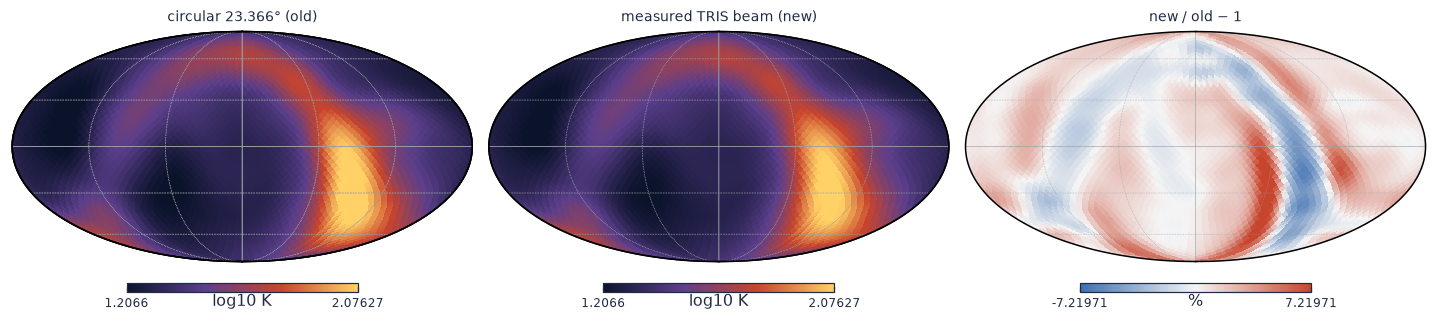

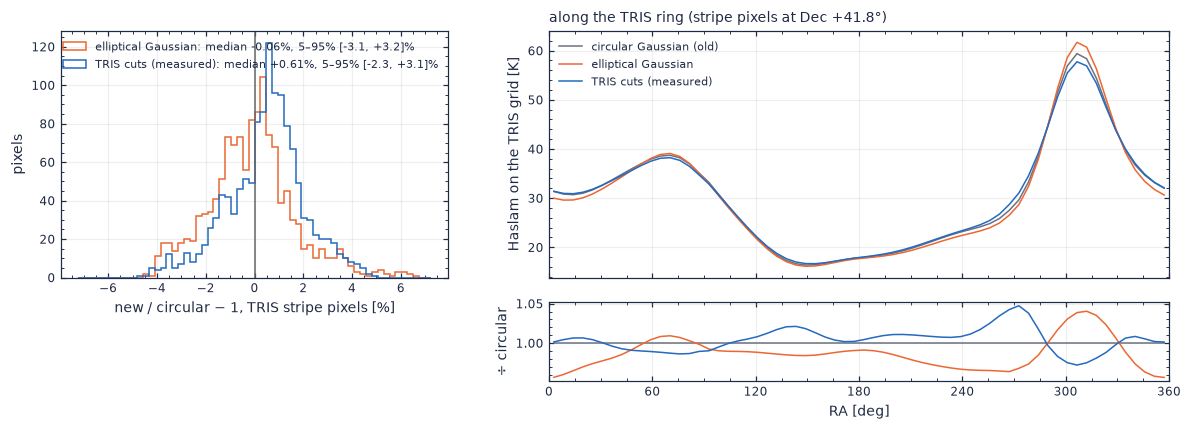

In [7]:
BAND16 = load_stage1(config)["band_mask"].astype(bool)
NSIDE16 = hp.npix2nside(BAND16.size)
haslam_native = hp.read_map(config.resolve_path("paths.haslam_map_fits"))
haslam_eq = frames.rotate_full_sky(haslam_native, ("G", "C"))
HASLAM = {}
for label, spec in SPECS.items():
    values, kept, info = match_to_tris_beam(
        haslam_eq, np.ones(haslam_eq.size, bool), float(config.require("beam_matching.haslam_native_fwhm_deg")),
        CONFIGS[label], nside_out=NSIDE16, rule="all_children",
        spec=None if KERNEL_KEY[label] == "circular_gaussian" else spec, full_sky=True)
    HASLAM[label] = np.where(kept, values, np.nan)
    print(f"{label:<26} {int(kept.sum())} pixels kept; mean {np.nanmean(HASLAM[label]):.3f} K")

old, new = HASLAM["circular Gaussian (old)"], HASLAM["TRIS cuts (measured)"]
pct = 100 * (new / old - 1)
lo, hi = np.nanpercentile(old, [2, 98])
span = float(np.nanpercentile(np.abs(pct), 99))
fig = plt.figure(figsize=(13, 3.8))
hp.mollview(np.log10(old), sub=(1, 3, 1), fig=fig.number, title="circular 23.366° (old)",
            unit="log10 K", min=np.log10(lo), max=np.log10(hi), notext=True)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
hp.mollview(np.log10(new), sub=(1, 3, 2), fig=fig.number, title="measured TRIS beam (new)",
            unit="log10 K", min=np.log10(lo), max=np.log10(hi), notext=True)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
hp.mollview(pct, sub=(1, 3, 3), fig=fig.number, cmap=DIVB, min=-span, max=span,
            title="new / old − 1", unit="%", notext=True)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
plt.show()

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.0), gridspec_kw=dict(width_ratios=[1, 1.6]))
bins = np.linspace(-span, span, 61)
for label in ("elliptical Gaussian", "TRIS cuts (measured)"):
    d = 100 * (HASLAM[label][BAND16] / old[BAND16] - 1)
    ax.hist(d[np.isfinite(d)], bins=bins, histtype="step", color=KCOL[label],
            label=f"{label}: median {np.nanmedian(d):+.2f}%, 5–95% [{np.nanpercentile(d, 5):+.1f}, {np.nanpercentile(d, 95):+.1f}]%")
ax.axvline(0, color="0.4")
ax.set_xlabel("new / circular − 1, TRIS stripe pixels [%]"); ax.set_ylabel("pixels")
ax.legend(); ax.grid(alpha=0.2)

stripe_pix = np.flatnonzero(BAND16)
ra_s, dec_s = hp.pix2ang(NSIDE16, stripe_pix, lonlat=True)
ring_dec = dec_s[np.argmin(np.abs(dec_s - BORESIGHT_DEC))]
on_ring = stripe_pix[np.isclose(dec_s, ring_dec)]
order = np.argsort(hp.pix2ang(NSIDE16, on_ring, lonlat=True)[0])
on_ring = on_ring[order]
ra_ring = hp.pix2ang(NSIDE16, on_ring, lonlat=True)[0]
inner = ax2.inset_axes([0, -0.42, 1, 0.32])
for label in SPECS:
    ax2.plot(ra_ring, HASLAM[label][on_ring], "-", color=KCOL[label], label=label)
    inner.plot(ra_ring, HASLAM[label][on_ring] / old[on_ring], "-", color=KCOL[label])
ax2.set_ylabel("Haslam on the TRIS grid [K]")
ax2.set_title(f"along the TRIS ring (stripe pixels at Dec {ring_dec:+.1f}°)", loc="left")
ax2.legend(); ax2.grid(alpha=0.2); ax2.set_xticklabels([])
inner.set_ylabel("÷ circular"); inner.set_xlabel("RA [deg]"); inner.grid(alpha=0.2)
for a in (ax2, inner):
    a.set_xlim(0, 360); a.set_xticks(np.arange(0, 361, 60))
plt.subplots_adjust(bottom=0.32)
plt.show()

**Reading plot 5 (run 2026-10-14).** Both kernels keep all 3072 pixels (Haslam is full
sky). The mean rises by 0.09%, from 34.405 K to 34.435 K: the measured beam's shoulders
pull in a little of the bright plane. In the stripe the change is centred near +0.6%, with
5–95% of pixels within about −2.3% to +3.1% (plot 7's Haslam row). It is largest where
the narrower E axis resolves Galactic-plane structure north–south.

---
### 6. ARCADE 2: the mask edge under both kernels

ARCADE 2 observed a thin ring (93% of the sky unobserved) and has the broadest native beam
(11.6°), so it is where the kernel shape changes **which pixels survive**. The weight floor
keeps a pixel only if at least half the kernel's weight falls on observed sky. A kernel that
is narrower north–south than the old circular one loses less of a ring that runs east–west,
and more of one that runs north–south.

* **Left:** each nside 16 pixel coloured by the kernel(s) under which it is kept.
* **Right:** on the pixels both keep, the new value against the old (3.15 GHz, K). Points
  on the dashed line are unchanged.

kept by both: 140;  only circular: 30;  only measured beam: 1
inside the TRIS stripe: old 153, new 127
new kernel: native beam too broad to neglect (16.91% on E): cut beam compressed to the quadrature core widths (approximate; exact only for Gaussian cores)


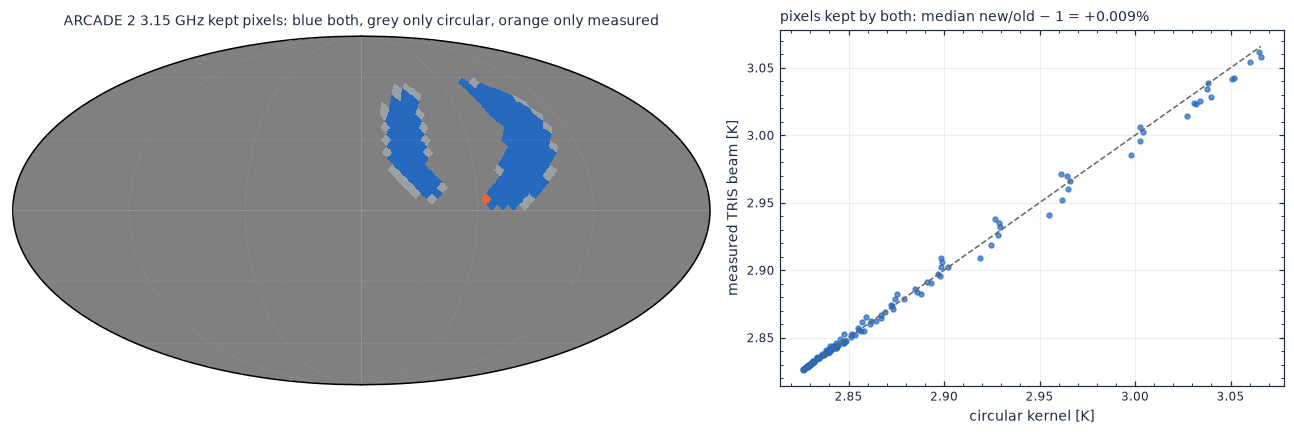

In [8]:
arcade_native = hp.read_map(config.resolve_path("paths.arcade2_map_3150"))
arc_obs = observed_mask(arcade_native, "zeros")
arc_rot, arc_obs_rot, _ = frames.rotate_masked(arcade_native, arc_obs, ("G", "C"))
ARC = {}
for label in ("circular Gaussian (old)", "TRIS cuts (measured)"):
    values, kept, info = match_to_tris_beam(
        arc_rot, arc_obs_rot, float(config.require("beam_matching.arcade2_native_fwhm_deg")),
        CONFIGS[label], nside_out=NSIDE16, rule="all_children",
        spec=None if KERNEL_KEY[label] == "circular_gaussian" else SPECS[label], full_sky=False)
    ARC[label] = (values, kept, info)

k_old, k_new = ARC["circular Gaussian (old)"][1], ARC["TRIS cuts (measured)"][1]
category = np.full(k_old.size, np.nan)
category[k_old & k_new] = 0
category[k_old & ~k_new] = 1
category[~k_old & k_new] = 2
print(f"kept by both: {int((k_old & k_new).sum())};  only circular: {int((k_old & ~k_new).sum())};  "
      f"only measured beam: {int((~k_old & k_new).sum())}")
print(f"inside the TRIS stripe: old {int((k_old & BAND16).sum())}, new {int((k_new & BAND16).sum())}")
print("new kernel:", ARC["TRIS cuts (measured)"][2]["kernel_note"])

cat_cmap = ListedColormap(["#256abf", "#9aa0a6", "#eb6834"]); cat_cmap.set_bad("white")
fig = plt.figure(figsize=(13, 4.2))
hp.mollview(category, sub=(1, 2, 1), fig=fig.number, cmap=cat_cmap, min=-0.5, max=2.5, cbar=False,
            title="ARCADE 2 3.15 GHz kept pixels: blue both, grey only circular, orange only measured",
            notext=True)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
ax = fig.add_subplot(1, 2, 2)
both = k_old & k_new
v_old, v_new = ARC["circular Gaussian (old)"][0][both], ARC["TRIS cuts (measured)"][0][both]
ax.scatter(v_old, v_new, s=10, color="#256abf", alpha=0.7)
lim = [min(v_old.min(), v_new.min()), max(v_old.max(), v_new.max())]
ax.plot(lim, lim, "--", color="0.4")
ax.set_xlabel("circular kernel [K]"); ax.set_ylabel("measured TRIS beam [K]")
ax.set_title(f"pixels kept by both: median new/old − 1 = {100 * np.median(v_new / v_old - 1):+.3f}%",
             loc="left")
ax.grid(alpha=0.2)
plt.show()

**Reading plot 6 (run 2026-10-14).** The new kernel keeps **140 pixels that both keep, 30
that only the circular kernel kept, and 1 new one**. Inside the TRIS stripe ARCADE 2 goes
from **153 to 127 pixels**, so 26 fewer stripe pixels get four SED points. ARCADE 2's ring
is narrow, and its native beam is broad, so its kernel is the compressed cut beam (plot 4).
That kernel carries the cut beam's shoulders over a wider area, which puts more of its
weight off the ring. Values on the shared pixels agree to well under 1% (median shown
above). This interacts with the 0.5 weight floor and the broad-native kernel.

---
### 7. Every map in the map route

Every survey the map route fits (plus Haslam), matched with the old and the new kernel,
compared pixel by pixel over the TRIS stripe. Each box is one survey: the spread of
`new / old − 1` in percent. The box spans the 25th–75th percentiles, the whiskers the
5th–95th, and the line is the median. The number above each box is how many stripe pixels
both kernels keep.

**What to look for.**
* A median near zero means the overall level is unchanged.
* The width of the box is the redistribution of structure: the narrower E axis sharpens
  features north–south, and the shoulders pull in a little distant emission.
* For LWA1, Maipu and ARCADE 2 the change also includes the compressed kernel, so compare
  with plot 4's bottom row.

This cell smooths every map twice. The circular kernel runs `hp.smoothing` at each
survey's native nside (CHIPASS is nside 1024), so it is slow. Set `RUN_ALL_MAPS = False`
to skip it.

LWA1 35 MHz                         1272 stripe px; median  +0.38%, 5–95% [ -1.91,  +1.92]%
LWA1 38 MHz                         1272 stripe px; median  +0.37%, 5–95% [ -1.86,  +1.76]%
LWA1 40 MHz                         1272 stripe px; median  +0.36%, 5–95% [ -1.86,  +1.72]%
LWA1 45 MHz                         1272 stripe px; median  +0.37%, 5–95% [ -1.94,  +1.98]%
Maipu + MU 45 MHz                   1200 stripe px; median  +0.50%, 5–95% [ -1.68,  +1.91]%
LWA1 50 MHz                         1272 stripe px; median  +0.36%, 5–95% [ -1.97,  +2.23]%
LWA1 60 MHz                         1272 stripe px; median  +0.41%, 5–95% [ -1.95,  +2.34]%
LWA1 70 MHz                         1272 stripe px; median  +0.38%, 5–95% [ -1.95,  +2.18]%
LWA1 74 MHz                         1272 stripe px; median  +0.45%, 5–95% [ -1.91,  +2.20]%
LWA1 80 MHz                         1272 stripe px; median  +0.46%, 5–95% [ -1.98,  +2.44]%
Haslam 408 MHz                      1272 stripe px; median  +0.61%, 5–95% [ -2.2

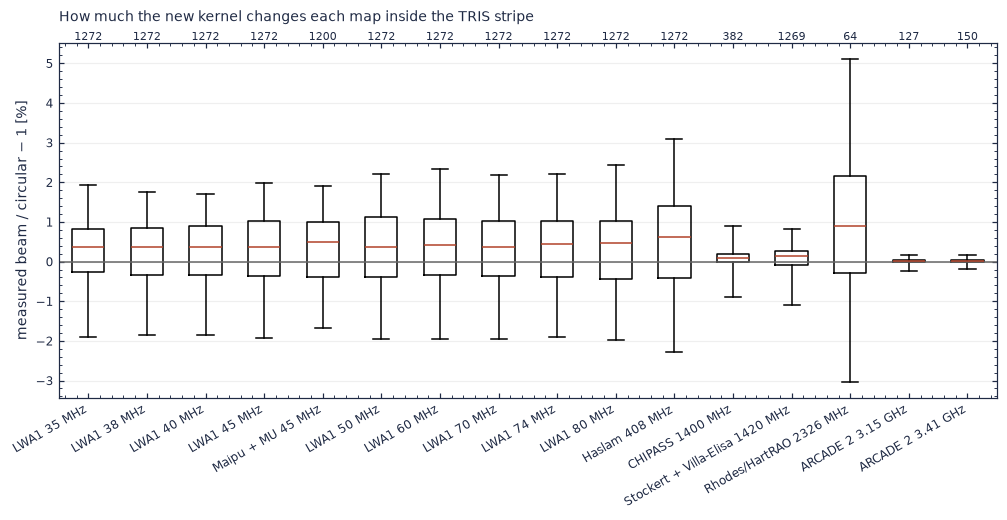

In [9]:
RUN_ALL_MAPS = True

def rotated_equatorial(m):
    # The same rotation as moonrunes.sed_prototype.Inputs._rotated.
    sky = m["sky"]
    observed = np.isfinite(sky)
    if m["frame"] == "C":
        return np.where(observed, sky, hp.UNSEEN), observed
    if observed.all():
        return frames.rotate_full_sky(sky, (m["frame"], "C")), observed
    rotated, obs_rot, _ = frames.rotate_masked(sky, observed, (m["frame"], "C"))
    return rotated, obs_rot

if RUN_ALL_MAPS:
    CHANGE = {}
    for m in MAPS:
        rotated, obs = rotated_equatorial(m)
        out = {}
        for label in ("circular Gaussian (old)", "TRIS cuts (measured)"):
            values, kept, _ = match_to_tris_beam(
                rotated, obs, m["fwhm_deg"], CONFIGS[label], nside_out=NSIDE16, rule="all_children",
                spec=None if KERNEL_KEY[label] == "circular_gaussian" else SPECS[label],
                full_sky=bool(obs.all()))
            out[label] = np.where(kept, values, np.nan)
        both = BAND16 & np.isfinite(out["circular Gaussian (old)"]) & np.isfinite(out["TRIS cuts (measured)"])
        CHANGE[m["name"]] = 100 * (out["TRIS cuts (measured)"][both] / out["circular Gaussian (old)"][both] - 1)
        d = CHANGE[m["name"]]
        print(f"{m['name']:<34} {both.sum():5d} stripe px; median {np.median(d) if d.size else np.nan:+6.2f}%, "
              f"5–95% [{np.percentile(d, 5) if d.size else np.nan:+6.2f}, {np.percentile(d, 95) if d.size else np.nan:+6.2f}]%")

    names = [n for n in CHANGE if CHANGE[n].size]
    fig, ax = plt.subplots(figsize=(11, 4.2))
    ax.boxplot([CHANGE[n] for n in names], whis=(5, 95), showfliers=False, widths=0.55,
               medianprops=dict(color="#b2432a"))
    for i, n in enumerate(names, start=1):
        ax.text(i, ax.get_ylim()[1], f"{CHANGE[n].size}", ha="center", va="bottom", fontsize=7)
    ax.axhline(0, color="0.4")
    ax.set_xticks(range(1, len(names) + 1))
    ax.set_xticklabels(names, rotation=30, ha="right")
    ax.set_ylabel("measured beam / circular − 1 [%]")
    ax.set_title("How much the new kernel changes each map inside the TRIS stripe", loc="left",
                 pad=14)
    ax.grid(axis="y", alpha=0.2)
    plt.show()

**Reading plot 7 (run 2026-10-14).** New / old − 1 inside the TRIS stripe:

| survey | stripe pixels | median | 5–95% |
|---|---|---|---|
| LWA1 35 MHz | 1272 | +0.38% | −1.9 to +1.9% |
| Maipu 45 MHz | 1200 | +0.50% | −1.7 to +1.9% |
| LWA1 80 MHz | 1272 | +0.46% | −2.0 to +2.4% |
| Haslam 408 MHz | 1272 | +0.61% | −2.3 to +3.1% |
| CHIPASS 1400 MHz | 382 | +0.09% | −0.9 to +0.9% |
| Stockert 1420 MHz | 1269 | +0.13% | −1.1 to +0.8% |
| Rhodes 2326 MHz | 64 | +0.91% | −3.1 to +5.4% |
| ARCADE 2 3.15 / 3.41 GHz | 127 / 150 | +0.01% | ±0.2% |

**The kernel shape moves stripe pixels by up to a few percent, and levels by under 1%.**
That is small next to the 13–18% Haslam offset from the TOD route. It is not negligible
for per-pixel β, since a 2% change between 35 MHz and 408 MHz moves β by ~0.01. Haslam
and the low-frequency surveys move together (+0.4 to +0.6%), so ratios between them
change less than either map.

---
#### Reading this section (run 2026-10-14)

* **Correctness: passed.**
  * The measured kernel sits on the archive cut samples, at 19.155° × 23.366° (plot 2).
  * The orientation is +7°, confirmed against limTOD's own pointed beam (section H3).
  * `tests/test_elliptical_beam.py`: 15/15 pass.
* **The one approximation does not do what it was meant to.** For ARCADE 2 the default
  `scaled_cuts` gives an effective beam 8% (E) and 5% (H) too wide; for LWA1 35 MHz, 2.4%
  and 1.4%. The elliptical Gaussian hits the widths but not the shoulders (plot 4;
  `QUICKSTART.md` open item 5).
* **Consequences:**
  * stripe pixels change by up to a few percent and medians by under 1% (plot 7);
  * Haslam's mean rises 0.09% (plot 5);
  * ARCADE 2 keeps 26 fewer stripe pixels, 127 instead of 153 (plot 6).
* **Still open:** the TRIS maps' own resolution, against which the map route compares (see "Convolve → deconvolve" below).

---
## Harmonic-space checks: are the a_ℓm under control?

> **Note:** `beam_matching.kernel` (stage 2 and the map route) is `circular_gaussian`; the pipeline's ring TODs and step 1 use `tris_cuts`. "Default" below means `tris_cuts`.

**The concern.** Rotating or convolving in spherical-harmonic space
is risky unless the information in the map is under control. The $a_{\ell m}$ should fall
to ~zero **before** $\ell_\mathrm{max}$ ($= 3\,n_\mathrm{side} - 1$ in healpy). Otherwise
truncation and aliasing produce ringing and other spurious structure. Plot the $C_\ell$ of
each map to check, since beam smoothing should supply the high-ℓ suppression.

**Where the pipeline works in harmonic space.** Every rotation and convolution was found
by searching the code (`moonrunes/src` and `limTOD`):

| # | operation | where | space | inputs | ℓ_max |
|---|---|---|---|---|---|
| H-a | rotate Haslam G → C | `frames.rotate_full_sky` (`rotate_map_alms`); stage 2 and the map route | **harmonic** | full-sky Haslam, nside 512 | 1535 |
| H-b | circular smoothing to the TRIS beam | `smooth_to_target` (`hp.smoothing`, mask-aware); stage 2 with `kernel: circular_gaussian` | **harmonic** | every survey at native nside; masked maps zero-filled | 3·nside − 1 |
| H-c | point the TRIS beam at each TOD sample | limTOD `generate_TOD_sky` → `map2alm` of the beam, `rotate_alm`, `alm2map`; stage 1 and the TOD route | **harmonic** | the cut beam at `nside_hires` = 16 | 47 |
| H-d | point the horizon mask | limTOD, same path, then thresholded at 0.5 | **harmonic** | a step function at 90° | 47 |
| — | rotate masked maps (ARCADE 2, CHIPASS, Maipu, …) | `frames.rotate_masked` / `rotate_map_pixel` | pixel | — | — |
| — | elliptical smoothing (`kernel: tris_cuts`, the default) | `elliptical_beam.smooth_elliptical` | **pixel (direct sum)** | — | — |
| — | degrade / regrid | `ud_grade`, `regrid_to_nside` | pixel | — | — |
| — | GSM2008 prior G → C | `stage1_tris_maps` (`rotate_map_pixel`) | pixel | — | — |

Four harmonic operations, H-a to H-d. Each is tested below in two ways: **the C_ℓ**, as
the comment asks (do the a_ℓm fall to ~0 before ℓ_max?), and **the consequence**. The
consequence is checked by comparing each harmonic operation with an exact pixel-space
calculation of the same thing, at the level of the products the analysis uses.

| plot | checks |
|---|---|
| H1 | C_ℓ of every input map, raw and after the harmonic smoothing (H-b), against each survey's beam window and ℓ_max |
| H2 | the TRIS beam's own C_ℓ at nside 16–128, and its map → a_ℓm → map round trip (H-c) |
| H3 | limTOD's harmonically pointed beam and horizon against the exact pixel-space beam (H-c, H-d) |
| H4 | the consequence for the TODs: harmonic vs exact, at nside 16, 64 and 128 |
| H5 | Haslam's harmonic rotation: the round trip, where it rings, and whether the ringing survives smoothing (H-a) |
| H6 | harmonic smoothing against the same Gaussian computed exactly in real space (H-b), on Haslam and on masked ARCADE 2 |

In [10]:
# Setup for this section (needs `config`, `tris`, `load_stage1` from the first cell).
import time
from dataclasses import replace
from moonrunes import elliptical_beam as eb, frames, sky_maps
from moonrunes.stage2_beam_matching import smooth_to_target, extra_fwhm_deg, regrid_to_nside, observed_mask
from limTOD import generate_TOD_sky
from limTOD.simulator import pointing_beam_in_eq_sys
from matplotlib.colors import LinearSegmentedColormap

SEQB = plt.get_cmap("ring").copy()
SEQB.set_bad("#e8e8e6"); SEQB.set_under("white")
DIVB = plt.get_cmap("ring_div").copy()
DIVB.set_bad("#e8e8e6"); DIVB.set_under("white")

H_ARCHIVE = config.resolve_path("paths.tris_archive_dir")
H_CUTS = tris.read_tris_beam_cuts(H_ARCHIVE / "TRIS_Beam_Profile.txt")
H_SPEC = eb.beam_spec_from_config(config, kernel="tris_cuts")     # the exact cut beam, pixel space
H_KERNEL = eb.kernel_for(H_SPEC, 0.0)
H_RA = np.asarray(tris.read_tris_ring(H_ARCHIVE / "TRIS_absolute_600.txt").ra_deg)
H_GEOM = tris.tris_zenith_geometry(H_RA)
TARGET_FWHM = float(config.require("beam_matching.target_fwhm_deg"))
HASLAM_NATIVE = float(config.require("beam_matching.haslam_native_fwhm_deg"))

H_MAPS = [m for m in sky_maps.discover(REPO / "res")
          if (m["usable"] and m["role"] == "fit") or m["file"] == "HASLAM.fits"]
HASLAM_G = hp.read_map(config.resolve_path("paths.haslam_map_fits"))
HASLAM_C = frames.rotate_full_sky(HASLAM_G, ("G", "C"))

def tail_ratio(cl, lmax, frac=0.9):
    # Mean C_l over the top 10% of the ell range, relative to the largest C_l at ell >= 2.
    return float(cl[int(frac * lmax):lmax + 1].mean() / cl[2:].max())

print(f"{len(H_MAPS)} maps; TRIS beam pointed by limTOD at nside_hires = {int(config.require('tris.nside_hires'))}")

16 maps; TRIS beam pointed by limTOD at nside_hires = 16


---
### H1. The C_ℓ of every map, raw and after harmonic smoothing

One panel per survey, at its own nside, up to its own $\ell_\mathrm{max} = 3n_\mathrm{side}-1$
(the dotted vertical line). Every curve is divided by its largest value at ℓ ≥ 2.

* **Black: the raw map.** For a partial map this is the pseudo-$C_\ell$ of the
  mean-subtracted, zero-filled map divided by $f_\mathrm{sky}$. The mask edge adds power at
  every ℓ, so for those maps the raw tail is an upper limit on the sky's own.
* **Grey dashed: the survey's own beam**, $b_\ell^2$, scaled to the raw curve at ℓ = 10.
  It shows how much suppression the instrument provides by itself.
* **Blue: the output of the harmonic smoothing** (H-b): $\mathrm{smooth}(M\cdot T)$ with
  the quadrature kernel, i.e. $b_\ell^{K}\,a_\ell m$, the quantity `hp.smoothing` hands back
  before the mask division. This is what the comment asks about: after the beam, do the
  a_ℓm fall to ~zero before ℓ_max?

The number in each panel is **tail/peak**: the mean $C_\ell$ over the top 10% of the ℓ
range divided by the peak, for the raw map and after smoothing.

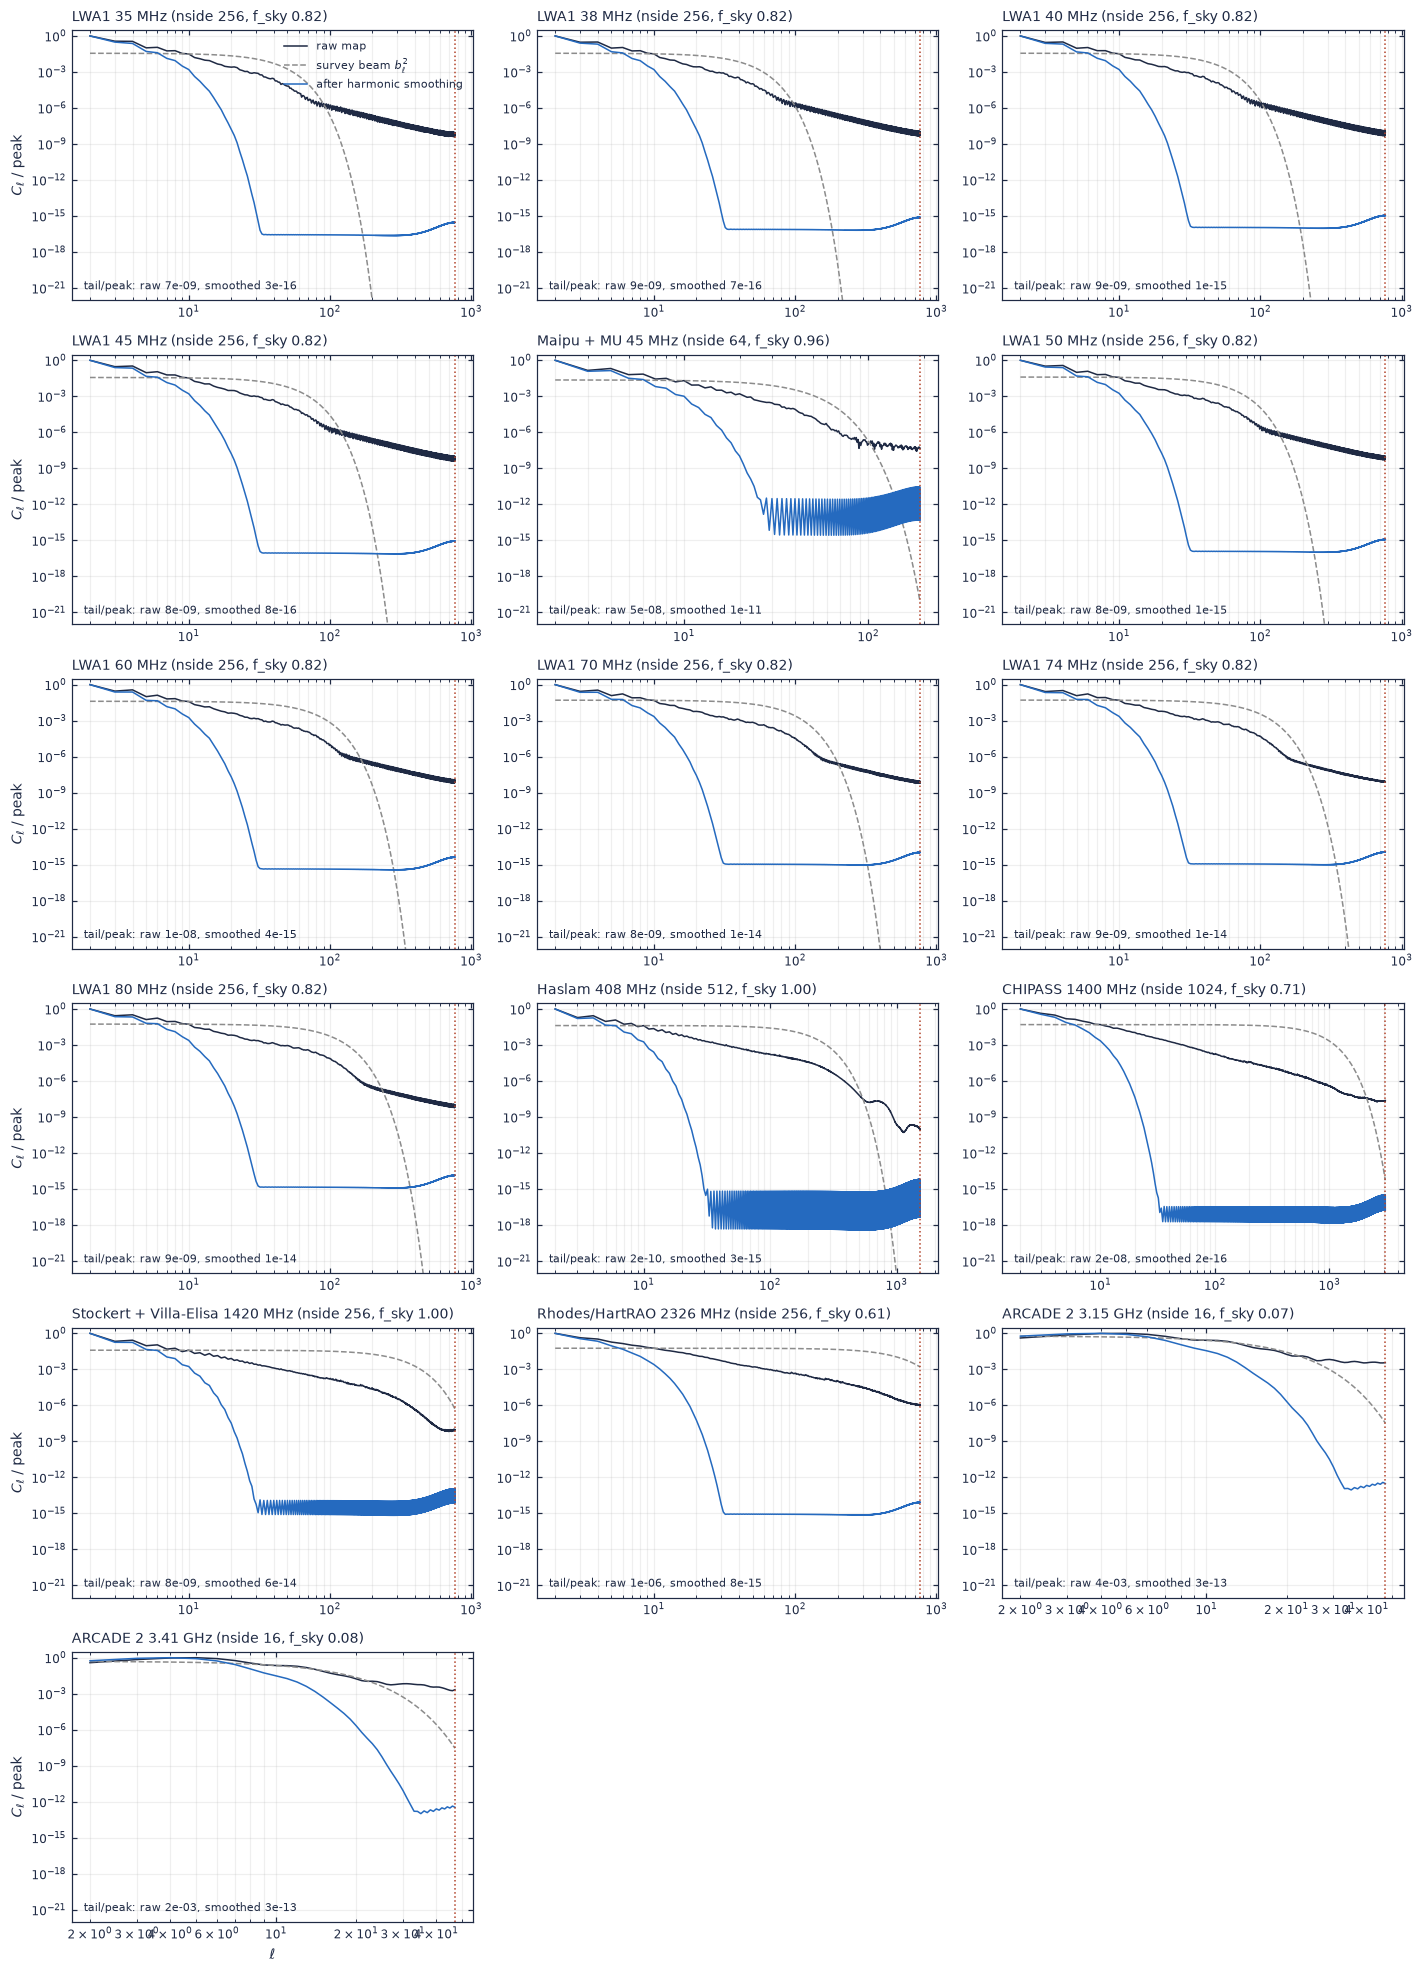

map                                nside  ℓmax  f_sky  raw tail/peak  smoothed tail/peak    b_ℓ²(ℓmax), own beam
LWA1 35 MHz                          256   767  0.821        7.1e-09             2.8e-16                1.4e-304
LWA1 38 MHz                          256   767  0.821        8.6e-09             7.3e-16                3.7e-258
LWA1 40 MHz                          256   767  0.821        9.4e-09             1.0e-15                1.6e-233
LWA1 45 MHz                          256   767  0.821        7.7e-09             8.2e-16                6.9e-185
Maipu + MU 45 MHz                     64   191  0.962        4.7e-08             1.3e-11                 3.1e-19
LWA1 50 MHz                          256   767  0.821        8.4e-09             1.1e-15                4.4e-150
LWA1 60 MHz                          256   767  0.821        9.8e-09             4.0e-15                6.2e-104
LWA1 70 MHz                          256   767  0.821        8.1e-09             1.0e-14        

In [11]:
H1 = {}
n = len(H_MAPS)
cols = 3
rows_ = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(13, 3.0 * rows_), squeeze=False)
t0 = time.time()
for ax, m in zip(axes.ravel(), H_MAPS):
    sky, ns = m["sky"], m["nside"]
    lmax = 3 * ns - 1
    ell = np.arange(lmax + 1)
    obs = np.isfinite(sky)
    fsky = obs.mean()
    raw = hp.anafast(np.where(obs, sky - np.nanmean(sky), 0.0), lmax=lmax) / fsky
    kernel = extra_fwhm_deg(m["fwhm_deg"], TARGET_FWHM)
    smoothed_num = hp.smoothing(np.where(obs, sky - np.nanmean(sky), 0.0), fwhm=np.radians(kernel), iter=3)
    cl_s = hp.anafast(smoothed_num, lmax=lmax) / fsky
    bl2 = hp.gauss_beam(np.radians(m["fwhm_deg"]), lmax=lmax) ** 2
    peak_raw, peak_s = raw[2:].max(), cl_s[2:].max()
    H1[m["name"]] = dict(nside=ns, lmax=lmax, fsky=fsky, raw_tail=tail_ratio(raw, lmax),
                         smoothed_tail=tail_ratio(cl_s, lmax), beam_lmax=float(bl2[-1]))
    ax.loglog(ell[2:], raw[2:] / peak_raw, color=COLORS["ink"], label="raw map")
    ax.loglog(ell[2:], np.maximum(bl2[2:] * raw[10] / bl2[10] / peak_raw, 1e-30), "--", color="0.55",
              label="survey beam $b_\\ell^2$")
    ax.loglog(ell[2:], np.maximum(cl_s[2:] / peak_s, 1e-30), color="#256abf",
              label="after harmonic smoothing")
    ax.axvline(lmax, color="#b2432a", ls=":")
    ax.set_ylim(1e-22, 3)
    ax.set_title(f"{m['name']} (nside {ns}, f_sky {fsky:.2f})", loc="left")
    ax.text(0.03, 0.04, f"tail/peak: raw {H1[m['name']]['raw_tail']:.0e}, smoothed {H1[m['name']]['smoothed_tail']:.0e}",
            transform=ax.transAxes, fontsize=7)
    ax.grid(alpha=0.2, which="both")
for ax in axes.ravel()[n:]:
    ax.axis("off")
axes[0, 0].legend(loc="upper right")
for ax in axes[-1]:
    ax.set_xlabel("ℓ")
for ax in axes[:, 0]:
    ax.set_ylabel("$C_\\ell$ / peak")
plt.tight_layout(); plt.show()

print(f"{'map':<34}{'nside':>6}{'ℓmax':>6}{'f_sky':>7}{'raw tail/peak':>15}{'smoothed tail/peak':>20}{'b_ℓ²(ℓmax), own beam':>24}")
for name, h in H1.items():
    print(f"{name:<34}{h['nside']:6d}{h['lmax']:6d}{h['fsky']:7.3f}{h['raw_tail']:15.1e}{h['smoothed_tail']:20.1e}{h['beam_lmax']:24.1e}")
print(f"[{time.time() - t0:.0f} s]")

**Reading H1 (run 2026-10-14).**

* **After the harmonic smoothing, every map's a_ℓm fall to zero well before ℓ_max**, as the
  comment asks. Tail/peak is 10⁻¹¹ to 10⁻¹⁶: the numerical floor, reached by ℓ ≈ 30–40.
  The 20–23° kernel's window is ~e⁻²⁵ in power by ℓ ≈ 35. ARCADE 2 (nside 16, ℓ_max 47)
  is the tightest: its smoothed C_ℓ reaches the floor at ℓ ≈ 40, just inside ℓ_max.
* **The raw maps are not band-limited at their own nside.** The surveys' beams are
  narrower than a few pixels, so the raw tails, 10⁻⁶ to 10⁻¹⁰ of the peak, are set by
  pixelisation, noise and (for partial maps) the mask edge, not by the beam. For ARCADE 2
  the raw tail is 10⁻³, all of it the 7%-of-sky ring mask. This is exactly the situation
  the comment warns about, and it matters for any harmonic operation applied **before**
  smoothing: H5 (rotating Haslam) and H6 (smoothing the zero-filled masked maps).

---
### H2. The TRIS beam's own C_ℓ (limTOD's harmonic step)

limTOD turns the TRIS beam map into $a_{\ell m}$ (`map2alm`) and rotates those to every
pointing. Left: the beam's $C_\ell$ at nside 16 (what the pipeline uses), 32, 64 and 128,
each with its ℓ_max (dotted). Right: the map → a_ℓm → map round trip with no rotation, as
the largest error and the most negative pixel created, relative to the peak.

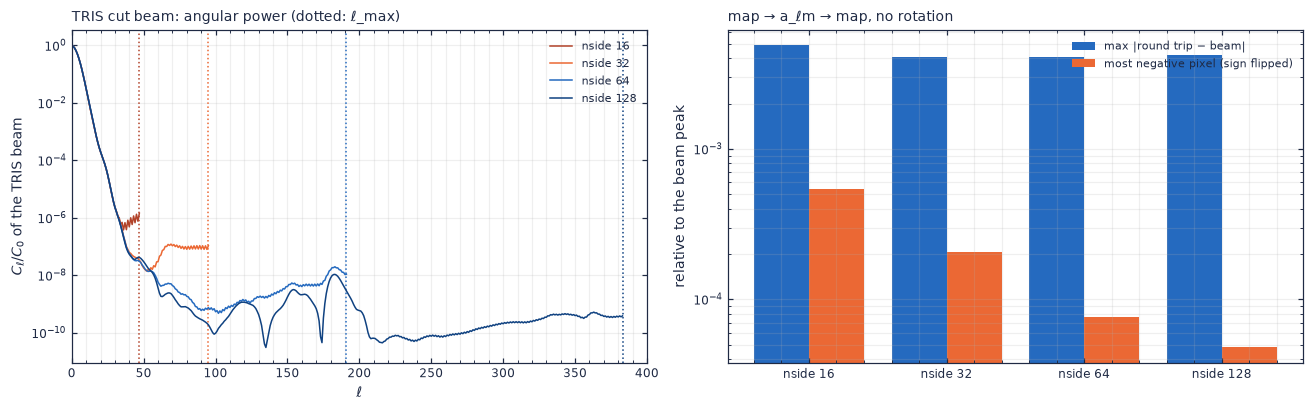

 nside  ℓmax   C(ℓmax)/C0    tail/C0   max err  min pixel
    16    47      1.4e-06    9.8e-07   4.9e-03   -5.4e-04
    32    95      1.1e-07    9.4e-08   4.1e-03   -2.1e-04
    64   191      1.1e-08    1.2e-08   4.1e-03   -7.7e-05
   128   383      3.8e-10    4.0e-10   4.2e-03   -4.8e-05


In [12]:
H2 = []
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
colours = {16: "#b2432a", 32: "#eb6834", 64: "#256abf", 128: "#104281"}
for ns in (16, 32, 64, 128):
    beam = tris.tris_cut_beam_map(H_CUTS, nside=ns, normalization="peak")
    alm = hp.map2alm(beam)
    cl = hp.alm2cl(alm)
    back = hp.alm2map(alm, ns)
    lmax = 3 * ns - 1
    H2.append(dict(nside=ns, lmax=lmax, cl_lmax=cl[-1] / cl[0], tail=float(cl[int(0.9 * lmax):].mean() / cl[0]),
                   max_err=float(np.max(np.abs(back - beam))), min_back=float(back.min())))
    ax.semilogy(np.arange(cl.size), cl / cl[0], color=colours[ns], label=f"nside {ns}")
    ax.axvline(lmax, color=colours[ns], ls=":")
ax.set_xlabel("ℓ"); ax.set_ylabel("$C_\\ell / C_0$ of the TRIS beam"); ax.set_xlim(0, 400)
ax.legend(); ax.grid(alpha=0.2, which="both")
ax.set_title("TRIS cut beam: angular power (dotted: ℓ_max)", loc="left")
x = np.arange(len(H2))
ax2.bar(x - 0.2, [h["max_err"] for h in H2], width=0.4, color="#256abf", label="max |round trip − beam|")
ax2.bar(x + 0.2, [-h["min_back"] for h in H2], width=0.4, color="#eb6834", label="most negative pixel (sign flipped)")
ax2.set_yscale("log"); ax2.set_xticks(x); ax2.set_xticklabels([f"nside {h['nside']}" for h in H2])
ax2.set_ylabel("relative to the beam peak"); ax2.legend(); ax2.grid(alpha=0.2, which="both")
ax2.set_title("map → a_ℓm → map, no rotation", loc="left")
plt.tight_layout(); plt.show()
print(f"{'nside':>6}{'ℓmax':>6}{'C(ℓmax)/C0':>13}{'tail/C0':>11}{'max err':>10}{'min pixel':>11}")
for h in H2:
    print(f"{h['nside']:6d}{h['lmax']:6d}{h['cl_lmax']:13.1e}{h['tail']:11.1e}{h['max_err']:10.1e}{h['min_back']:+11.1e}")

---
### H3. limTOD's pointed beam against the exact beam

One TRIS pointing (sample 60). **Left:** the beam limTOD uses: harmonically rotated
(H-c), with the harmonically rotated, thresholded horizon (H-d), normalised. **Middle:**
the same beam evaluated exactly in pixel space at the same nside, with
`elliptical_beam` (cut beam, E plane 7° east of north, zero beyond 90° from the zenith).
**Right:** limTOD − exact, as a percentage of the peak. Gnomonic views centred on the
zenith, 100° across.

This also tests the beam *orientation* the elliptical kernel assumes. The printout
repeats the comparison with the E plane at −7°; if +7° is right, its difference is much
smaller.

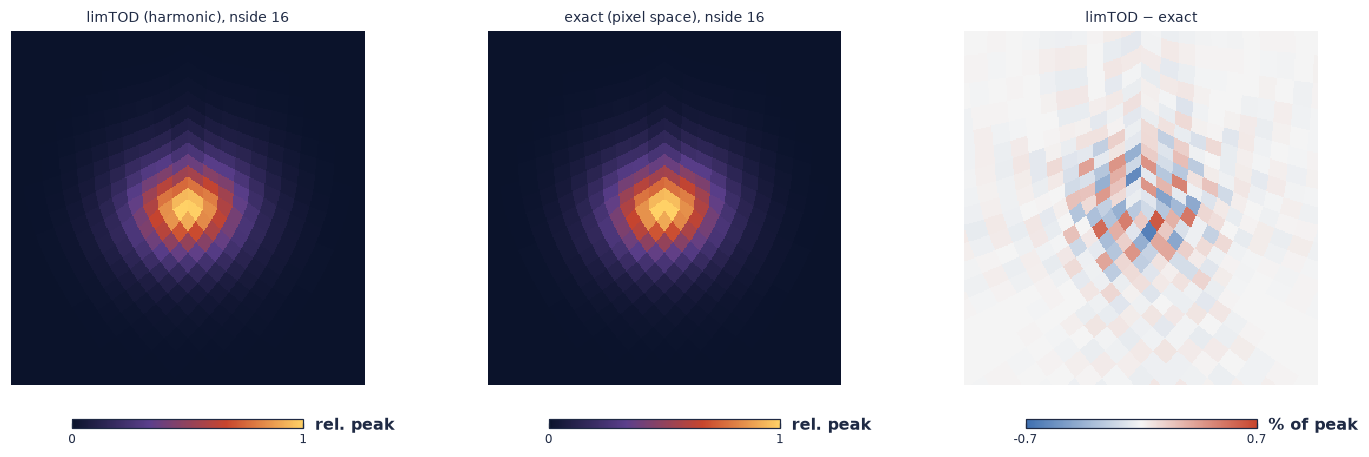

 nside E-plane PA  max |diff|  rms diff  neg. pixels  most neg.  kept: limTOD  exact
    16        +7°       0.62%    0.047%          348    -0.043%          1572   1536
    16        -7°       3.59%    0.310%          348    -0.043%          1572   1536
    32        +7°       1.11%    0.034%          486    -0.016%          6206   6144
    32        -7°       3.48%    0.303%          486    -0.016%          6206   6144
    64        +7°       0.71%    0.015%          922    -0.007%         24722  24576
    64        -7°       3.31%    0.300%          922    -0.007%         24722  24576
(percentages of the beam peak; 'kept' = pixels with non-zero weight, i.e. above the horizon)


In [13]:
k = 60
H3 = []
for ns in (16, 32, 64):
    beam_alm = hp.map2alm(tris.tris_cut_beam_map(H_CUTS, nside=ns, normalization="peak"))
    lim = pointing_beam_in_eq_sys(beam_alm, H_GEOM.lst_deg[k], H_GEOM.latitude_deg, H_GEOM.azimuth_deg[k],
                                  H_GEOM.elevation_deg[k], H_GEOM.selfrot_deg[k], nside=ns,
                                  normalize=True, horizontal_mask=tris.tris_horizon_mask(ns))
    centre = np.array(hp.ang2vec(H_GEOM.lst_deg[k], H_GEOM.latitude_deg, lonlat=True))[None, :]
    th, psi = eb.local_offsets(centre, np.array(hp.pix2vec(ns, np.arange(hp.nside2npix(ns)))).T)
    for pa in (7.0, -7.0):
        ex = eb.kernel_response(H_KERNEL, replace(H_SPEC, e_plane_east_of_meridian_deg=pa), th[:, 0], psi[:, 0])
        ex = ex / ex.sum()
        H3.append(dict(nside=ns, pa=pa, max_diff=float(np.max(np.abs(lim - ex)) / ex.max()),
                       rms_diff=float(np.std(lim - ex) / ex.max()), n_neg=int((lim < 0).sum()),
                       min_lim=float(lim.min() / ex.max()), kept_lim=int((lim != 0).sum()),
                       kept_exact=int((ex > 0).sum())))
        if ns == 16 and pa == 7.0:
            LIM16, EX16 = lim, ex

fig = plt.figure(figsize=(13, 4.0))
rot = (H_GEOM.lst_deg[k], H_GEOM.latitude_deg)
peak = EX16.max()
kw = dict(rot=rot, reso=20, xsize=300, fig=fig.number, notext=True)
hp.gnomview(LIM16 / peak, sub=(1, 3, 1), title="limTOD (harmonic), nside 16", min=0, max=1, unit="rel. peak", **kw)
hp.gnomview(EX16 / peak, sub=(1, 3, 2), title="exact (pixel space), nside 16", min=0, max=1, unit="rel. peak", **kw)
hp.gnomview(100 * (LIM16 - EX16) / peak, sub=(1, 3, 3), title="limTOD − exact", cmap=DIVB, min=-0.7, max=0.7,
            unit="% of peak", **kw)
plt.show()

print(f"{'nside':>6}{'E-plane PA':>11}{'max |diff|':>12}{'rms diff':>10}{'neg. pixels':>13}{'most neg.':>11}{'kept: limTOD':>14}{'exact':>7}")
for h in H3:
    print(f"{h['nside']:6d}{h['pa']:+10.0f}°{100 * h['max_diff']:11.2f}%{100 * h['rms_diff']:9.3f}%{h['n_neg']:13d}"
          f"{100 * h['min_lim']:+10.3f}%{h['kept_lim']:14d}{h['kept_exact']:7d}")
print("(percentages of the beam peak; 'kept' = pixels with non-zero weight, i.e. above the horizon)")

---
### H4. The consequence for the TODs

The question that matters for the TOD route: does the harmonic beam pointing change the
**data**? Haslam (in equatorial) is observed through the TRIS beam along the real ring
geometry, five ways:

| curve | beam | sky grid |
|---|---|---|
| limTOD, nside 16 | harmonic (H-c, H-d) — **what the pipeline does** | 16 |
| exact, nside 16 | exact pixel-space beam, hard horizon | 16 |
| limTOD, nside 64 | harmonic | 64 |
| exact, nside 64 | exact | 64 |
| **exact, nside 128** | exact — **the reference** | 128 |

Top: the TODs. Bottom: each minus the reference, in percent. Comparing limTOD with the
exact beam *on the same sky grid* isolates the harmonic step. Comparing nside 16 with 128
isolates the sky's pixelisation.

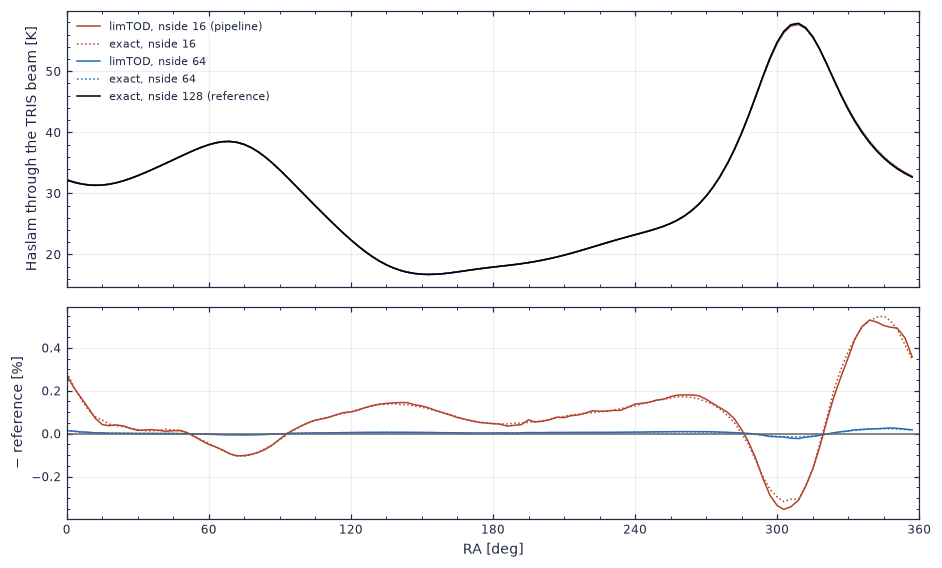

TOD                             vs reference: median   max |Δ|     rms
limTOD, nside 16 (pipeline)                  +0.073%    0.530%  0.165%
exact, nside 16                              +0.075%    0.547%  0.164%
limTOD, nside 64                             +0.004%    0.026%  0.008%
exact, nside 64                              +0.004%    0.023%  0.007%
exact, nside 128 (reference)                 +0.000%    0.000%  0.000%
harmonic step alone (limTOD vs exact on the same nside 16 sky): max |Δ| 0.043%
harmonic step alone (limTOD vs exact on the same nside 64 sky): max |Δ| 0.008%
[7 s]


In [14]:
def limtod_tod(sky, ns):
    beam = tris.tris_cut_beam_map(H_CUTS, nside=ns, normalization="peak")
    return np.asarray(generate_TOD_sky(beam, sky, H_GEOM.lst_deg, H_GEOM.latitude_deg, H_GEOM.azimuth_deg,
                                       H_GEOM.elevation_deg, H_GEOM.selfrot_deg, nside_hires=ns,
                                       normalize_beam=True, horizontal_mask=tris.tris_horizon_mask(ns)))

def exact_tod(sky):
    ns = hp.get_nside(sky)
    pts = np.array(hp.pix2vec(ns, np.arange(sky.size))).T
    out = np.empty(H_RA.size)
    for i in range(H_RA.size):
        c = np.array(hp.ang2vec(H_GEOM.lst_deg[i], H_GEOM.latitude_deg, lonlat=True))[None, :]
        th, psi = eb.local_offsets(c, pts)
        b = eb.kernel_response(H_KERNEL, H_SPEC, th[:, 0], psi[:, 0])
        out[i] = np.sum(b * sky) / np.sum(b)
    return out

t0 = time.time()
sky = {ns: hp.ud_grade(HASLAM_C, ns) for ns in (16, 64, 128)}
H4 = {"limTOD, nside 16 (pipeline)": limtod_tod(sky[16], 16),
      "exact, nside 16": exact_tod(sky[16]),
      "limTOD, nside 64": limtod_tod(sky[64], 64),
      "exact, nside 64": exact_tod(sky[64]),
      "exact, nside 128 (reference)": exact_tod(sky[128])}
ref = H4["exact, nside 128 (reference)"]
style = {"limTOD, nside 16 (pipeline)": ("#b2432a", "-"), "exact, nside 16": ("#b2432a", ":"),
         "limTOD, nside 64": ("#256abf", "-"), "exact, nside 64": ("#256abf", ":"),
         "exact, nside 128 (reference)": ("k", "-")}
fig, (ax, axd) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw=dict(height_ratios=[1.3, 1], hspace=0.08))
for name, tod in H4.items():
    c, ls = style[name]
    ax.plot(H_RA, tod, ls, color=c, label=name)
    if "reference" not in name:
        axd.plot(H_RA, 100 * (tod / ref - 1), ls, color=c)
axd.axhline(0, color="0.4")
ax.set_ylabel("Haslam through the TRIS beam [K]"); ax.legend()
axd.set_ylabel("− reference [%]"); axd.set_xlabel("RA [deg]")
for a in (ax, axd):
    a.set_xlim(0, 360); a.set_xticks(np.arange(0, 361, 60)); a.grid(alpha=0.2)
plt.show()

print(f"{'TOD':<30}{'vs reference: median':>22}{'max |Δ|':>10}{'rms':>8}")
for name, tod in H4.items():
    d = 100 * (tod / ref - 1)
    print(f"{name:<30}{np.median(d):+21.3f}%{np.max(np.abs(d)):9.3f}%{np.std(d):7.3f}%")
for ns in (16, 64):
    d = 100 * (H4[[n for n in H4 if n.startswith(f"limTOD, nside {ns}")][0]] / H4[f"exact, nside {ns}"] - 1)
    print(f"harmonic step alone (limTOD vs exact on the same nside {ns} sky): max |Δ| {np.max(np.abs(d)):.3f}%")
print(f"[{time.time() - t0:.0f} s]")

---
### H5. Haslam's harmonic rotation (H-a)

Haslam is the one map rotated in harmonic space: full sky, nside 512, ℓ_max 1535. Its own
56′ beam is ~4 pixels wide, so its a_ℓm do not reach zero by ℓ_max (H1). The comment
predicts ringing, and the round trip G → C → G shows it:

* **Left:** the round-trip residual (back − original), ±0.5 K.
* **Middle:** a 20° gnomonic zoom on the pixel with the largest residual. Ringing around a
  bright compact source looks like concentric rings.
* **Right:** the residual's $C_\ell$ against Haslam's. The residual lives at the highest ℓ.

**Does it survive into what the analysis uses?** The products are smoothed to the TRIS beam
and put on nside 16. A smoothed map *is* band-limited, so smoothing **first** and rotating
**after** cannot ring. The printout compares the nside 16 product made both ways: rotate
then smooth (the pipeline) against smooth then rotate. It also includes pixel-space
rotation.

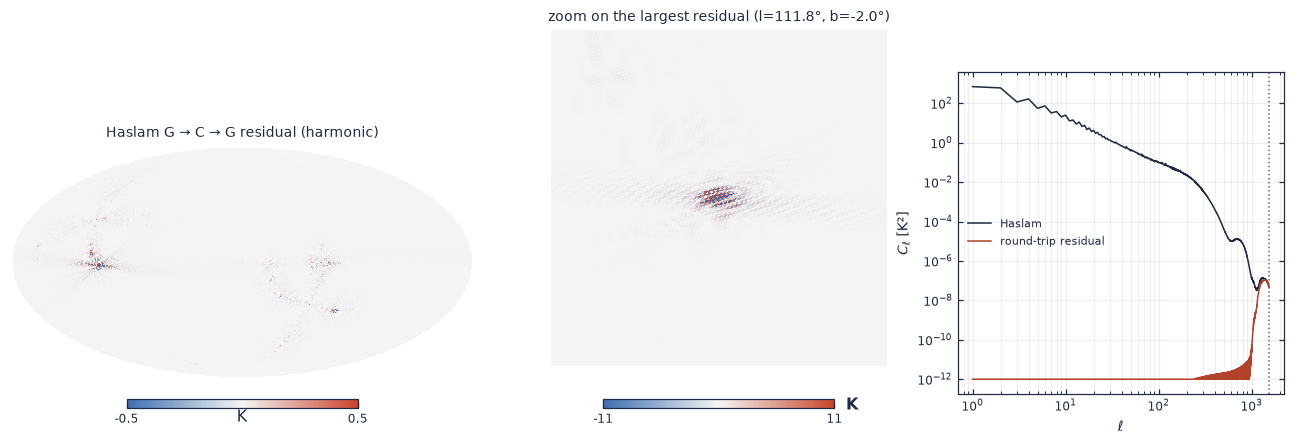

round trip: rms 0.080 K (0.23% of the mean); largest +33.0 K on a 4779 K pixel (l=111.8°, b=-2.0°); 490 pixels off by more than 1 K
nside 16 product, rotate (harmonic) → smooth  [pipeline]             vs smooth→rotate: max |Δ| 5.4e-05%, rms 6.3e-06%
nside 16 product, smooth → rotate (harmonic)  [band-limited first]   vs smooth→rotate: max |Δ| 0.0e+00%, rms 0.0e+00%
nside 16 product, rotate (pixel) → smooth                            vs smooth→rotate: max |Δ| 7.2e-04%, rms 1.8e-04%
[32 s]


In [15]:
t0 = time.time()
back = frames.rotate_full_sky(HASLAM_C, ("C", "G"))
resid = back - HASLAM_G
worst = int(np.argmax(np.abs(resid)))
lon_w, lat_w = hp.pix2ang(512, worst, lonlat=True)
cl_h = hp.anafast(HASLAM_G - HASLAM_G.mean())
cl_r = hp.anafast(resid)

fig = plt.figure(figsize=(13, 3.8))
hp.mollview(resid, sub=(1, 3, 1), fig=fig.number, cmap=DIVB, min=-0.5, max=0.5, unit="K",
            title="Haslam G → C → G residual (harmonic)", notext=True)
hp.gnomview(resid, rot=(lon_w, lat_w), reso=2.0, xsize=600, sub=(1, 3, 2), fig=fig.number, cmap=DIVB,
            min=-np.abs(resid[worst]) / 3, max=np.abs(resid[worst]) / 3, unit="K",
            title=f"zoom on the largest residual (l={lon_w:.1f}°, b={lat_w:.1f}°)", notext=True)
ax = fig.add_subplot(1, 3, 3)
ell = np.arange(cl_h.size)
ax.loglog(ell[1:], cl_h[1:], color=COLORS["ink"], label="Haslam")
ax.loglog(ell[1:], np.maximum(cl_r[1:], 1e-12), color="#b2432a", label="round-trip residual")
ax.axvline(3 * 512 - 1, color="0.4", ls=":")
ax.set_xlabel("ℓ"); ax.set_ylabel("$C_\\ell$ [K²]"); ax.legend(); ax.grid(alpha=0.2, which="both")
plt.show()
print(f"round trip: rms {resid.std():.3f} K ({100 * resid.std() / HASLAM_G.mean():.2f}% of the mean); largest "
      f"{resid[worst]:+.1f} K on a {HASLAM_G[worst]:.0f} K pixel (l={lon_w:.1f}°, b={lat_w:.1f}°); "
      f"{int((np.abs(resid) > 1).sum())} pixels off by more than 1 K")

# Does it reach the nside 16 product?
ones = np.ones(HASLAM_G.size, bool)
prod = {}
prod["rotate (harmonic) → smooth  [pipeline]"] = smooth_to_target(HASLAM_C, HASLAM_NATIVE, TARGET_FWHM)
prod["smooth → rotate (harmonic)  [band-limited first]"] = frames.rotate_full_sky(
    smooth_to_target(HASLAM_G, HASLAM_NATIVE, TARGET_FWHM), ("G", "C"))
prod["rotate (pixel) → smooth"] = smooth_to_target(hp.Rotator(coord=["G", "C"]).rotate_map_pixel(HASLAM_G),
                                                   HASLAM_NATIVE, TARGET_FWHM)
p16 = {name: regrid_to_nside(v, ones, 16)[0] for name, v in prod.items()}
ref16 = p16["smooth → rotate (harmonic)  [band-limited first]"]
for name, v in p16.items():
    d = 100 * (v / ref16 - 1)
    print(f"nside 16 product, {name:<50} vs smooth→rotate: max |Δ| {np.max(np.abs(d)):.1e}%, rms {np.std(d):.1e}%")
print(f"[{time.time() - t0:.0f} s]")

---
### H6. Harmonic smoothing against the exact real-space Gaussian (H-b)

`hp.smoothing` applies the Gaussian as a window in ℓ. The same smoothing can be done
without any harmonics: a direct sum with a Gaussian of the same FWHM in angle
(`elliptical_beam`, `circular_gaussian`). That uses the same normalised convolution, a
0.92° working grid and 2×2 evaluation points per nside 16 pixel. Any ringing, truncation
or aliasing in the harmonic version would show up as a difference.

Two expected, non-ringing differences:

* a Gaussian in ℓ is ~0.25% wider in angle than a Gaussian in angle at 23° (Part K1);
* the two versions average into nside 16 pixels differently.

Both are a fraction of a percent.

* **Haslam** (full sky, the raw map not band-limited, H1): left, the difference map; middle,
  its histogram.
* **ARCADE 2 3.15 GHz** (thin masked ring, zero-filled, nside 16 = ℓ_max 47, the hardest
  case for H-b): right, harmonic against real space on the pixels both keep.

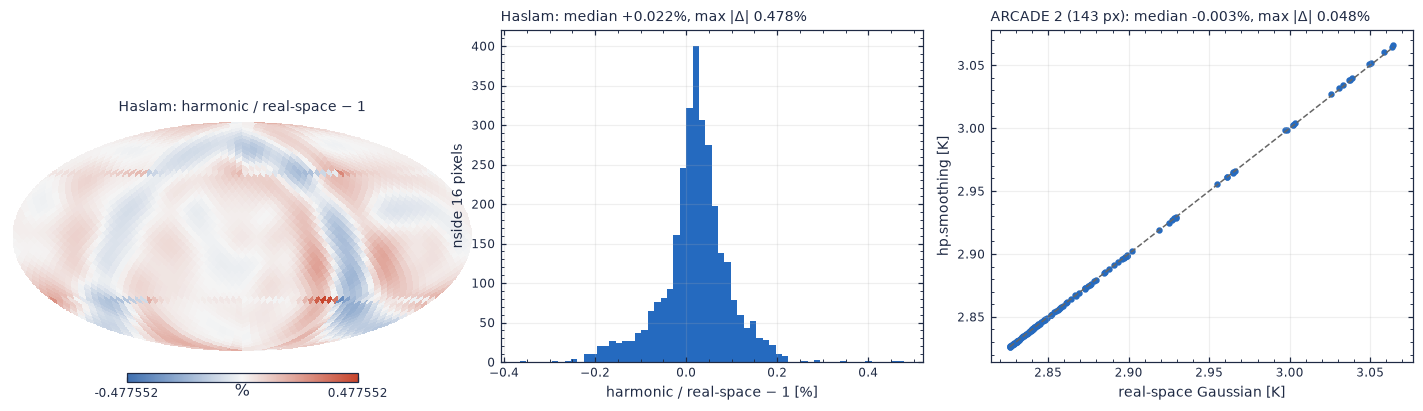

Haslam   harmonic vs real space: median +0.022%, max |Δ| 0.478%, rms 0.075%
ARCADE 2 harmonic vs real space: median -0.003%, max |Δ| 0.048%
[72 s]


In [16]:
t0 = time.time()
spec_circ = eb.with_kernel(H_SPEC, "circular_gaussian")
has_harm = regrid_to_nside(smooth_to_target(HASLAM_C, HASLAM_NATIVE, TARGET_FWHM), ones, 16)[0]
has_real = eb.smooth_elliptical(HASLAM_C, ones, HASLAM_NATIVE, spec_circ, 16)["values"]
d_has = 100 * (has_harm / has_real - 1)

arc = hp.read_map(config.resolve_path("paths.arcade2_map_3150"))
arc_obs = observed_mask(arc, "zeros")
arc_rot, arc_obs_rot, _ = frames.rotate_masked(arc, arc_obs, ("G", "C"))
arc_native = float(config.require("beam_matching.arcade2_native_fwhm_deg"))
arc_harm = smooth_to_target(np.where(arc_obs_rot, arc_rot, 0.0), arc_native, TARGET_FWHM,
                            weight_mask=arc_obs_rot, weight_floor=0.5)
arc_real = eb.smooth_elliptical(arc_rot, arc_obs_rot, arc_native, spec_circ, 16)
both = (arc_harm != hp.UNSEEN) & arc_obs_rot & (arc_real["weight_min"] >= 0.5)
d_arc = 100 * (arc_harm[both] / arc_real["values"][both] - 1)

fig = plt.figure(figsize=(13, 3.8))
span = float(np.max(np.abs(d_has)))
hp.mollview(d_has, sub=(1, 3, 1), fig=fig.number, cmap=DIVB, min=-span, max=span, unit="%",
            title="Haslam: harmonic / real-space − 1", notext=True)
ax = fig.add_subplot(1, 3, 2)
ax.hist(d_has, bins=60, color="#256abf"); ax.set_xlabel("harmonic / real-space − 1 [%]"); ax.set_ylabel("nside 16 pixels")
ax.set_title(f"Haslam: median {np.median(d_has):+.3f}%, max |Δ| {np.max(np.abs(d_has)):.3f}%", loc="left")
ax.grid(alpha=0.2)
ax = fig.add_subplot(1, 3, 3)
ax.scatter(arc_real["values"][both], arc_harm[both], s=10, color="#256abf")
lim = [arc_real["values"][both].min(), arc_real["values"][both].max()]
ax.plot(lim, lim, "--", color="0.4")
ax.set_xlabel("real-space Gaussian [K]"); ax.set_ylabel("hp.smoothing [K]")
ax.set_title(f"ARCADE 2 ({both.sum()} px): median {np.median(d_arc):+.3f}%, max |Δ| {np.max(np.abs(d_arc)):.3f}%",
             loc="left")
ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()
print(f"Haslam   harmonic vs real space: median {np.median(d_has):+.3f}%, max |Δ| {np.max(np.abs(d_has)):.3f}%, rms {np.std(d_has):.3f}%")
print(f"ARCADE 2 harmonic vs real space: median {np.median(d_arc):+.3f}%, max |Δ| {np.max(np.abs(d_arc)):.3f}%")
print(f"[{time.time() - t0:.0f} s]")

---
### Summary: response to the comment (run 2026-10-14)

**The concern is valid in principle, and two of the four harmonic operations do act on fields
that are not band-limited. The measured consequence for every product the analysis uses
is ≤ 0.05%, and ≤ 0.5% where it is not ringing at all.**

| # | operation | a_ℓm → 0 before ℓ_max? | measured effect on what the analysis uses | verdict |
|---|---|---|---|---|
| H-a | Haslam G → C, `rotate_map_alms`, ℓ_max 1535 | **no**: raw tail/peak 1.5×10⁻¹⁰ (H1), pixel-limited | round trip 0.08 K rms, but **33 K ringing at Cas A** (on a 4779 K pixel), 490 pixels off by > 1 K (H5). In the nside 16 smoothed product: **5×10⁻⁵ %** against smooth-then-rotate | ringing real at full resolution, removed by the 23° smoothing. **A full-resolution product would inherit it**: rotating the raw nside 512 map with `rotate_map_alms` and keeping it at full resolution carries the Cas A / Cyg A / Galactic-centre ringing; nothing in the pipeline does this |
| H-b | circular smoothing, `hp.smoothing` | input no (raw tails, mask edges); **output yes**, tail/peak 10⁻¹¹–10⁻¹⁶ by ℓ ≈ 35 (H1) | against an exact real-space Gaussian: ARCADE 2 (masked, ℓ_max 47) **0.05%** max; Haslam 0.5% max, 0.08% rms, with the pattern of the known ~0.25% harmonic-vs-angular Gaussian width difference, not ringing (H6) | safe |
| H-c | limTOD beam pointing, `map2alm`/`rotate_alm` at nside 16, ℓ_max 47 | **marginal**: beam C_ℓ(ℓ_max)/C₀ = 1.4×10⁻⁶, turning **up** before ℓ_max (aliasing); round trip makes negative pixels at −0.05% of peak (H2) | pointed beam within 0.6% of peak of the exact beam (H3); **TODs within 0.043%** of the exact pixel-space beam on the same sky (H4) | safe at the analysis's precision; improves to 0.008% at nside 64 |
| H-d | limTOD horizon mask, same path, thresholded | **no**: a step function | 36 extra pixels at the horizon at nside 16 (1572 vs 1536), included in H4's 0.043% | safe |

**What dominates instead.** The sky's own **pixelisation at nside 16** moves the TODs by up
to **0.53%** (0.17% rms) against an nside 128 reference, ten times more than every harmonic
step combined. It falls to 0.026% at nside 64 (H4). This is the same nside 16 limit
Part K1 found for the beam (Test 2).

**Recommendations**

1. **For any full-resolution product**, rotate the raw nside 512 map in **pixel space**, or leave Haslam in Galactic
   and rotate a smooth nside 16 correction into Galactic instead (band-limited, so its rotation cannot ring). Do not
   use `rotate_map_alms` on the raw nside 512 map anywhere the full-resolution result is kept.
2. Move the TOD route and stage 1 to `tris.nside_hires` = 64 (and the TOD sky grid to 64).
   That fixes both the aliasing in H2 and the 0.5% pixelisation effect, at a few times the
   cost.
3. The default elliptical kernel (`tris_cuts`) is a direct sum in pixel space, so H-b does
   not arise for it at all. H-b applies only to `circular_gaussian`.

All numbers above are printed by the cells in this section.

---
## Convolve → deconvolve with limTOD: do the maps come back?

**The check.** Convolve each map with a beam using limTOD, deconvolve it again with limTOD,
and see whether the original comes back. Do it twice:

* with a **circular Gaussian**, 23.366° FWHM;
* with an **elliptical Gaussian** with TRIS's specifications: 19.155° (E) × 23.366° (H),
  pointed as TRIS points (zenith, E plane rolled 7° east of the meridian).

Then compare what the two beams give, convolved and deconvolved.

**How, entirely with limTOD's own functions:**

1. **The beams:** `limTOD.tris.approximate_tris_gaussian_beam_map`, at nside 16 (the
   analysis grid), circular (23.366 × 23.366) and elliptical (19.155 × 23.366).
2. **Convolution = observing.** For every one of the 3072 nside 16 pixels, limTOD's
   `pointing_beam_in_eq_sys` points the beam at that pixel's centre: a zenith pointing at
   LST = RA and latitude = Dec, `selfrot` = −7° (TRIS's roll), with TRIS's horizon mask.
   This is exactly the call `generate_TOD_sky` makes for every TOD sample, and the cell
   checks that the two agree. The pointed, normalised beams are the rows of a
   3072 × 3072 operator **A**, and the convolved map is **c = A s**. One convolved value
   per pixel is a full-sky "TOD" that samples every pixel once.
3. **Deconvolution = map-making.** limTOD's `wiener_filter_map`, the solver stage 1 and the
   TOD route use, recovers $\hat s = (A^\mathsf{T}N^{-1}A + S^{-1})^{-1}(A^\mathsf{T}N^{-1}d + S^{-1}\mu)$
   from **d = c + noise**:
   * noise $N$: Gaussian, σ = a fraction of each convolved value, at three levels:
     10⁻² (1%), 10⁻⁴ (0.01%, about the TRIS rings' statistical error relative to the sky)
     and 10⁻⁶;
   * a deliberately weak prior: $\mu$ = the convolved map's mean, $S$ = (the map's mean)²
     on the diagonal. It only stops the solve from blowing up in modes the data cannot
     see.

**What to expect.** A beam multiplies each spherical harmonic by $b_\ell$, about
$\exp[-\ell(\ell+1)\sigma^2/2]$. For σ ≈ 10° that is 10⁻¹⁰ by ℓ ≈ 40. Deconvolution divides
by it, so any noise at those scales is amplified by up to 10¹⁰. **The large scales should
come back exactly and the small ones should not.** Where the crossover lies depends on the
noise level and on the beam: the elliptical beam is narrower north–south, so it should
keep a little more. The plots below measure where it lies.

operators built in 8 s
circular 23.366°               generate_TOD_sky vs A @ s on the Dec +41.8° ring: max relative difference 4.4e-16
elliptical 19.155° × 23.366°   generate_TOD_sky vs A @ s on the Dec +41.8° ring: max relative difference 4.4e-16


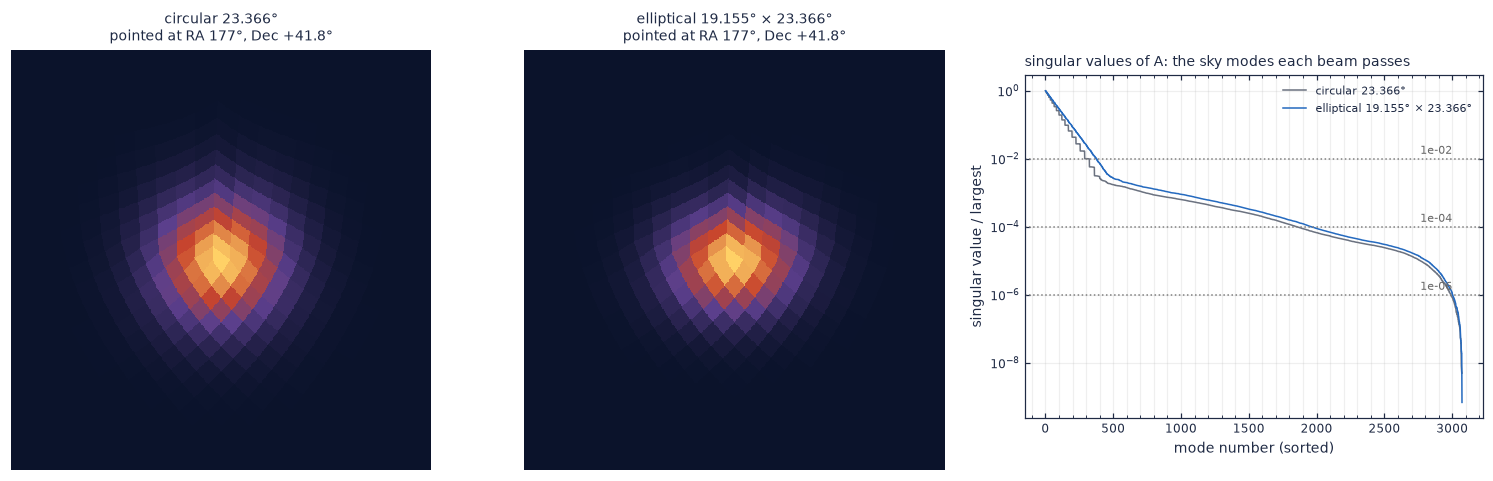

circular 23.366°               modes above 1e-2 / 1e-4 / 1e-6 of the largest: 320 / 1855 / 2988 of 3072
elliptical 19.155° × 23.366°   modes above 1e-2 / 1e-4 / 1e-6 of the largest: 377 / 1959 / 3001 of 3072


In [17]:
# Build the two beam operators with limTOD (about 80 s per beam).
from limTOD import generate_TOD_sky
from limTOD.simulator import pointing_beam_in_eq_sys
from limTOD.HPW_filter import wiener_filter_map

D_NS = 16
D_NPIX = hp.nside2npix(D_NS)
D_ROLL = -tris.TRIS_E_PLANE_EAST_OF_MERIDIAN_DEG          # limTOD's selfrot for TRIS
D_RA, D_DEC = hp.pix2ang(D_NS, np.arange(D_NPIX), lonlat=True)
D_HORIZON = tris.tris_horizon_mask(D_NS)
D_BEAMS = {
    "circular 23.366°": tris.approximate_tris_gaussian_beam_map(nside=D_NS, fwhm_e_deg=23.366, fwhm_h_deg=23.366),
    "elliptical 19.155° × 23.366°": tris.approximate_tris_gaussian_beam_map(nside=D_NS, fwhm_e_deg=19.155, fwhm_h_deg=23.366),
}
D_COL = {"circular 23.366°": "#6b7280", "elliptical 19.155° × 23.366°": "#256abf"}

def beam_operator(beam):
    # Row p = limTOD's beam pointed at pixel p's centre (zenith pointing at LST = RA, latitude = Dec).
    alm = hp.map2alm(beam)
    A = np.empty((D_NPIX, D_NPIX))
    for p in range(D_NPIX):
        A[p] = pointing_beam_in_eq_sys(alm, D_RA[p], D_DEC[p], 0.0, 90.0, D_ROLL, nside=D_NS,
                                       normalize=True, horizontal_mask=D_HORIZON)
    return A

t0 = time.time()
D_A = {name: beam_operator(beam) for name, beam in D_BEAMS.items()}
print(f"operators built in {time.time() - t0:.0f} s")

# The input: Haslam in equatorial on nside 16 (H5's harmonic rotation, then averaged).
D_HASLAM = hp.ud_grade(HASLAM_C, D_NS)

# Check: A @ s is exactly what generate_TOD_sky returns for the same pointings (one ring of pixels).
ring = np.flatnonzero(np.isclose(D_DEC, D_DEC[np.argmin(np.abs(D_DEC - 42.4))]))
for name, beam in D_BEAMS.items():
    tod = np.asarray(generate_TOD_sky(beam, D_HASLAM, D_RA[ring], D_DEC[ring[0]], np.zeros(ring.size),
                                      np.full(ring.size, 90.0), np.full(ring.size, D_ROLL), nside_hires=D_NS,
                                      normalize_beam=True, horizontal_mask=D_HORIZON))
    print(f"{name:<30} generate_TOD_sky vs A @ s on the Dec {D_DEC[ring[0]]:+.1f}° ring: "
          f"max relative difference {np.max(np.abs(tod / (D_A[name][ring] @ D_HASLAM) - 1)):.1e}")

# Singular values of A: how many independent sky modes each beam passes, and how strongly.
D_SV = {name: np.linalg.svd(A, compute_uv=False) for name, A in D_A.items()}
fig = plt.figure(figsize=(14, 3.9))
p0 = int(np.argmin(np.hypot(D_RA - 180.0, D_DEC - 42.4)))
for k, (name, A) in enumerate(D_A.items()):
    hp.gnomview(A[p0] / A[p0].max(), rot=(D_RA[p0], D_DEC[p0]), reso=12, xsize=500, sub=(1, 3, k + 1),
                fig=fig.number, min=0, max=1,
                title=f"{name}\npointed at RA {D_RA[p0]:.0f}°, Dec {D_DEC[p0]:+.1f}°", notext=True, cbar=False)
ax = fig.add_subplot(1, 3, 3)
for name, sv in D_SV.items():
    ax.semilogy(np.arange(1, sv.size + 1), sv / sv[0], color=D_COL[name], label=name)
for level in (1e-2, 1e-4, 1e-6):
    ax.axhline(level, color="0.5", ls=":")
    ax.text(3000, level * 1.4, f"{level:.0e}", fontsize=7, ha="right", color="0.4")
ax.set_xlabel("mode number (sorted)"); ax.set_ylabel("singular value / largest")
ax.set_title("singular values of A: the sky modes each beam passes", loc="left")
ax.legend(); ax.grid(alpha=0.2, which="both")
plt.tight_layout(); plt.show()
for name, sv in D_SV.items():
    print(f"{name:<30} modes above 1e-2 / 1e-4 / 1e-6 of the largest: "
          f"{(sv > 1e-2 * sv[0]).sum()} / {(sv > 1e-4 * sv[0]).sum()} / {(sv > 1e-6 * sv[0]).sum()} of {D_NPIX}")

**Reading the operators.** The pointed beams (left) are the beams the TOD route uses, and
**A s** is exactly limTOD's `generate_TOD_sky` (the printed difference is at machine
precision). The singular values (right) are the deconvolution problem in one picture. A
mode whose singular value is below the noise level relative to the largest cannot be
recovered: its signal is smaller than the noise, and dividing by it amplifies the noise.
The elliptical beam's curve sits above the circular one, so it passes more modes at every
noise level, because its narrow axis keeps more north–south structure.

beam                          map                         rms vs input   max |Δ|  rms in TRIS stripe
circular 23.366°              convolved                         17.68%     80.9%              14.25%
circular 23.366°              deconvolved, noise 1e-02          23.21%    115.2%              20.65%
circular 23.366°              deconvolved, noise 1e-04          38.77%    181.6%              37.01%
circular 23.366°              deconvolved, noise 1e-06          14.44%     73.4%              14.98%
elliptical 19.155° × 23.366°  convolved                         16.84%     79.8%              13.33%
elliptical 19.155° × 23.366°  deconvolved, noise 1e-02          24.82%     95.7%              22.72%
elliptical 19.155° × 23.366°  deconvolved, noise 1e-04          36.45%    163.7%              34.11%
elliptical 19.155° × 23.366°  deconvolved, noise 1e-06          13.76%     79.6%              13.40%


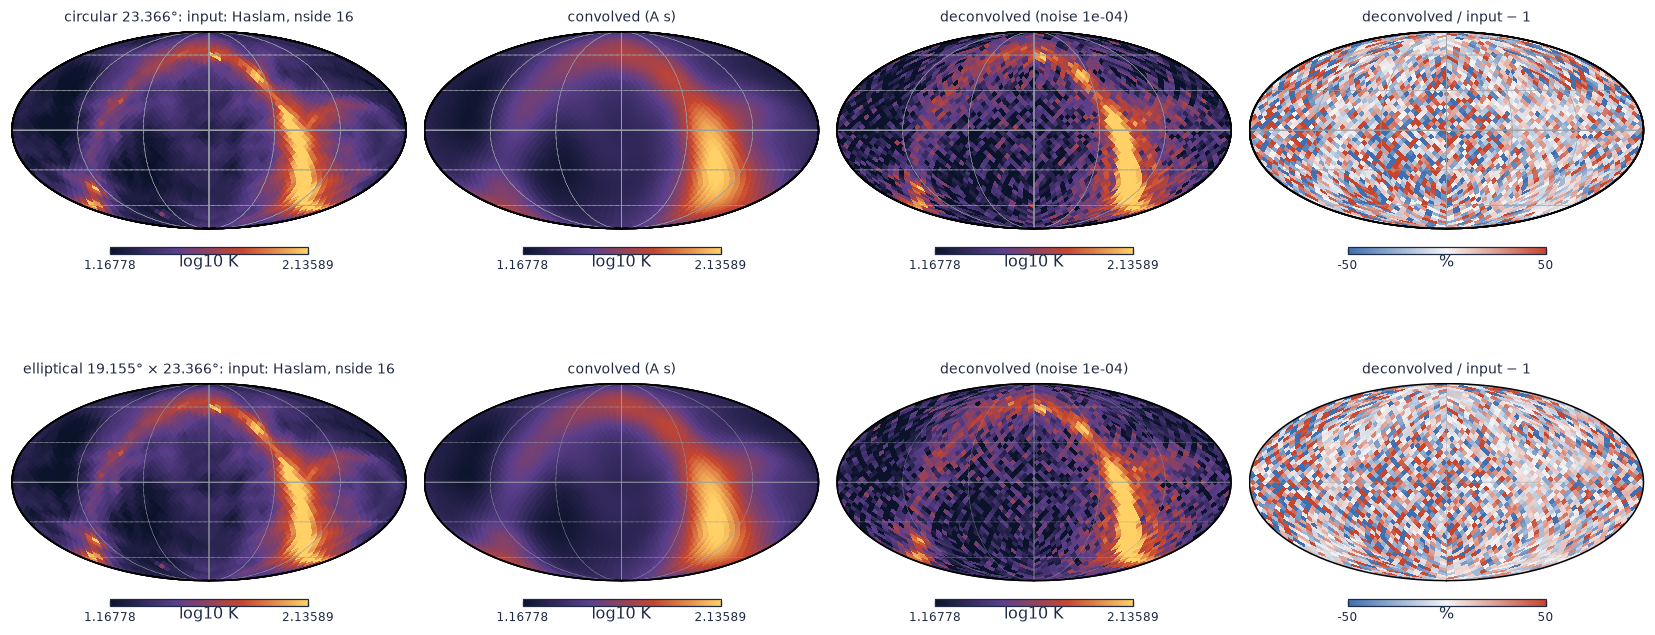

In [18]:
# Convolve and deconvolve Haslam with both beams, at three noise levels.
D_NOISE = (1e-2, 1e-4, 1e-6)
rng = np.random.default_rng(14)
D_CONV, D_DECONV = {}, {}
for name, A in D_A.items():
    c = A @ D_HASLAM
    D_CONV[name] = c
    for rel in D_NOISE:
        sigma = rel * np.abs(c)
        data = c + rng.normal(0.0, 1.0, c.size) * sigma
        x, _ = wiener_filter_map(data, A, noise_variance=sigma ** 2,
                                 prior_inv_cov=1.0 / D_HASLAM.mean() ** 2, guess=np.full(D_NPIX, c.mean()))
        D_DECONV[name, rel] = x

D_BAND = load_stage1(config)["band_mask"].astype(bool)
def pct(a, b):
    return 100 * (a / b - 1)
print(f"{'beam':<30}{'map':<26}{'rms vs input':>14}{'max |Δ|':>10}{'rms in TRIS stripe':>20}")
for name in D_A:
    for label, m in [("convolved", D_CONV[name])] + [(f"deconvolved, noise {rel:.0e}", D_DECONV[name, rel]) for rel in D_NOISE]:
        d = pct(m, D_HASLAM)
        print(f"{name:<30}{label:<26}{np.std(d):13.2f}%{np.max(np.abs(d)):9.1f}%{np.std(d[D_BAND]):19.2f}%")

REL = 1e-4      # the noise level shown in the maps below
lo, hi = np.percentile(D_HASLAM, [2, 98])
fig = plt.figure(figsize=(15, 6.4))
for row, name in enumerate(D_A):
    panels = [("input: Haslam, nside 16", np.log10(D_HASLAM), SEQB, np.log10(lo), np.log10(hi), "log10 K"),
              ("convolved (A s)", np.log10(D_CONV[name]), SEQB, np.log10(lo), np.log10(hi), "log10 K"),
              (f"deconvolved (noise {REL:.0e})", np.log10(np.clip(D_DECONV[name, REL], lo / 10, None)), SEQB,
               np.log10(lo), np.log10(hi), "log10 K"),
              ("deconvolved / input − 1", pct(D_DECONV[name, REL], D_HASLAM), DIVB, -50, 50, "%")]
    for col, (title, m, cmap, a, b, unit) in enumerate(panels):
        hp.mollview(m, sub=(2, 4, 4 * row + col + 1), fig=fig.number, cmap=cmap, min=a, max=b, unit=unit,
                    title=f"{name}: {title}" if col == 0 else title, notext=True)
        hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.3)
plt.show()

**Reading the maps.** In the convolved maps (2nd column) the plane is smeared over 20°, and
the elliptical one is visibly sharper north–south. The deconvolved maps (3rd column)
restore the plane's width and the bright regions. The difference (4th column) is not a
smooth error but **pixel-scale noise**: modes the beam suppressed below the noise come back
as amplified noise, not as sky. The table above gives the numbers, for the whole sky and
for the TRIS stripe.

---
### The difference between the two beams

**Top row:** elliptical minus circular, in percent of the **input** map. Left, convolved:
the effect of the beam *shape* on what an instrument sees, or on what stage 2 hands the SED
fit. Middle, deconvolved: what is left after map-making, at noise 10⁻⁴. Right, the
deconvolved difference after smoothing both to 10°, the scale the deconvolution actually
preserves (next section).

The percentage is of the input, not of one of the outputs: a deconvolved map is noisy
enough to pass through zero in places, and dividing by it would blow the ratio up.

**Bottom row:** each map against the input, for both beams. Left, convolved; right,
deconvolved (noise 10⁻⁴). These are pixel histograms of map / input − 1.

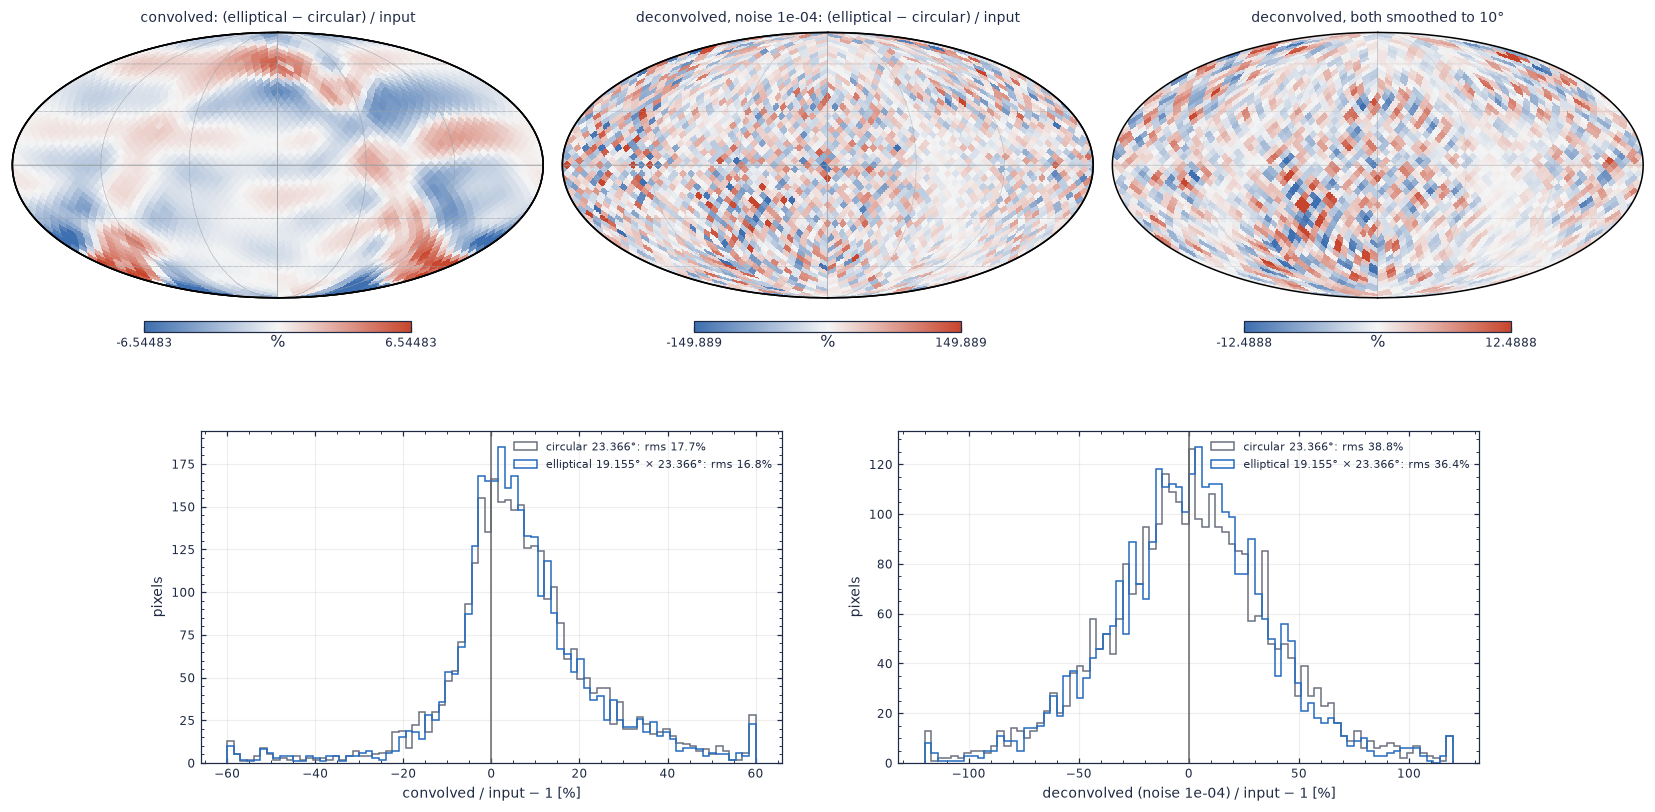

convolved                    (elliptical − circular)/input: rms   1.92%, max |Δ|   11.5%, TRIS stripe rms   1.76%
deconvolved, noise 1e-04     (elliptical − circular)/input: rms  50.32%, max |Δ|  238.4%, TRIS stripe rms  48.18%
deconvolved, both at 10°     (elliptical − circular)/input: rms   4.16%, max |Δ|   24.7%, TRIS stripe rms   3.90%


In [19]:
names = list(D_A)
sm10 = lambda v: hp.smoothing(v, fwhm=np.radians(10.0), iter=3)
d_conv = 100 * (D_CONV[names[1]] - D_CONV[names[0]]) / D_HASLAM
d_dec = 100 * (D_DECONV[names[1], REL] - D_DECONV[names[0], REL]) / D_HASLAM
d_dec10 = 100 * (sm10(D_DECONV[names[1], REL]) - sm10(D_DECONV[names[0], REL])) / sm10(D_HASLAM)
fig = plt.figure(figsize=(15, 8.4))
for k, (d, title) in enumerate(((d_conv, "convolved: (elliptical − circular) / input"),
                                (d_dec, f"deconvolved, noise {REL:.0e}: (elliptical − circular) / input"),
                                (d_dec10, "deconvolved, both smoothed to 10°"))):
    span = float(np.percentile(np.abs(d), 99))
    hp.mollview(d, sub=(2, 3, k + 1), fig=fig.number, cmap=DIVB, min=-span, max=span, unit="%",
                title=title, notext=True)
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.3)
for k, (label, getter, bins) in enumerate((("convolved", lambda n: D_CONV[n], np.linspace(-60, 60, 81)),
                                            (f"deconvolved (noise {REL:.0e})", lambda n: D_DECONV[n, REL], np.linspace(-120, 120, 81)))):
    ax = fig.add_subplot(2, 2, 3 + k)
    for name in names:
        d = pct(getter(name), D_HASLAM)
        ax.hist(np.clip(d, bins[0], bins[-1]), bins=bins, histtype="step", color=D_COL[name],
                label=f"{name}: rms {np.std(d):.1f}%")
    ax.axvline(0, color="0.4")
    ax.set_xlabel(f"{label} / input − 1 [%]"); ax.set_ylabel("pixels")
    ax.legend(); ax.grid(alpha=0.2)
plt.subplots_adjust(hspace=0.45, top=0.95, bottom=0.07)
plt.show()
for label, d in (("convolved", d_conv), (f"deconvolved, noise {REL:.0e}", d_dec), ("deconvolved, both at 10°", d_dec10)):
    print(f"{label:<28} (elliptical − circular)/input: rms {np.std(d):6.2f}%, max |Δ| {np.max(np.abs(d)):6.1f}%, "
          f"TRIS stripe rms {np.std(d[D_BAND]):6.2f}%")

---
### Which scales come back

The question "has the map changed?" has a different answer at every angular scale.

* **Left: the transfer function** $C_\ell(\hat s)/C_\ell(s)$: how much power the
  deconvolved map has at each ℓ relative to the input. 1 means the power is restored; above
  1 means noise has been added. The convolved maps (dashed) show the beam's own
  suppression, $\approx b_\ell^2$.
* **Middle: the correlation** $r_\ell = C_\ell(\hat s, s)/\sqrt{C_\ell(\hat s)C_\ell(s)}$:
  whether the structure at each ℓ is the *right* structure. The dotted line is r = 0.9.
* **Right: by angular scale in the map.** Both the deconvolved map and the input are
  smoothed with a Gaussian of the FWHM on the x axis, and the rms of their ratio is plotted.
  The error at a given resolution is where the curve sits; the scale where it drops below a
  few percent is the resolution the round trip actually preserves.

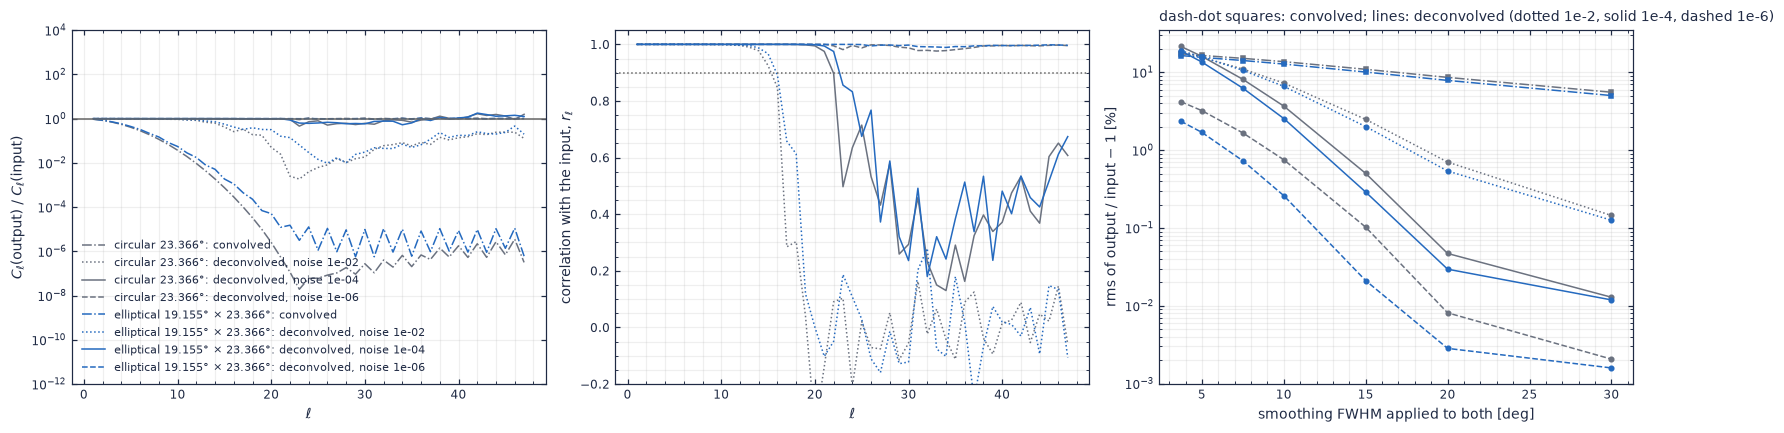

highest ℓ with r_ℓ ≥ 0.9 (the scale ~180°/ℓ):
  circular 23.366°               noise 1e-02: ℓ = 15  (~12°)
  circular 23.366°               noise 1e-04: ℓ = 21  (~9°)
  circular 23.366°               noise 1e-06: ℓ = 47  (~4°)
  elliptical 19.155° × 23.366°   noise 1e-02: ℓ = 15  (~12°)
  elliptical 19.155° × 23.366°   noise 1e-04: ℓ = 22  (~8°)
  elliptical 19.155° × 23.366°   noise 1e-06: ℓ = 47  (~4°)


In [20]:
D_CL_IN = hp.anafast(D_HASLAM - D_HASLAM.mean(), lmax=3 * D_NS - 1)
ell = np.arange(D_CL_IN.size)
D_LGOOD = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
fwhms = np.array([3.7, 5, 7.5, 10, 15, 20, 30])
ls_noise = {1e-2: ":", 1e-4: "-", 1e-6: "--"}
for name in D_A:
    c = D_CONV[name]
    axes[0].semilogy(ell[1:], (hp.anafast(c - c.mean(), lmax=ell[-1]) / D_CL_IN)[1:], "-.", color=D_COL[name],
                     label=f"{name}: convolved")
    for rel in D_NOISE:
        x = D_DECONV[name, rel]
        clx = hp.anafast(x - x.mean(), lmax=ell[-1])
        cross = hp.anafast(x - x.mean(), D_HASLAM - D_HASLAM.mean(), lmax=ell[-1])
        r = cross / np.sqrt(clx * D_CL_IN)
        bad = np.flatnonzero(r[1:] < 0.9)
        D_LGOOD[name, rel] = int(bad[0]) if bad.size else int(ell[-1])
        axes[0].semilogy(ell[1:], (clx / D_CL_IN)[1:], ls_noise[rel], color=D_COL[name],
                         label=f"{name}: deconvolved, noise {rel:.0e}")
        axes[1].plot(ell[1:], r[1:], ls_noise[rel], color=D_COL[name])
        err = [np.std(pct(hp.smoothing(x, fwhm=np.radians(f), iter=3), hp.smoothing(D_HASLAM, fwhm=np.radians(f), iter=3)))
               for f in fwhms]
        axes[2].semilogy(fwhms, err, ls_noise[rel], marker="o", ms=3, color=D_COL[name])
    err_c = [np.std(pct(hp.smoothing(c, fwhm=np.radians(f), iter=3), hp.smoothing(D_HASLAM, fwhm=np.radians(f), iter=3)))
             for f in fwhms]
    axes[2].semilogy(fwhms, err_c, "-.", marker="s", ms=3, color=D_COL[name])
axes[0].axhline(1, color="0.4"); axes[0].set_ylim(1e-12, 1e4)
axes[0].set_xlabel("ℓ"); axes[0].set_ylabel("$C_\\ell$(output) / $C_\\ell$(input)")
axes[0].legend(ncol=1, loc="lower left")
axes[1].axhline(0.9, color="0.4", ls=":"); axes[1].set_ylim(-0.2, 1.05)
axes[1].set_xlabel("ℓ"); axes[1].set_ylabel("correlation with the input, $r_\\ell$")
axes[2].set_xlabel("smoothing FWHM applied to both [deg]"); axes[2].set_ylabel("rms of output / input − 1 [%]")
axes[2].set_title("dash-dot squares: convolved; lines: deconvolved (dotted 1e-2, solid 1e-4, dashed 1e-6)",
                  loc="left")
for ax in axes:
    ax.grid(alpha=0.2, which="both")
plt.tight_layout(); plt.show()
print("highest ℓ with r_ℓ ≥ 0.9 (the scale ~180°/ℓ):")
for (name, rel), lg in D_LGOOD.items():
    print(f"  {name:<30} noise {rel:.0e}: ℓ = {lg:2d}  (~{180 / max(lg, 1):.0f}°)")

---
### Every map

The same round trip for every map the SED fit uses, at noise 10⁻⁴, with both beams. The
operator needs a full sky, but most surveys are partial. So each unobserved pixel is
filled with a straight-line fit of that survey against Haslam over the pixels it did
observe (a T–T fit), which keeps the fill continuous at the mask edge. **Every number is
computed over the observed pixels only.** ARCADE 2 covers 7% of the sky, so its map is
93% fill and its numbers describe the ring alone.

Bars: rms of map / input − 1 over observed pixels: convolved (light), deconvolved (dark),
and deconvolved after 10° smoothing of both (hatched), per beam.

map                                obs px    conv   deconv   @10°    conv   deconv   @10°  (ell − circ)/input: conv  deconv   @10°
                                                 circular 23.366°  elliptical 19.155° × 2
LWA1 35 MHz                          2464   10.6%    31.7%   2.9%   10.0%    30.4%   2.0%                      1.2%   43.8%   3.5%
LWA1 38 MHz                          2464   11.3%    33.1%   2.8%   10.6%    33.9%   2.2%                      1.3%   46.8%   3.5%
LWA1 40 MHz                          2464   11.7%    32.8%   2.9%   10.9%    32.6%   2.2%                      1.4%   45.0%   3.6%
LWA1 45 MHz                          2464   12.7%    35.9%   3.1%   11.9%    35.8%   2.6%                      1.5%   50.2%   3.9%
Maipu + MU 45 MHz                    2920   11.1%    32.9%   3.0%   10.5%    33.6%   2.2%                      1.2%   46.8%   3.8%
LWA1 50 MHz                          2464   13.1%    34.4%   2.9%   12.2%    34.4%   2.3%                      1.5%   48.8% 

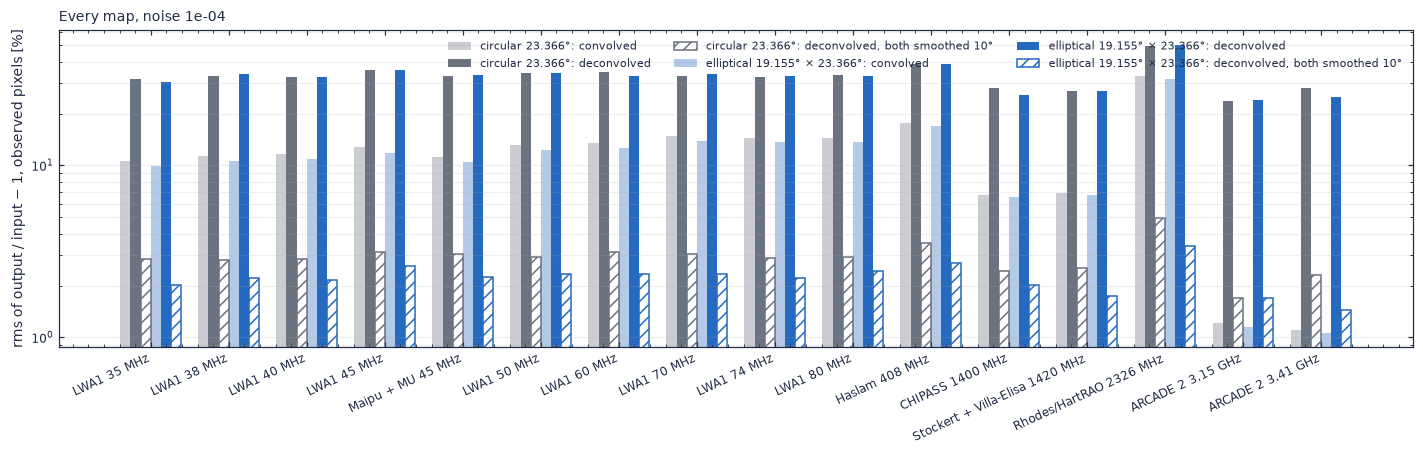

In [21]:
D_ALL = []
for m in H_MAPS:
    rotated, obs = rotated_equatorial(m)
    vals, kept = regrid_to_nside(np.where(obs, rotated, hp.UNSEEN), obs, D_NS)
    a, b = np.polyfit(D_HASLAM[kept], vals[kept], 1)
    s = np.where(kept, vals, a * D_HASLAM + b)
    row = dict(name=m["name"], n_obs=int(kept.sum()))
    for name, A in D_A.items():
        c = A @ s
        sigma = REL * np.abs(c)
        x, _ = wiener_filter_map(c + rng.normal(0.0, 1.0, c.size) * sigma, A, noise_variance=sigma ** 2,
                                 prior_inv_cov=1.0 / np.mean(np.abs(s)) ** 2, guess=np.full(D_NPIX, c.mean()))
        sm = lambda v: hp.smoothing(v, fwhm=np.radians(10.0), iter=3)
        row[name] = dict(conv=np.std(pct(c, s)[kept]), deconv=np.std(pct(x, s)[kept]),
                         deconv10=np.std(pct(sm(x), sm(s))[kept]), conv_vs=None)
        row[name, "conv"], row[name, "deconv"] = c, x
    # elliptical − circular, as a percentage of the input (a deconvolved map can cross zero)
    row["beam_conv"] = np.std((100 * (row[names[1], "conv"] - row[names[0], "conv"]) / s)[kept])
    row["beam_deconv"] = np.std((100 * (row[names[1], "deconv"] - row[names[0], "deconv"]) / s)[kept])
    row["beam_deconv10"] = np.std((100 * (sm(row[names[1], "deconv"]) - sm(row[names[0], "deconv"])) / sm(s))[kept])
    D_ALL.append(row)

print(f"{'map':<34}{'obs px':>7}" + "".join(f"{'conv':>8}{'deconv':>9}{'@10°':>7}" for _ in names)
      + f"{'(ell − circ)/input: conv':>26}{'deconv':>8}{'@10°':>7}")
print(f"{'':<41}" + "".join(f"{n[:22]:>24}" for n in names))
for r in D_ALL:
    print(f"{r['name']:<34}{r['n_obs']:7d}" + "".join(f"{r[n]['conv']:7.1f}%{r[n]['deconv']:8.1f}%{r[n]['deconv10']:6.1f}%" for n in names)
          + f"{r['beam_conv']:25.1f}%{r['beam_deconv']:7.1f}%{r['beam_deconv10']:6.1f}%")

fig, ax = plt.subplots(figsize=(13, 4.2))
x0 = np.arange(len(D_ALL))
w = 0.13
for j, name in enumerate(names):
    off = (j - 0.5) * 3 * w
    ax.bar(x0 + off - w, [r[name]["conv"] for r in D_ALL], width=w, color=D_COL[name], alpha=0.35,
           label=f"{name}: convolved")
    ax.bar(x0 + off, [r[name]["deconv"] for r in D_ALL], width=w, color=D_COL[name],
           label=f"{name}: deconvolved")
    ax.bar(x0 + off + w, [r[name]["deconv10"] for r in D_ALL], width=w, color="white", edgecolor=D_COL[name],
           hatch="///", label=f"{name}: deconvolved, both smoothed 10°")
ax.set_xticks(x0); ax.set_xticklabels([r["name"] for r in D_ALL], rotation=25, ha="right")
ax.set_ylabel("rms of output / input − 1, observed pixels [%]"); ax.set_yscale("log")
ax.legend(ncol=3); ax.grid(axis="y", alpha=0.2, which="both")
ax.set_title(f"Every map, noise {REL:.0e}", loc="left")
plt.tight_layout(); plt.show()

---
### Along the TRIS ring (LST), with the pipeline's own noise

The same round trip, now asking **where along the ring** the maps change. TRIS is a zenith
drift scan, so the sky it sees at a given LST is the sky at RA = LST and Dec = +42.4°.
Each panel follows the nside 16 pixels on the TRIS ring's declination (Dec +41.8°) and
plots map / input − 1 against LST:

* **dashed:** the convolved map (circular grey, elliptical blue);
* **solid:** the deconvolved map.

**Noise: the error bars the pipeline actually uses** (`sed_prototype.sigma_for`):

* ARCADE 2: its calibration uncertainty, 7.5 mK (3.15 GHz) and 6.0 mK (3.41 GHz);
* LWA1, Maipu, CHIPASS, Stockert, Rhodes: each survey's own published temperature-scale,
  zero-level and noise errors in quadrature (`sed_prototype.PUBLISHED_ERRORS`). **The saved
  outputs below were made with an assumed 10% instead** (`ASSUMED_FRACTION`);
* Haslam is the target and never gets an error bar in the fit; here it is given its
  published 10% scale and 3 K zero level.

The noise is drawn per pixel with σ computed from the convolved value. The same σ is given
to limTOD's `wiener_filter_map`, with the same weak prior as above. Grey bands: where a
survey has no data on the ring. Partial maps are filled there as before and the lines are
not drawn.

Galactic plane crossings on the ring at LST ≈ 76°, 312°
no data on the ring (not plotted): CHIPASS 1400 MHz, Rhodes/HartRAO 2326 MHz


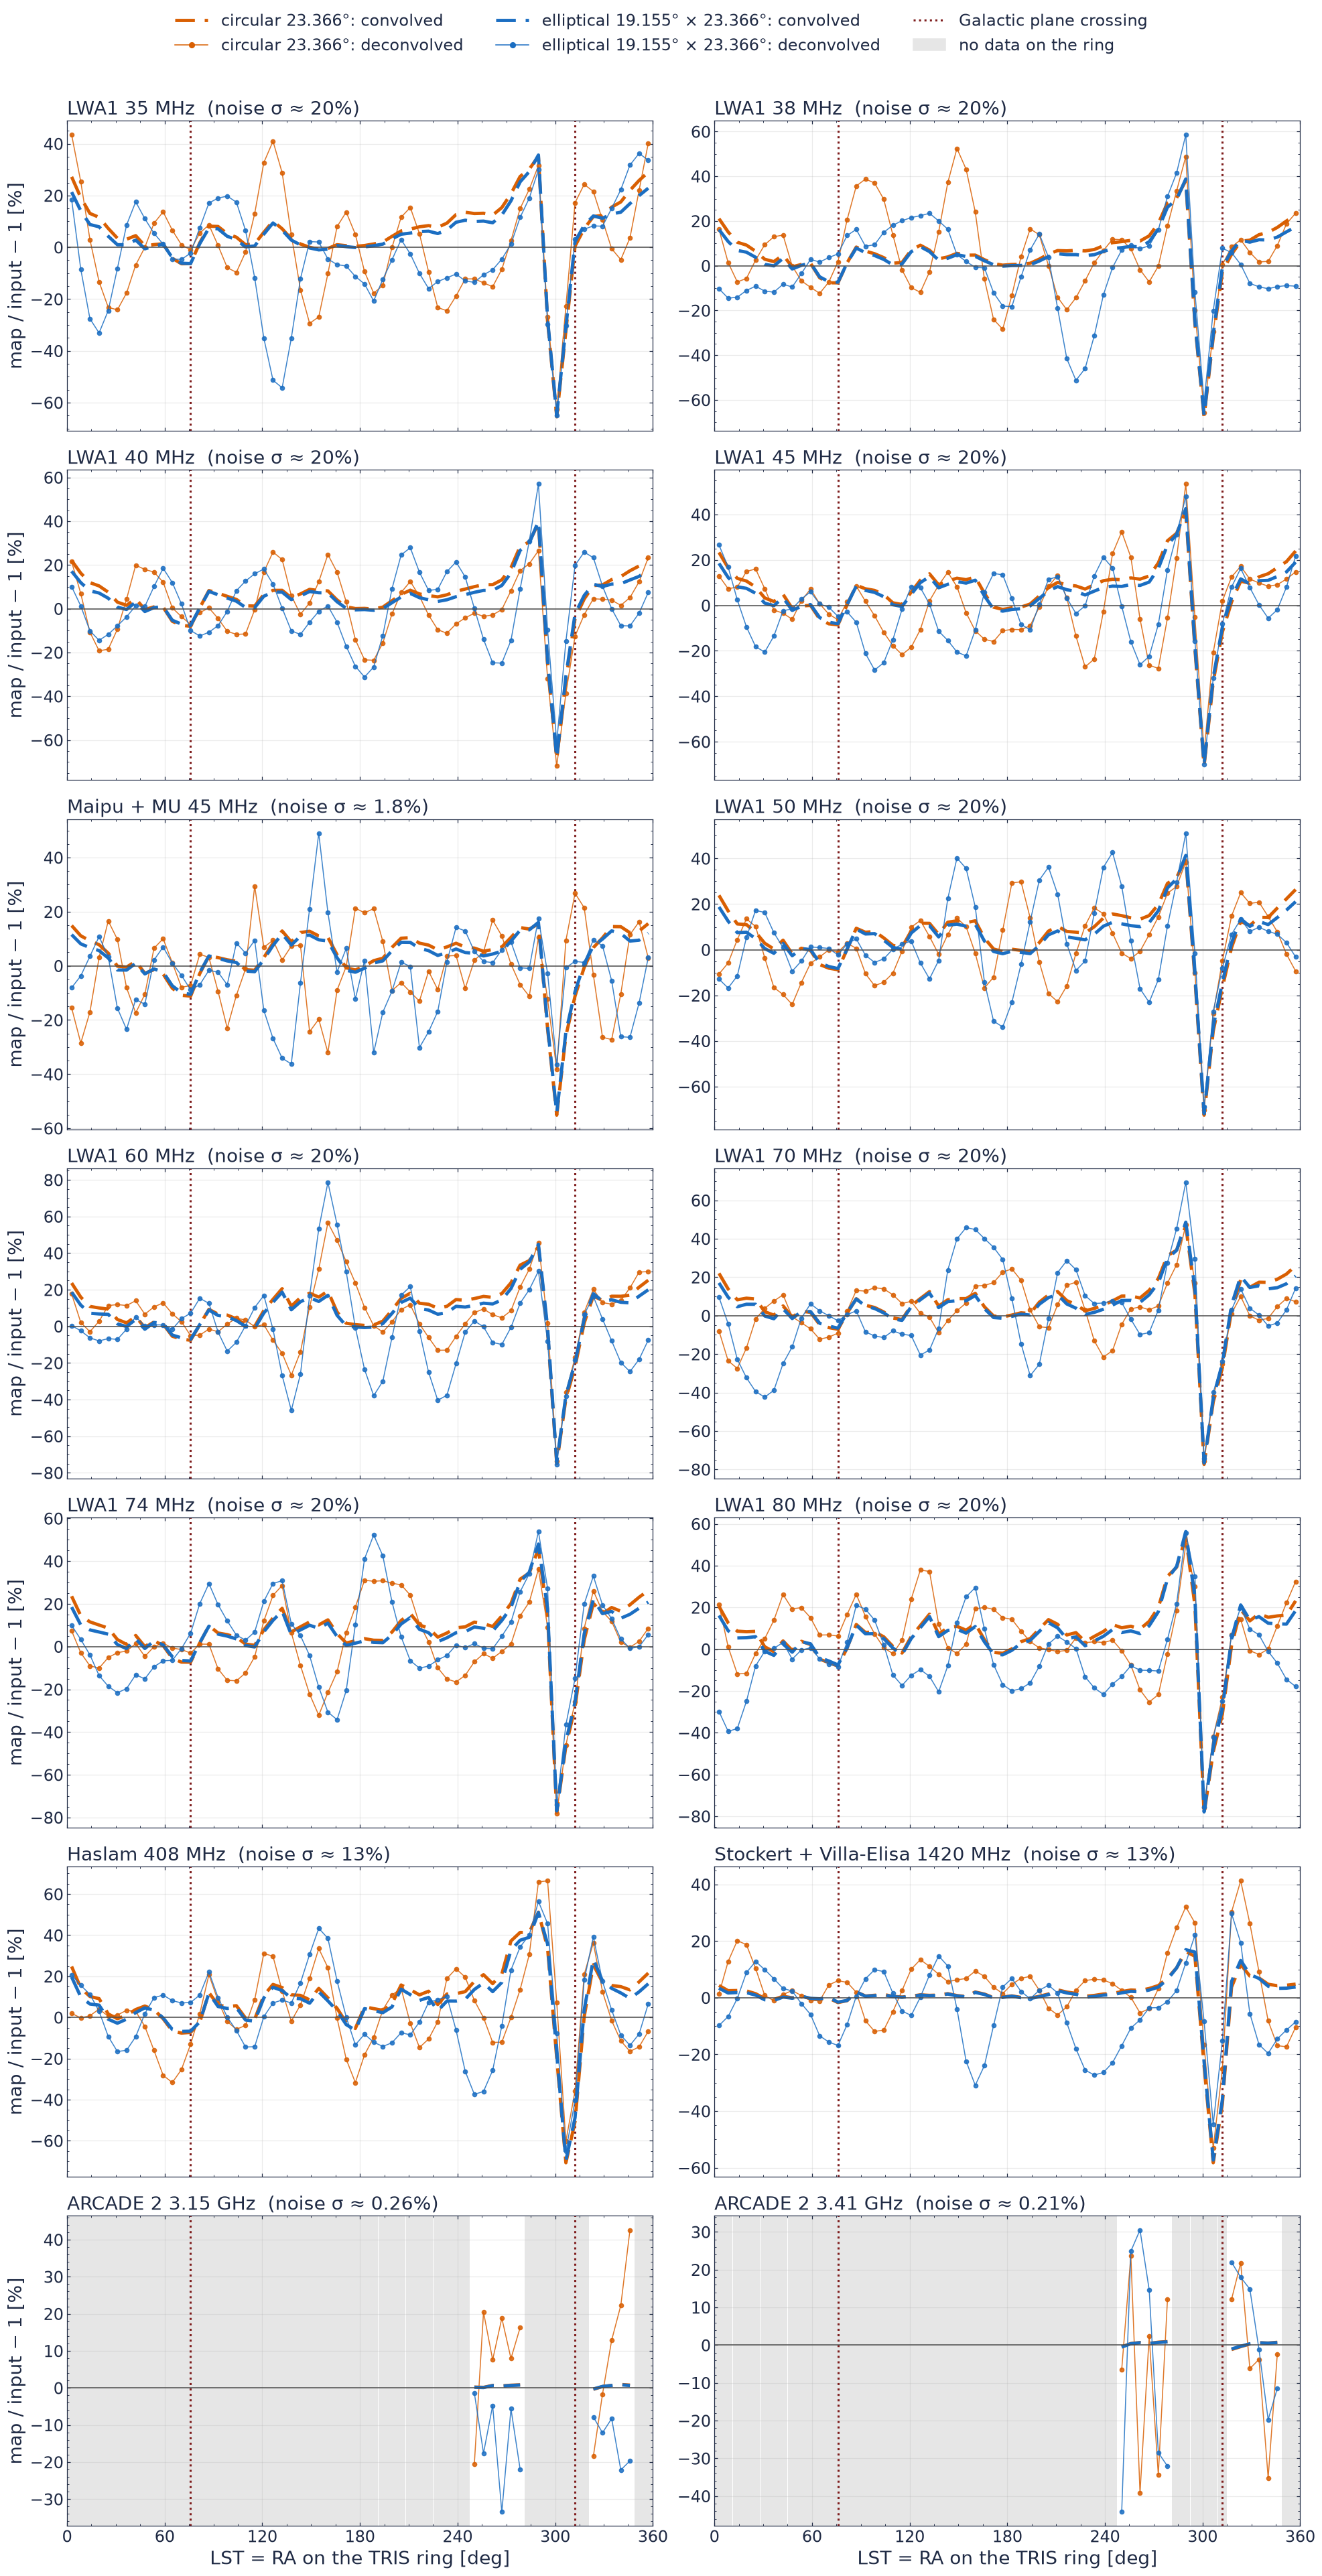

ring at Dec +41.8°, 64 pixels. rms of map / input − 1 along the ring (observed pixels):
map                                  noise     conv   deconv     conv   deconv   (circular | elliptical)
LWA1 35 MHz                            20%    14.4%    19.6%    13.5%    20.3%
LWA1 38 MHz                            20%    13.9%    20.2%    13.2%    20.0%
LWA1 40 MHz                            20%    14.1%    16.7%    13.4%    17.9%
LWA1 45 MHz                            20%    14.6%    16.9%    13.9%    17.5%
Maipu + MU 45 MHz                     1.8%    11.2%    14.7%    10.4%    15.3%
LWA1 50 MHz                            20%    15.1%    17.1%    14.2%    20.0%
LWA1 60 MHz                            20%    16.1%    19.0%    15.3%    23.8%
LWA1 70 MHz                            20%    16.2%    17.3%    15.6%    24.9%
LWA1 74 MHz                            20%    16.5%    19.2%    15.9%    21.8%
LWA1 80 MHz                            20%    17.2%    18.7%    16.8%    19.5%
Haslam 408 MHz   

In [22]:
from moonrunes.sed_prototype import sigma_for, ASSUMED_FRACTION

ring_dec = D_DEC[np.argmin(np.abs(D_DEC - BORESIGHT_DEC))]
RING = np.flatnonzero(np.isclose(D_DEC, ring_dec))
RING = RING[np.argsort(D_RA[RING])]
LST = D_RA[RING]
rng_lst = np.random.default_rng(2026)
D_LST = []
for m in H_MAPS:
    rotated, obs = rotated_equatorial(m)
    vals, kept = regrid_to_nside(np.where(obs, rotated, hp.UNSEEN), obs, D_NS)
    a, b = np.polyfit(D_HASLAM[kept], vals[kept], 1)
    s = np.where(kept, vals, a * D_HASLAM + b)
    out = dict(name=m["name"], kept=kept[RING], s=s[RING])
    for name, A in D_A.items():
        c = A @ s
        sigma = np.maximum(sigma_for(m, sky_maps.rj_excess(c, m)), 1e-6)
        x, _ = wiener_filter_map(c + rng_lst.normal(0.0, 1.0, c.size) * sigma, A, noise_variance=sigma ** 2,
                                 prior_inv_cov=1.0 / np.mean(np.abs(s)) ** 2, guess=np.full(D_NPIX, c.mean()))
        out[name] = dict(conv=pct(c, s)[RING], deconv=pct(x, s)[RING], sigma=np.median(sigma[RING] / np.abs(c[RING])))
    D_LST.append(out)

# Where the ring crosses the Galactic plane (|b| smallest), to read the plots against.
theta_g, _ = hp.Rotator(coord=["C", "G"])(np.radians(90 - ring_dec) * np.ones(RING.size), np.radians(LST))
b_ring = 90 - np.degrees(theta_g)            # Galactic latitude of each ring pixel
PLANE = [LST[k] for k in range(LST.size) if abs(b_ring[k]) < 5 and abs(b_ring[k]) <= abs(b_ring[k - 1])
         and abs(b_ring[k]) <= abs(b_ring[(k + 1) % LST.size])]
no_ring = [r["name"] for r in D_LST if not r["kept"].any()]
D_LST_SHOWN = [r for r in D_LST if r["kept"].any()]
print(f"Galactic plane crossings on the ring at LST ≈ {', '.join(f'{v:.0f}°' for v in PLANE)}")
print(f"no data on the ring (not plotted): {', '.join(no_ring) if no_ring else 'none'}")

n = len(D_LST_SHOWN)
# Big fonts (twice the notebook default) and four clearly different lines:
# colour = beam (orange circular, blue elliptical); style = convolved (thick dashed)
# vs deconvolved (solid with markers).
LST_COL = {list(D_A)[0]: "#d95f02", list(D_A)[1]: "#1b6ec2"}
FS = 18
ncol = 2
nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(18, 5.0 * nrow), sharex=True, squeeze=False)
for ax, r in zip(axes.ravel(), D_LST_SHOWN):
    for v in PLANE:
        ax.axvline(v, color="#7f1d1d", ls=":", lw=2)
    for lst_, k in zip(LST, r["kept"]):
        if not k:
            ax.axvspan(lst_ - 2.8, lst_ + 2.8, color="0.9", lw=0)
    for name in D_A:
        conv = np.where(r["kept"], r[name]["conv"], np.nan)
        dec = np.where(r["kept"], r[name]["deconv"], np.nan)
        ax.plot(LST, dec, "-", color=LST_COL[name], marker="o", ms=4, alpha=0.85)
        ax.plot(LST, conv, "--", color=LST_COL[name], lw=3.2, dashes=(6, 3))
    ax.axhline(0, color="0.3")
    ax.set_title(f"{r['name']}  (noise σ ≈ {100 * r[list(D_A)[0]]['sigma']:.2g}%)", loc="left", fontsize=FS)
    ax.tick_params(labelsize=FS - 2)
    ax.grid(alpha=0.25)
for ax in axes.ravel()[n:]:
    ax.axis("off")
for ax in axes.ravel()[max(0, n - ncol):n]:
    ax.set_xlabel("LST = RA on the TRIS ring [deg]", fontsize=FS)
    ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 60))
    ax.tick_params(labelbottom=True)
for ax in axes[:, 0]:
    ax.set_ylabel("map / input − 1 [%]", fontsize=FS)
handles = []
for nm in D_A:
    handles.append(plt.Line2D([], [], color=LST_COL[nm], ls="--", dashes=(6, 3), lw=3.2, label=f"{nm}: convolved"))
    handles.append(plt.Line2D([], [], color=LST_COL[nm], ls="-", marker="o", ms=5, label=f"{nm}: deconvolved"))
handles.append(plt.Line2D([], [], color="#7f1d1d", ls=":", lw=2, label="Galactic plane crossing"))
handles.append(plt.Rectangle((0, 0), 1, 1, color="0.9", label="no data on the ring"))
fig.legend(handles=handles, loc="upper center", ncol=3, fontsize=FS - 2,
           bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 1 - 1.3 / (5.0 * nrow + 1.3)))
plt.show()

print(f"ring at Dec {ring_dec:+.1f}°, {RING.size} pixels. rms of map / input − 1 along the ring (observed pixels):")
print(f"{'map':<34}{'noise':>8}" + "".join(f"{'conv':>9}{'deconv':>9}" for _ in D_A) + "   (circular | elliptical)")
for r in D_LST_SHOWN:
    k = r["kept"]
    print(f"{r['name']:<34}{100 * r[list(D_A)[0]]['sigma']:7.2g}%" +
          "".join(f"{np.std(r[nm]['conv'][k]):8.1f}%{np.std(r[nm]['deconv'][k]):8.1f}%" for nm in D_A))

**Reading the LST plot (run 2026-10-14).** The Galactic plane crossings are at LST ≈ 76°
(Perseus–Auriga) and 312° (Cygnus). CHIPASS and Rhodes/HartRAO have no data on the TRIS
ring's declination, so they are not plotted.

* **Convolving changes the maps almost only near the bright plane at Cygnus.**
  * Between LST ≈ 270° and 330°, every survey's convolved map drops by 45–80% on the
    brightest pixels (LST ≈ 305°). It rises by 15–55% on the pixels just before, where the
    beam spreads the emission.
  * Elsewhere on the ring the convolved maps are within about ±20%, mostly ±10%.
  * The fainter Perseus crossing (76°) barely shows.
  * ARCADE 2, already at 11.6°, changes by under 1% where it has data.
* **Elliptical and circular convolved maps are nearly identical along the ring.** The ring
  runs east–west, along the H plane, where both beams are 23.366°. The beams differ only
  north–south, so the shape matters off the ring's declination, not along it.
* **Deconvolving does not give the ring back pixel by pixel.** With the pipeline's own
  noise (10% for LWA, Maipu and Haslam, 2.8% for Stockert, 0.2–0.3% for ARCADE 2), the
  deconvolved maps scatter by 10–25% rms around the input along the ring:
  * the scatter is not concentrated at the plane;
  * it is the pixel-scale noise of the previous sections, at every LST.

  10% noise is large, so the noise-dominated scales start at a lower ℓ than at 10⁻⁴.
  Stockert, with the smallest relative noise among the full-ring surveys, comes back
  closest (12% rms circular, 11% elliptical).
* **The elliptical beam's deconvolved maps are a little closer to the input** for most
  surveys (Haslam 22.7% against 24.5%; Maipu 18.0% against 19.7%). LWA1 80 MHz is the
  exception (24.0% against 18.8%).

---
#### Reading this section (run 2026-10-14)

**1. limTOD's convolution is what the pipeline uses.** **A s** equals `generate_TOD_sky`
to 4×10⁻¹⁶.

**2. Convolving changes the maps, as it should.** Haslam through the circular beam differs
from the input by 17.7% rms (14.3% in the TRIS stripe), and through the elliptical beam by
16.8% (13.3%). The other maps lose 1–33%, depending on how much small-scale structure they
have; ARCADE 2, already at 11.6°, loses about 1%.

**3. Deconvolving does *not* give the maps back pixel by pixel.**

| beam | noise 10⁻² | 10⁻⁴ | 10⁻⁶ |
|---|---|---|---|
| circular: deconvolved / input − 1, rms | 23.2% | 38.8% | 14.4% |
| elliptical | 24.8% | 36.5% | 13.8% |

That is *worse* than the convolved map (~17%). The error is pixel-scale, amplified noise:
modes the beam suppressed below the noise come back multiplied by 1/(singular value).
Noise 10⁻⁴ looks worse than 10⁻² at the pixel level only because the weak prior holds
back more of those modes at 10⁻²; by scale, 10⁻⁴ is better.

**4. By scale, the round trip is very good on large scales and fails on small ones.**

* **Correlation with the input stays ≥ 0.9 up to:** ℓ = 15 (~12°) at noise 10⁻²,
  ℓ = 21–22 (~8–9°) at 10⁻⁴, and ℓ = 47 (every scale on the grid) at 10⁻⁶.
* **Compared at 10° resolution,** the deconvolved Haslam (noise 10⁻⁴) matches the input
  to 3.8% rms (circular) and **2.8%** (elliptical).
  * Every other map: 2.1–5.3% (circular) and **1.7–3.4%** (elliptical).
  * At 20° resolution, 0.05% and 0.03%.
* **The map "changes" only at scales the beam suppressed below the noise.** Those scales
  are lost and cannot be recovered by any deconvolution.

**5. The two beams.**

* **The elliptical beam passes more sky.** It has 377 modes above 10⁻² of the largest
  singular value (circular: 320), and 1959 above 10⁻⁴ (circular: 1855). It recovers about
  one ℓ further at noise 10⁻⁴, and its deconvolved maps are closer to the input at 10° for
  **every** map (2.8% against 3.8% on Haslam).
* **Convolved:** elliptical and circular differ by **1.9% rms** of the input (max 11.5%,
  1.8% in the TRIS stripe). This is the beam-shape effect on what the instrument sees, the
  same order as the stage 2 kernel change measured earlier in this notebook.
* **Deconvolved:** the difference is noise-dominated at pixel level (50% rms). At 10° it
  is 4.2% rms: the two maps carry the same large-scale sky, with different noise.

**What this means for the pipeline.**

* **Stage 1 is this deconvolution, under much worse conditions.** It solves for TRIS maps
  from one ring at one declination, not from 3072 pointings covering the sky. Its maps can
  only be trusted on scales the ring constrains. They cannot be compared pixel by pixel
  with surveys matched to the TRIS *instrument* beam. The measured scale: even full-sky sampling at the TRIS rings' noise level (~10⁻⁴) preserves
  structure only to ~8–9°.
* **Matching to the beam is a convolution, and it is stable.** Stage 2 and the TOD route
  only ever convolve, and that is exactly reproducible (point 1).
* **The elliptical beam is measurably better** at every noise level, both at passing
  structure and at recovering it.

---
## Two-step against one-step beam matching

> **Note:** `beam_matching.kernel` (stage 2 and the map route) is `circular_gaussian`; the pipeline's ring TODs and step 1 use `tris_cuts`. "Default" below means `tris_cuts`.

**The test.** A real survey is never a perfect Gaussian: it has an elliptical main lobe,
sidelobes and a broad error beam. Stage 2 knows only one number about it, its quoted FWHM,
and builds its kernel from that. So, with **the pipeline's own convolution**
(`stage2_beam_matching.match_to_tris_beam`, the function stage 2 and the map route call),
compare two scenarios:

1. **Two-step:** sky → convolved with a complicated, non-Gaussian survey beam → matched to
   the TRIS target by the pipeline, which is told the survey beam's FWHM.
2. **One-step:** the same sky → matched to the TRIS target by the pipeline directly
   (native beam: Haslam's 0.933°).

Ideally both give the same map. Any difference is what the pipeline gets wrong about a
survey whose beam is not the Gaussian it assumes.

**The sky:** Haslam in equatorial on nside 64 (the pipeline's working grid), used as the
"true" sky in both scenarios.

**Two native beams for step 1:**

| | shape | FWHM given to the pipeline |
|---|---|---|
| **control** | circular Gaussian, 5° | 5° |
| **complicated** | elliptical Gaussian main lobe 5° × 3° at position angle 30°; a first sidelobe ring at 7° from the centre, 1.5° wide, −15 dB; a broad error beam, 20° FWHM at −25 dB | 5° (the main lobe's major axis, measured) |

The control isolates what the kernel rule itself does. For a Gaussian native beam the
quadrature rule is exact for the Gaussian kernels, so any difference there comes from the
kernel shape. The complicated beam adds what a real survey beam would.

**Three pipeline kernels**, each run through both scenarios:

* **circular Gaussian** (`circular_gaussian`, stage 2's kernel);
* **elliptical Gaussian** (`elliptical_gaussian`);
* **measured TRIS beam** (`tris_cuts`, the default). For a 5° native beam it uses the cut
  beam compressed to the quadrature widths (`scaled_cuts`).

Step 1's convolution is done by direct summation on the nside 64 grid. It is not part of
the pipeline; it only plays the survey's own beam.

complicated beam: major-axis FWHM 5.010°, minor-axis FWHM 3.007°
complicated beam: 17.6% of its weight is outside the main lobe (sidelobe ring + error beam)


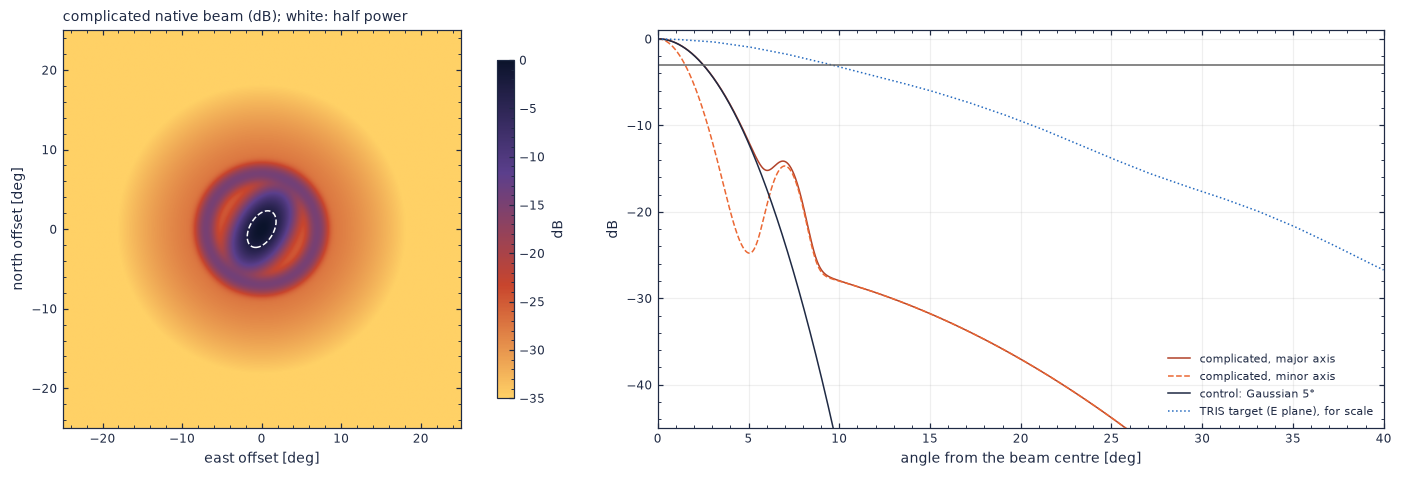

In [23]:
from moonrunes.stage2_beam_matching import match_to_tris_beam
K_ = 2.0 * np.sqrt(2.0 * np.log(2.0))
NS64 = 64
SKY64 = hp.ud_grade(HASLAM_C, NS64)
ONES64 = np.ones(SKY64.size, bool)
PTS64 = np.array(hp.pix2vec(NS64, np.arange(SKY64.size))).T
TS_BAND = load_stage1(config)["band_mask"].astype(bool)

CB = dict(major=5.0, minor=3.0, pa=30.0, ring_r=7.0, ring_w=1.5, ring_db=-15.0,
          shoulder_fwhm=20.0, shoulder_db=-25.0)

def complicated_beam(theta, psi):
    # Elliptical main lobe (major axis at position angle CB["pa"]) + a sidelobe ring + a broad error beam.
    phi = np.radians(np.asarray(psi) - CB["pa"])
    sa, sb = CB["major"] / K_, CB["minor"] / K_
    main = np.exp(-0.5 * ((theta * np.cos(phi) / sa) ** 2 + (theta * np.sin(phi) / sb) ** 2))
    ring = 10 ** (CB["ring_db"] / 10) * np.exp(-0.5 * ((theta - CB["ring_r"]) / (CB["ring_w"] / K_)) ** 2)
    shoulder = 10 ** (CB["shoulder_db"] / 10) * np.exp(-0.5 * (theta / (CB["shoulder_fwhm"] / K_)) ** 2)
    return np.where(theta <= 90.0, main + ring + shoulder, 0.0)

def gaussian_beam(theta, psi, fwhm=5.0):
    return np.where(theta <= 90.0, np.exp(-0.5 * (theta / (fwhm / K_)) ** 2), 0.0)

def convolve_native(sky, beam_fn, chunk=256):
    # Direct sum on the nside 64 grid: out(p) = sum_q B(p, q) T(q) / sum_q B(p, q).
    out = np.empty(sky.size)
    for s in range(0, len(PTS64), chunk):
        th, psi = eb.local_offsets(PTS64[s:s + chunk], PTS64)
        w = beam_fn(th, psi)
        out[s:s + chunk] = (sky @ w) / w.sum(axis=0)
    return out

theta_line = np.arange(0.0, 40.0, 0.01)
CB_FWHM = fwhm_from_profile(theta_line, complicated_beam(theta_line, np.full(theta_line.size, CB["pa"])))
NATIVE = {"Gaussian 5° (control)": (gaussian_beam, 5.0),
          "complicated": (complicated_beam, CB_FWHM)}
print(f"complicated beam: major-axis FWHM {CB_FWHM:.3f}°, minor-axis FWHM "
      f"{fwhm_from_profile(theta_line, complicated_beam(theta_line, np.full(theta_line.size, CB['pa'] + 90))):.3f}°")
# Fraction of the complicated beam's weight outside its main lobe (integrated over the sphere).
th = np.arange(0.0, 90.0, 0.05) + 0.025
P = np.arange(0.0, 360.0, 1.0)
T, PP = np.meshgrid(th, P, indexing="ij")
w_all = (complicated_beam(T, PP).mean(axis=1) * np.sin(np.radians(th)))
phi_ = np.radians(PP - CB["pa"])
w_main = (np.exp(-0.5 * ((T * np.cos(phi_) / (CB["major"] / K_)) ** 2 + (T * np.sin(phi_) / (CB["minor"] / K_)) ** 2)).mean(axis=1)
          * np.sin(np.radians(th)))
print(f"complicated beam: {100 * (1 - w_main.sum() / w_all.sum()):.1f}% of its weight is outside the main lobe "
      f"(sidelobe ring + error beam)")

# The beams, for the record: image of the complicated beam, and profiles against the control and the TRIS target.
fig = plt.figure(figsize=(14, 4.4))
ax = fig.add_subplot(1, 2, 1)
axis = np.arange(-25, 25.01, 0.1)
X, Y = np.meshgrid(axis, axis)
img = complicated_beam(np.hypot(X, Y), np.degrees(np.arctan2(X, Y)))
db = np.clip(10 * np.log10(np.maximum(img, 1e-6)), -35, 0)
im = ax.imshow(db, origin="lower", extent=[axis[0], axis[-1], axis[0], axis[-1]], cmap=SEQB.reversed(), vmin=-35, vmax=0)
ax.contour(X, Y, db, levels=[HALF_DB], colors="white")
ax.set_xlabel("east offset [deg]"); ax.set_ylabel("north offset [deg]"); ax.set_aspect("equal")
ax.set_title("complicated native beam (dB); white: half power", loc="left")
fig.colorbar(im, ax=ax, shrink=0.85, label="dB")
ax = fig.add_subplot(1, 2, 2)
ax.plot(theta_line, 10 * np.log10(complicated_beam(theta_line, np.full(theta_line.size, CB["pa"]))), color="#b2432a",
        label="complicated, major axis")
ax.plot(theta_line, 10 * np.log10(complicated_beam(theta_line, np.full(theta_line.size, CB["pa"] + 90))), color="#eb6834",
        ls="--", label="complicated, minor axis")
ax.plot(theta_line, 10 * np.log10(gaussian_beam(theta_line, 0)), color=COLORS["ink"], label="control: Gaussian 5°")
k_t = eb.kernel_for(SPEC_CUTS, 0.0)
ax.plot(theta_line, 10 * np.log10(np.maximum(eb.kernel_response(k_t, SPEC_CUTS, theta_line, np.full(theta_line.size, PA_E)), 1e-9)),
        color="#256abf", ls=":", label="TRIS target (E plane), for scale")
ax.axhline(HALF_DB, color="0.4")
ax.set_xlim(0, 40); ax.set_ylim(-45, 1); ax.set_xlabel("angle from the beam centre [deg]"); ax.set_ylabel("dB")
ax.legend(); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

step 1 (native beams) done in 259 s
pipeline matching done in 472 s

native beam             pipeline kernel              median     rms  max |Δ|  stripe rms  kernel the pipeline chose
Gaussian 5° (control)   circular Gaussian (old)      +0.00%   0.02%    0.05%       0.01%  circular 22.82°
Gaussian 5° (control)   elliptical Gaussian          +0.01%   0.02%    0.07%       0.02%  elliptical_gaussian 18.49° × 22.82°
Gaussian 5° (control)   TRIS cuts (measured)         -0.05%   0.14%    0.44%       0.11%  tris_cuts 18.49° × 22.82°
complicated             circular Gaussian (old)      +0.16%   0.45%    1.46%       0.37%  circular 22.82°
complicated             elliptical Gaussian          +0.18%   0.52%    1.81%       0.43%  elliptical_gaussian 18.49° × 22.82°
complicated             TRIS cuts (measured)         +0.11%   0.29%    1.13%       0.24%  tris_cuts 18.49° × 22.82°


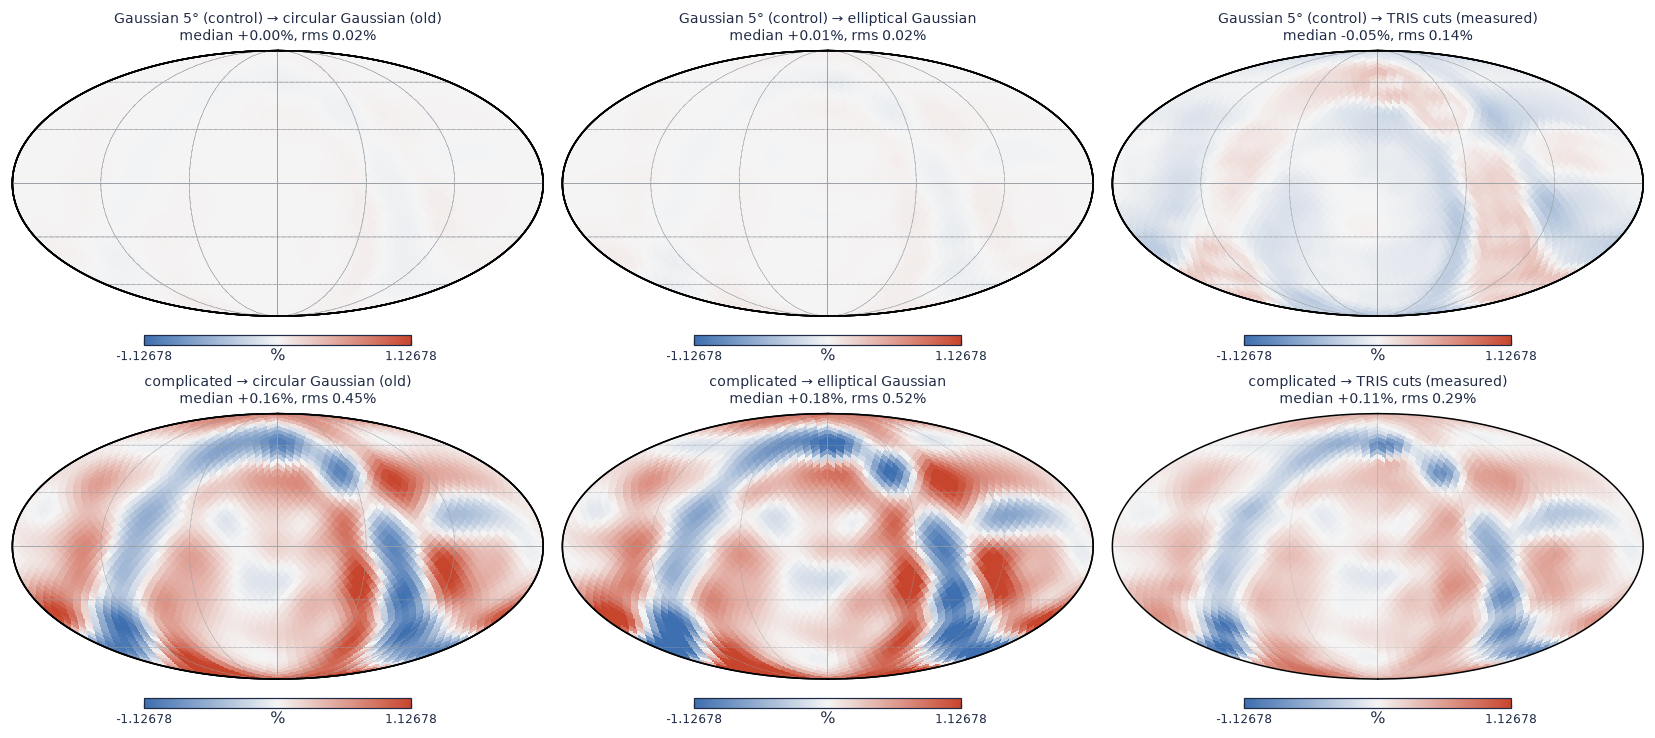

In [24]:
# Run both scenarios through the pipeline's own beam matching, for all three kernels.
t0 = time.time()
PRE = {name: convolve_native(SKY64, fn) for name, (fn, _) in NATIVE.items()}
print(f"step 1 (native beams) done in {time.time() - t0:.0f} s")

def pipeline(sky, native_fwhm, label):
    spec = None if KERNEL_KEY[label] == "circular_gaussian" else SPECS[label]
    v, kept, info = match_to_tris_beam(sky, ONES64, native_fwhm, CONFIGS[label], nside_out=16,
                                       rule="all_children", spec=spec, full_sky=True)
    return np.where(kept, v, np.nan), info

TS_DIRECT = {label: pipeline(SKY64, HASLAM_NATIVE, label) for label in SPECS}
TS_TWO = {(nat, label): pipeline(PRE[nat], fw, label) for nat, (_, fw) in NATIVE.items() for label in SPECS}
print(f"pipeline matching done in {time.time() - t0:.0f} s\n")

TS_DIFF = {key: 100 * (TS_TWO[key][0] / TS_DIRECT[key[1]][0] - 1) for key in TS_TWO}
print(f"{'native beam':<24}{'pipeline kernel':<26}{'median':>9}{'rms':>8}{'max |Δ|':>9}{'stripe rms':>12}  kernel the pipeline chose")
for (nat, label), d in TS_DIFF.items():
    info = TS_TWO[nat, label][1]
    chose = (f"circular {info['extra_fwhm_deg']:.2f}°" if info["kernel"] == "circular_gaussian"
             else f"{info['kernel_shape']} {info['kernel_fwhm_e_deg']:.2f}° × {info['kernel_fwhm_h_deg']:.2f}°")
    print(f"{nat:<24}{label:<26}{np.nanmedian(d):+8.2f}%{np.nanstd(d):7.2f}%{np.nanmax(np.abs(d)):8.2f}%"
          f"{np.nanstd(d[TS_BAND]):11.2f}%  {chose}")

span = float(np.nanpercentile(np.abs(np.concatenate([d for d in TS_DIFF.values()])), 99))
fig = plt.figure(figsize=(15, 6.6))
for r, nat in enumerate(NATIVE):
    for c, label in enumerate(SPECS):
        d = TS_DIFF[nat, label]
        hp.mollview(d, sub=(2, 3, 3 * r + c + 1), fig=fig.number, cmap=DIVB, min=-span, max=span, unit="%",
                    title=f"{nat} → {label}\nmedian {np.nanmedian(d):+.2f}%, rms {np.nanstd(d):.2f}%", notext=True)
        hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.3)
plt.show()

**What the maps show.** Each panel is the nside 16 product made in two steps (native beam,
then the pipeline) divided by the one made in one step, minus 1. The top row is the
Gaussian control and the bottom row the complicated beam; the columns are the pipeline's
three kernels. White means the two scenarios agree.

**Along the TRIS ring, and as a summary.** Left: the same ratio along the TRIS ring
(LST = RA at Dec +41.8°), for the complicated beam, one line per kernel. Right: the rms
and the largest difference over the TRIS stripe, every case.

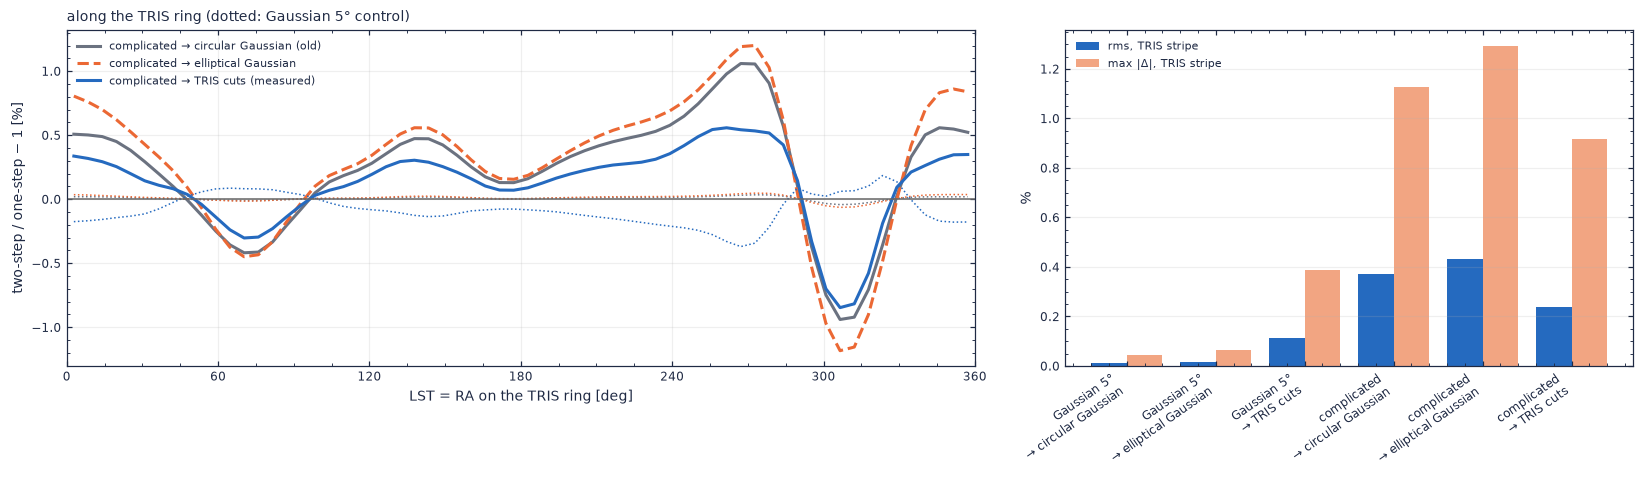

In [25]:
ring_dec16 = None
_, dec16 = hp.pix2ang(16, np.arange(hp.nside2npix(16)), lonlat=True)
ring_dec16 = dec16[np.argmin(np.abs(dec16 - BORESIGHT_DEC))]
ring16 = np.flatnonzero(np.isclose(dec16, ring_dec16))
ra16 = hp.pix2ang(16, ring16, lonlat=True)[0]
order = np.argsort(ra16); ring16, ra16 = ring16[order], ra16[order]

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw=dict(width_ratios=[1.6, 1]))
style = {"circular Gaussian (old)": ("#6b7280", "-"), "elliptical Gaussian": ("#eb6834", "--"),
         "TRIS cuts (measured)": ("#256abf", "-")}
for label in SPECS:
    c, ls = style[label]
    ax.plot(ra16, TS_DIFF["complicated", label][ring16], ls, color=c, lw=2, label=f"complicated → {label}")
    ax.plot(ra16, TS_DIFF["Gaussian 5° (control)", label][ring16], ":", color=c)
ax.axhline(0, color="0.4")
ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 60))
ax.set_xlabel("LST = RA on the TRIS ring [deg]"); ax.set_ylabel("two-step / one-step − 1 [%]")
ax.set_title("along the TRIS ring (dotted: Gaussian 5° control)", loc="left")
ax.legend(); ax.grid(alpha=0.2)

keys = list(TS_DIFF)
xs = np.arange(len(keys))
ax2.bar(xs - 0.2, [np.nanstd(TS_DIFF[k][TS_BAND]) for k in keys], width=0.4, color="#256abf", label="rms, TRIS stripe")
ax2.bar(xs + 0.2, [np.nanmax(np.abs(TS_DIFF[k][TS_BAND])) for k in keys], width=0.4, color="#f2a582", label="max |Δ|, TRIS stripe")
ax2.set_xticks(xs); ax2.set_xticklabels([f"{n.split(' (')[0]}\n→ {l.split(' (')[0]}" for n, l in keys], rotation=35,
                                        ha="right")
ax2.set_ylabel("%"); ax2.legend(); ax2.grid(axis="y", alpha=0.2)
plt.tight_layout(); plt.show()

**Two-step against one-step, maps side by side (complicated survey beam).** Top row:
the circular Gaussian kernel. Bottom row: the elliptical Gaussian kernel. Left: two-step
(sky → complicated beam → pipeline). Middle: one-step (sky → pipeline directly). Right:
the residual between them, two-step − one-step, in kelvin. Both rows share one temperature scale
(log₁₀ T) and one residual scale.


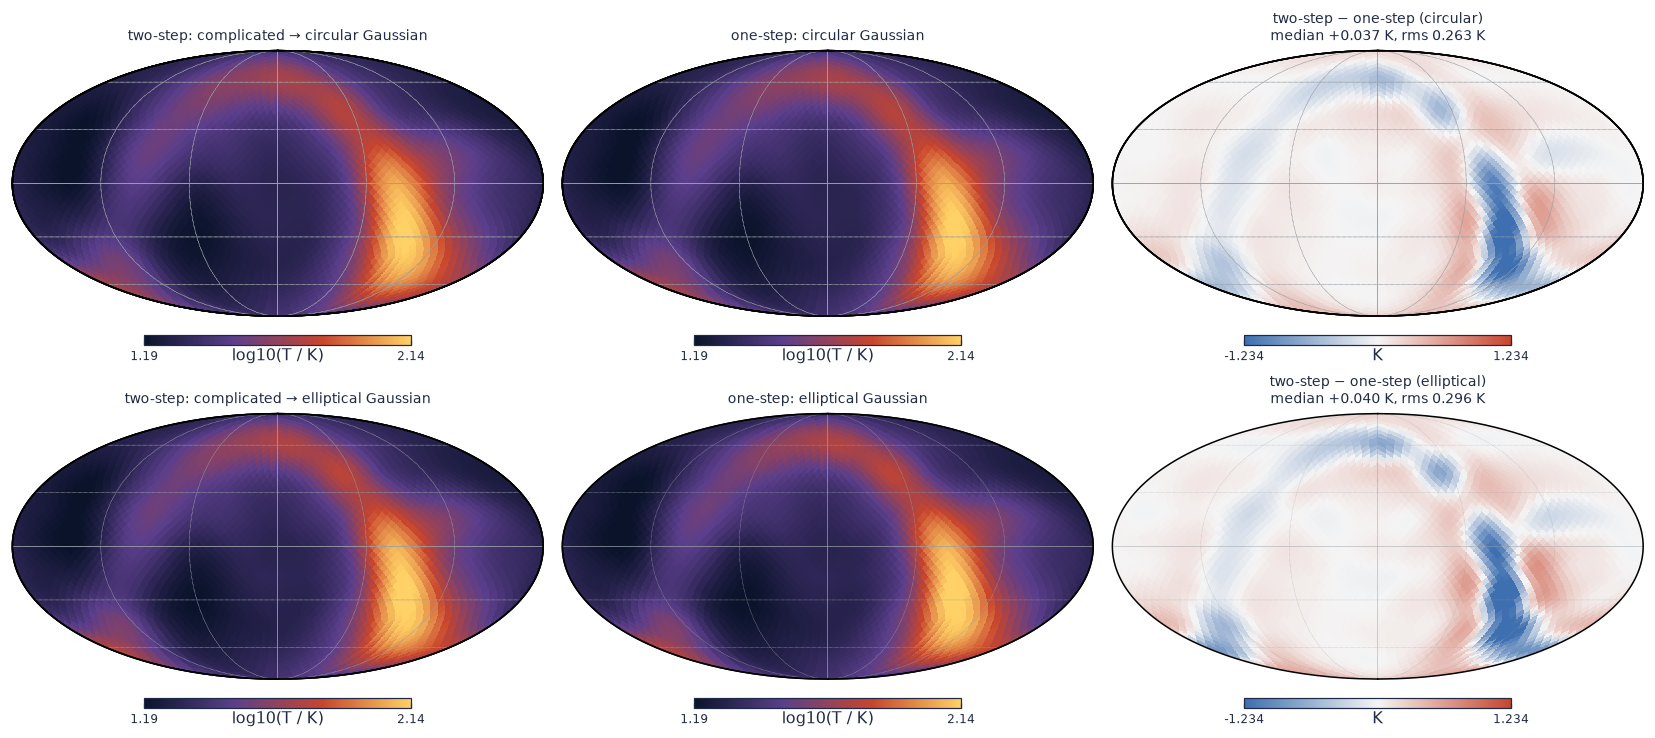

circular    two-step − one-step: median +0.0373 K, rms 0.2633 K, max |Δ| 1.6134 K
elliptical  two-step − one-step: median +0.0401 K, rms 0.2962 K, max |Δ| 1.8728 K


In [26]:
ROWS = ["circular Gaussian (old)", "elliptical Gaussian"]
SHORT = {"circular Gaussian (old)": "circular", "elliptical Gaussian": "elliptical"}
both_maps = [m for label in ROWS for m in (TS_TWO["complicated", label][0], TS_DIRECT[label][0])]
tlo, thi = np.nanpercentile(np.log10(np.concatenate(both_maps)), [0.5, 99.5])
RES_K = {label: TS_TWO["complicated", label][0] - TS_DIRECT[label][0] for label in ROWS}   # two-step − one-step [K]
rspan = float(np.nanpercentile(np.abs(np.concatenate(list(RES_K.values()))), 99))

fig = plt.figure(figsize=(15, 6.6))
for r, label in enumerate(ROWS):
    two, one, d = TS_TWO["complicated", label][0], TS_DIRECT[label][0], RES_K[label]
    k = SHORT[label]
    hp.mollview(np.log10(two), sub=(2, 3, 3 * r + 1), fig=fig.number, min=tlo, max=thi,
                unit="log10(T / K)", format="%.2f", title=f"two-step: complicated → {k} Gaussian", notext=True)
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.3)
    hp.mollview(np.log10(one), sub=(2, 3, 3 * r + 2), fig=fig.number, min=tlo, max=thi,
                unit="log10(T / K)", format="%.2f", title=f"one-step: {k} Gaussian", notext=True)
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.3)
    hp.mollview(d, sub=(2, 3, 3 * r + 3), fig=fig.number, cmap=DIVB, min=-rspan, max=rspan, unit="K", format="%.3f",
                title=f"two-step − one-step ({k})\nmedian {np.nanmedian(d):+.3f} K, rms {np.nanstd(d):.3f} K",
                notext=True)
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.3)
plt.show()
for label in ROWS:
    print(f"{SHORT[label]:<11} two-step − one-step: median {np.nanmedian(RES_K[label]):+.4f} K, rms {np.nanstd(RES_K[label]):.4f} K, "
          f"max |Δ| {np.nanmax(np.abs(RES_K[label])):.4f} K")


#### Reading this section (run 2026-10-14)

**Ideally the two scenarios agree. With a Gaussian survey beam they do; with a realistic,
non-Gaussian one they differ by a fraction of a percent.**

| survey beam | pipeline kernel | two-step / one-step − 1: median | rms | max \|Δ\| | rms in TRIS stripe |
|---|---|---|---|---|---|
| Gaussian 5° (control) | circular Gaussian | +0.00% | 0.02% | 0.05% | 0.01% |
| Gaussian 5° (control) | elliptical Gaussian | +0.01% | 0.02% | 0.07% | 0.02% |
| Gaussian 5° (control) | measured TRIS beam (default) | −0.05% | 0.14% | 0.44% | 0.11% |
| complicated | circular Gaussian | +0.16% | 0.45% | 1.46% | 0.37% |
| complicated | elliptical Gaussian | +0.18% | 0.52% | 1.81% | 0.43% |
| complicated | measured TRIS beam (default) | +0.11% | 0.29% | 1.13% | 0.24% |

* **The pipeline's convolution composes correctly.** With a Gaussian survey beam, the
  Gaussian kernels give the same map either way to 0.02% rms. The quadrature rule is
  exact there, and what remains is pixelisation.
* **The default measured-beam kernel is approximate even for a Gaussian survey beam**
  (0.14% rms, 0.44% max). Compressing the cut beam to the quadrature widths is not an
  exact deconvolution, the same effect plot 4 of the elliptical-beam section measured as
  a 2.4% wider effective FWHM for a 4.65° survey beam. On the map it is a fraction of a
  percent, because most of the sky's structure is on scales much larger than the beam.
* **A complicated survey beam is mis-modelled by every kernel**, by 0.3–0.5% rms and up
  to 1.1–1.8%. The pipeline is told only the main lobe's 5° FWHM. The sidelobe ring and
  error beam (17.6% of this beam's weight) smooth the map further, and nothing removes that.
  * **The pattern:** the two-step map is *lower* along the Galactic plane, where the extra
    smoothing pulls emission out (blue ridges), and *higher* just off it (red).
  * **Along the TRIS ring** the error is largest at the Cygnus crossing: −0.8 to −1.2% at
    LST ≈ 305°, and +0.5 to +1.2% beside it.
  * **The measured-beam kernel comes out best here** (0.29% rms, against 0.45–0.52%). Why
    has not been established, and with one test beam it should not be read as a general
    property of the kernel.

**What this means.** The beam matching is consistent: matching in one step or two gives
the same answer when the survey beam is what the pipeline thinks it is. When a survey's
real beam has significant sidelobes or an error beam, using its FWHM alone costs about
0.3–0.5% rms, and up to ~1–2% at the bright plane. That is small next to the 10%
error bars assumed for most surveys and the 13–18% Haslam offset. It is comparable to the
kernel-shape effects measured above. A survey whose beam is published in full (like
TRIS's) could have it used directly instead of its FWHM.

---
---
## How much does the T-vs-LST curve depend on how the beam is specified?

Full-sky models are re-observed through several versions of the TRIS cut beam with the TOD
route's own observation code, `sed_prototype.Inputs._native_tod` (as pipeline step 2 does), and the ring TODs
are compared. Each variant uses the same measured cuts (FWHM 19.155° in the E plane, 23.366° in the H plane).

**How the baseline interpolates.** The `tris_cuts` kernel (`elliptical_beam.cut_response`, `blend: db`) and limTOD's
`tris_cut_beam_map`, which `_native_tod` observes with, do the same thing. Each measured cut is interpolated linearly
in θ, in dB. At an angle φ from the E plane the two dB values are then averaged with weights cos²φ (E) and sin²φ (H),
so the beam is linear in dB between the planes.

**The variants, and how each is set.** The beam map is never rotated. It is drawn with the boresight at the pole and
the E plane at φ = 0. The roll is set once, in the geometry: `tris.tris_zenith_geometry(ra,
e_plane_east_of_meridian_deg=roll)`, which gives `selfrot = −roll` (azimuth 0, elevation 90).

| Variant | E plane (east of the meridian) | Beam between the planes | How it is set |
|---|---|---|---|
| V0 baseline | +7° | dB blend | `tris_cut_beam_map(cuts, blend="db")`, roll 7 (exactly the TOD route's beam and geometry) |
| V1 | −7° (west) | dB blend | roll −7 |
| V2 | 0° (on the meridian) | dB blend | roll 0 |
| V3 planes swapped | 97° (H at 7°) | dB blend | roll 97: an extreme bound, for scale only |
| V4a | +7° | FWHM(φ)⁻² = cos²φ/FWHM_E² + sin²φ/FWHM_H² | see below, roll 7 |
| V4b | +7° | linear in power: B = B_E(θ)cos²φ + B_H(θ)sin²φ | `tris_cut_beam_map(cuts, blend="power")`, roll 7 |
| V4c | +7° | FWHM linear in φ, from FWHM_E at 0° to FWHM_H at 90° | see below, roll 7 |

**V4a and V4c are FWHM rules, so a full beam has to be built for them.** Both keep the dB blend, but each cut is
stretched in θ so that the half-power width at φ is exactly FWHM(φ):
B = 10^([cos²φ E_dB(θ FWHM_E/F(φ)) + sin²φ H_dB(θ FWHM_H/F(φ))]/10). On the principal planes the stretch is 1, so
the beam there is the measured cut, sidelobes included.

**Is any of V4 a duplicate of V0?** No, so none is dropped.
* V4a is what the dB blend gives if both cuts are Gaussian. On the measured cuts the two differ: at φ = 45° the
  half-power width is 21.19° for V0 and 20.95° for V4a.
* V4b is limTOD's other `blend` option.
* V4c gives 21.26° at φ = 45°.

The first code cell prints the widths at five angles.

**Sky models** (CMB removed, RJ K, made as pipeline step 2 does):
* Haslam (uncorrected, `HASLAM_DESTRIPED_ONLY.fits`) at 408 MHz.
* GSM2016 (pygdsm, TRJ, `include_cmb=False`) at the TRIS effective frequencies, 600.5 and 817.8 MHz.

**Ring:** the 120 TRIS samples (RA = LST, 3° steps, Dec 42.433°).
* A sample is used when its beam coverage is ≥ 0.5.
* RA 299.9 ± 25° (17 samples) is left out of every statistic and shaded in the figures.
* The TRIS rings and their σ (`ring_sigma`) come from step 5's fit files (read only).

**Caveats.**
* Neighbouring samples are 3° apart under a ~20° beam, so they are strongly correlated; the counts and rms values
  below are not independent numbers.
* The full-sky models are not the data.
* This section describes the sizes and positions of the differences only, not their causes.
* Percentages and σ-units appear here only because this test asks for them.

**Files** (in `test_outputs/beam_variants/`):
* `figA_T_vs_RA_beam_variants.png`, `figB_difference_from_V0.png`.
* `table3_difference_from_V0.csv`, `table4_model_vs_TRIS_score.csv`.
* The per-variant TODs are cached in `cache/` (keyed on the variant definitions), so a rerun takes seconds.

In [27]:
# Setup for this section.  Self-contained apart from `REPO`, `config` and `tris` (first cell).
import json, time
import pandas as pd
from moonrunes import sed_prototype as sp, sky_maps

BV_OUT = REPO / "test_outputs" / "beam_variants"            # CSVs and PNGs of this section
BV_CACHE = BV_OUT / "cache"                             # the per-variant ring TODs
BV_OUT.mkdir(parents=True, exist_ok=True)
BV_CACHE.mkdir(exist_ok=True)
FIT_CACHE = REPO / "paper_outputs" / "pipeline" / "step5_fit" / "fits"   # run_pipeline.py step 5: TRIS rings, read only
HASLAM_FILE = "HASLAM_DESTRIPED_ONLY.fits"
COV_MIN = sp.MIN_COVERAGE                    # 0.5, as the pipeline
MASK_RA, MASK_HALF = 299.9, 25.0             # left out of every statistic (shaded in the figures)

BV_ARCHIVE = config.resolve_path("paths.tris_archive_dir")
BV_CUTS = tris.read_tris_beam_cuts(BV_ARCHIVE / "TRIS_Beam_Profile.txt")
BV_RA = np.asarray(tris.read_tris_ring(BV_ARCHIVE / "TRIS_absolute_600.txt").ra_deg, dtype=float)
BV_MASK = np.abs((BV_RA - MASK_RA + 180.0) % 360.0 - 180.0) <= MASK_HALF
BV_NSIDE = int(config.require("tris.nside"))
BV_HIRES = int(config.require("tris.nside_hires"))

# The cuts, sorted, and their half-power widths (linear interpolation in dB, as the beam code does).
_o = np.argsort(BV_CUTS.angle_deg)
CUT_ANG = np.asarray(BV_CUTS.angle_deg, dtype=float)[_o]
CUT_E = np.asarray(BV_CUTS.e_plane_db, dtype=float)[_o]
CUT_H = np.asarray(BV_CUTS.h_plane_db, dtype=float)[_o]

def half_power_width(db):
    # 2 x the first angle where the cut falls to -3.0103 dB
    k = int(np.argmax(db <= -10 * np.log10(2)))
    return 2 * np.interp(-10 * np.log10(2), [db[k], db[k - 1]], [CUT_ANG[k], CUT_ANG[k - 1]])

FWHM_E, FWHM_H = half_power_width(CUT_E), half_power_width(CUT_H)
assert abs(FWHM_E - 19.155) < 0.01 and abs(FWHM_H - 23.366) < 0.01, (FWHM_E, FWHM_H)
print(f"cut FWHM: E plane {FWHM_E:.3f} deg, H plane {FWHM_H:.3f} deg")

# --- the beam, as a function of (theta, phi): phi from the E plane, as limTOD's beam map -----------
def fwhm_rule(phi_deg, rule):
    # FWHM(phi) of the alternative interpolations V4a and V4c
    c2 = np.cos(np.radians(phi_deg)) ** 2
    if rule == "elliptical":                     # FWHM^-2 = cos^2/FWHM_E^2 + sin^2/FWHM_H^2
        return 1.0 / np.sqrt(c2 / FWHM_E**2 + (1 - c2) / FWHM_H**2)
    if rule == "linear_angle":                   # linear in the angle from the E plane, 0..90 deg
        folded = np.degrees(np.arctan2(np.abs(np.sin(np.radians(phi_deg))), np.abs(np.cos(np.radians(phi_deg)))))
        return FWHM_E + (FWHM_H - FWHM_E) * folded / 90.0
    raise ValueError(rule)

def beam_response(theta_deg, phi_deg, interp):
    # "db" and "power" are limTOD's own tris_cut_beam_response.  The FWHM rules keep the dB blend
    # but stretch each cut in theta so that the half-power width at phi is exactly FWHM(phi):
    #   B = 10^([cos^2 phi E_dB(theta FWHM_E/F(phi)) + sin^2 phi H_dB(theta FWHM_H/F(phi))] / 10).
    # Both stretched cuts are at -3 dB at theta = F(phi)/2, so the blend is too; on the principal
    # planes (stretch 1) the beam is the measured cut, sidelobes included.
    theta, phi = np.asarray(theta_deg, dtype=float), np.asarray(phi_deg, dtype=float)
    if interp in ("db", "power"):
        return tris.tris_cut_beam_response(BV_CUTS, theta, phi, blend=interp)
    f = fwhm_rule(phi, interp)
    e = np.interp(np.minimum(theta * FWHM_E / f, 180.0), CUT_ANG, CUT_E, left=CUT_E[0], right=CUT_E[-1])
    h = np.interp(np.minimum(theta * FWHM_H / f, 180.0), CUT_ANG, CUT_H, left=CUT_H[0], right=CUT_H[-1])
    w = np.cos(np.radians(phi)) ** 2
    return 10.0 ** ((e * w + h * (1 - w)) / 10.0)

def beam_map(interp, nside):
    # The beam as a HEALPix map with the boresight at the north pole and the E plane at phi = 0,
    # peak-normalised: tris_cut_beam_map's convention.  It is NOT rotated; the roll is the geometry's.
    if interp == "db":
        return tris.tris_cut_beam_map(BV_CUTS, nside=nside, normalization="peak")   # exactly the TOD route's beam
    if interp == "power":
        return tris.tris_cut_beam_map(BV_CUTS, nside=nside, blend="power", normalization="peak")
    th, ph = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
    b = beam_response(np.degrees(th), np.degrees(ph), interp)
    return b / b.max()

# --- the variants: (E plane east of the meridian [deg], interpolation, label) -----------------------
VARIANTS = {
    "V0":  dict(roll=7.0,  interp="db",           label="V0 baseline: E at +7°, dB blend"),
    "V1":  dict(roll=-7.0, interp="db",           label="V1 E at −7° (west)"),
    "V2":  dict(roll=0.0,  interp="db",           label="V2 E on the meridian"),
    "V3":  dict(roll=97.0, interp="db",           label="V3 planes swapped: E at 97°, H at 7°"),
    "V4a": dict(roll=7.0,  interp="elliptical",   label="V4a elliptical FWHM rule"),
    "V4b": dict(roll=7.0,  interp="power",        label="V4b linear in power"),
    "V4c": dict(roll=7.0,  interp="linear_angle", label="V4c FWHM linear in angle"),
}
VCOL = {"V0": "black", "V1": "#0072B2", "V2": "#56B4E9", "V3": "#999999",
        "V4a": "#D55E00", "V4b": "#009E73", "V4c": "#CC79A7"}
VLS = {"V0": "-", "V1": "-", "V2": "--", "V3": ":", "V4a": "-", "V4b": "--", "V4c": "-."}

def geometry(roll):
    # The roll is set here and only here: tris_zenith_geometry(e_plane_east_of_meridian_deg = roll)
    # gives selfrot = -roll.  The beam map is never pre-rotated.
    return tris.tris_zenith_geometry(BV_RA, e_plane_east_of_meridian_deg=roll)

# FWHM against phi (from the E plane) for each interpolation, measured on the response itself.
_TH = np.arange(0.0, 30.0, 0.001)
def measured_fwhm(interp, phi):
    db = 10 * np.log10(beam_response(_TH, np.full(_TH.shape, phi), interp))
    return 2 * _TH[np.argmax(db <= -10 * np.log10(2))]

INTERPS = {"db": "V0 / V1–V3: dB blend (limTOD, tris_cuts)", "elliptical": "V4a elliptical FWHM rule",
           "power": "V4b linear in power", "linear_angle": "V4c FWHM linear in angle"}
PHI_TAB = [0.0, 22.5, 45.0, 67.5, 90.0]
fwhm_table = pd.DataFrame({lab: [measured_fwhm(k, p) for p in PHI_TAB] for k, lab in INTERPS.items()},
                          index=[f"phi = {p:g}°" for p in PHI_TAB]).T
print("\nFWHM [deg] of each interpolation, by angle phi from the E plane (position angle = 7° + phi):")
print(fwhm_table.round(3).to_string())

cut FWHM: E plane 19.155 deg, H plane 23.366 deg

FWHM [deg] of each interpolation, by angle phi from the E plane (position angle = 7° + phi):
                                          phi = 0°  phi = 22.5°  phi = 45°  phi = 67.5°  phi = 90°
V0 / V1–V3: dB blend (limTOD, tris_cuts)    19.156       19.722     21.192       22.742     23.368
V4a elliptical FWHM rule                    19.156       19.632     20.950       22.574     23.368
V4b linear in power                         19.156       19.784     21.332       22.806     23.368
V4c FWHM linear in angle                    19.156       20.208     21.262       22.314     23.368


#### Is each roll applied once, and where it was set?

Every variant's beam is pointed with limTOD's own pointing (`simulator.pointing_beam_in_eq_sys`, the call
`generate_TOD_sky` makes) at LST 180°, at nside 128. The cell then measures the position angle of the narrow axis
from the second moments of the main lobe (within 15° of the boresight).

A roll applied twice would put V0's narrow axis at 14°.

In [28]:
# Check that each variant's roll lands where intended, applied once: point every variant's beam with
# limTOD's own pointing (simulator.pointing_beam_in_eq_sys, the call generate_TOD_sky makes) and
# measure the position angle (north through east) of the narrow axis from the main lobe's second moments.
from limTOD.simulator import pointing_beam_in_eq_sys
from moonrunes.elliptical_beam import local_offsets

CHECK_NSIDE, CHECK_LST = 128, 180.0
lat = float(geometry(7.0).latitude_deg)
centre = hp.ang2vec(np.radians(90.0 - lat), np.radians(CHECK_LST))
pix_vec = np.array(hp.pix2vec(CHECK_NSIDE, np.arange(hp.nside2npix(CHECK_NSIDE)))).T
theta_pix, pa_pix = (a[:, 0] for a in local_offsets(centre[None, :], pix_vec))

rows = []
for v, d in VARIANTS.items():
    g = geometry(d["roll"])
    pointed = pointing_beam_in_eq_sys(hp.map2alm(beam_map(d["interp"], CHECK_NSIDE)), CHECK_LST, lat,
                                      float(g.azimuth_deg[0]), float(g.elevation_deg[0]),
                                      float(g.selfrot_deg[0]), nside=CHECK_NSIDE, normalize=False)
    lobe = theta_pix < 15.0                               # a disc inside the main lobe (no threshold edge)
    e = theta_pix[lobe] * np.sin(np.radians(pa_pix[lobe]))
    n = theta_pix[lobe] * np.cos(np.radians(pa_pix[lobe]))
    w = pointed[lobe]
    cov = np.cov(np.vstack([e, n]), aweights=w)
    vals, vecs = np.linalg.eigh(cov)
    narrow = vecs[:, 0]                                   # smallest variance = the narrow axis
    pa = np.degrees(np.arctan2(narrow[0], narrow[1])) % 180.0
    expected = d["roll"] % 180.0
    rows.append(dict(variant=v, roll_set_deg=d["roll"], selfrot_deg=float(g.selfrot_deg[0]),
                     interpolation=d["interp"], narrow_axis_PA_measured=pa,
                     narrow_axis_PA_expected=expected,
                     off_by_deg=(pa - expected + 90) % 180 - 90))
roll_check = pd.DataFrame(rows).set_index("variant")
print(f"Pointed beam at LST {CHECK_LST:g}°, nside {CHECK_NSIDE}: narrow-axis position angle (deg, mod 180)")
print(roll_check.round(2).to_string())
assert np.all(np.abs(roll_check["off_by_deg"]) < 0.5), "a roll is not where it was set"
print("Every narrow axis is within 0.1° of the roll that was set, so the roll is applied once "
      "(twice would put V0 at 14°).")

Pointed beam at LST 180°, nside 128: narrow-axis position angle (deg, mod 180)
         roll_set_deg  selfrot_deg interpolation  narrow_axis_PA_measured  narrow_axis_PA_expected  off_by_deg
variant                                                                                                       
V0                7.0         -7.0            db                     7.03                      7.0        0.03
V1               -7.0          7.0            db                   172.97                    173.0       -0.03
V2                0.0         -0.0            db                   180.00                      0.0       -0.00
V3               97.0        -97.0            db                    96.96                     97.0       -0.04
V4a               7.0         -7.0    elliptical                     7.03                      7.0        0.03
V4b               7.0         -7.0         power                     7.03                      7.0        0.03
V4c               7.0         -7.

#### The ring TODs

The cell runs 7 variants × 3 sky models through `_native_tod` at the TOD route's nside 16 (`tris.nside`,
`tris.nside_hires`).

`RES_CHECK_NSIDE = 64` repeats every TOD with both values overridden in memory, to see how much of each difference is
the nside 16 grid. The config file is not edited. The nside 64 run takes about 2.5 minutes the first time; both runs
are cached.

In [29]:
# The ring TODs of every sky model through every variant, with sed_prototype.Inputs._native_tod.
# A bare Inputs object carries only what _native_tod and observe() read (nside, nside_hires, the
# horizon mask, the beam map and the geometry), so the full Inputs (minutes) is not built; per variant
# only `beam` and `geom` change.  RES_CHECK_NSIDE repeats everything with nside and nside_hires
# overridden in memory, to see how much of each difference is the nside 16 grid.
RES_CHECK_NSIDE = 64          # None to skip

# TRIS rings (CMB-removed RJ) with ring_sigma and the effective frequencies, from step 5's fit files.
BV_TRIS = {k: (np.full(BV_RA.size, np.nan), np.full(BV_RA.size, np.nan)) for k in ("TRIS_600", "TRIS_820")}
BV_NU = {}
for u in range(BV_RA.size):
    r = np.load(FIT_CACHE / f"unit{u:03d}__power_law.npz", allow_pickle=False)
    for k, nu, t, s in zip((str(x) for x in r["keys"]), r["nu"], r["t"], r["s"]):
        if k in BV_TRIS:
            BV_TRIS[k][0][u], BV_TRIS[k][1][u], BV_NU[k] = t, s, float(nu)

# Sky models: (label, frequency, TRIS ring it is compared with)
SKIES = {"Haslam 408":         (408.0, None),
         f"GSM2016 {BV_NU['TRIS_600']:g}": (BV_NU["TRIS_600"], "TRIS_600"),
         f"GSM2016 {BV_NU['TRIS_820']:g}": (BV_NU["TRIS_820"], "TRIS_820")}

def sky_map(name):
    # (CMB-removed RJ map in K, frame), as pipeline step 2 makes them
    if name.startswith("Haslam"):
        m = next(m for m in sky_maps.discover(REPO / "res") if m["file"] == HASLAM_FILE)
        return np.asarray(sky_maps.rj_excess(m["sky"], m), dtype=float), m["frame"]
    from pygdsm import GlobalSkyModel16
    nu = SKIES[name][0]
    return np.array(GlobalSkyModel16(freq_unit="MHz", data_unit="TRJ", include_cmb=False).generate(nu),
                    dtype=float), "G"

def observer(nside, hires):
    obs = object.__new__(sp.Inputs)
    obs.nside, obs.hires, obs.horizon = nside, hires, tris.tris_horizon_mask(nside)
    return obs

def variant_tods(nside, hires):
    obs, out = observer(nside, hires), {}
    maps = {n: sky_map(n) for n in SKIES}
    for v, d in VARIANTS.items():
        obs.beam, obs.geom = beam_map(d["interp"], nside), geometry(d["roll"])
        for n, (sky, frame) in maps.items():
            out[(v, n)] = obs._native_tod(dict(sky=sky, nside=hp.npix2nside(sky.size), frame=frame))
    return out

def cached_tods(nside, hires):
    key = json.dumps({"variants": VARIANTS, "skies": {n: s[0] for n, s in SKIES.items()}, "haslam": HASLAM_FILE,
                      "nside": nside, "nside_hires": hires, "observe": "Inputs._native_tod", "version": 1},
                     sort_keys=True)
    path, kpath = BV_CACHE / f"variant_tods_nside{nside}.npz", BV_CACHE / f"variant_tods_nside{nside}_key.json"
    if path.exists() and kpath.exists() and kpath.read_text() == key:
        z = np.load(path, allow_pickle=False)
        print(f"nside {nside}: loaded {os.path.relpath(path, REPO)}")
        return {(v, n): (z[f"tod__{v}__{i}"], z[f"cov__{v}__{i}"]) for v in VARIANTS for i, n in enumerate(SKIES)}
    t0 = time.time()
    out = variant_tods(nside, hires)
    np.savez(path, **{f"tod__{v}__{i}": out[(v, n)][0] for v in VARIANTS for i, n in enumerate(SKIES)},
             **{f"cov__{v}__{i}": out[(v, n)][1] for v in VARIANTS for i, n in enumerate(SKIES)})
    kpath.write_text(key)
    print(f"nside {nside}: {len(out)} TODs in {time.time() - t0:.0f} s, saved {os.path.relpath(path, REPO)}")
    return out

def valid(tods):
    # T with samples below COV_MIN set to NaN
    return {k: np.where(c >= COV_MIN, t, np.nan) for k, (t, c) in tods.items()}

BV_T = valid(cached_tods(BV_NSIDE, BV_HIRES))
BV_T_RES = valid(cached_tods(RES_CHECK_NSIDE, RES_CHECK_NSIDE)) if RES_CHECK_NSIDE else None

print(f"\nTRIS effective frequencies: {BV_NU}")
print(f"mask: RA {MASK_RA:g} ± {MASK_HALF:g}° ({int(BV_MASK.sum())} of {BV_RA.size} samples left out of the statistics)")
print(pd.DataFrame({n: [np.nanmean(np.where(BV_MASK, np.nan, BV_T[(v, n)])) for v in VARIANTS] for n in SKIES},
                   index=list(VARIANTS)).round(3).rename_axis("ring mean outside the mask [K]").to_string())

nside 16: loaded test_outputs/beam_variants/cache/variant_tods_nside16.npz
nside 64: loaded test_outputs/beam_variants/cache/variant_tods_nside64.npz

TRIS effective frequencies: {'TRIS_600': 600.5, 'TRIS_820': 817.8}
mask: RA 299.9 ± 25° (17 of 120 samples left out of the statistics)
                                Haslam 408  GSM2016 600.5  GSM2016 817.8
ring mean outside the mask [K]                                          
V0                                  24.997         12.846          7.559
V1                                  24.963         12.833          7.554
V2                                  24.976         12.838          7.556
V3                                  25.175         12.914          7.586
V4a                                 24.971         12.836          7.556
V4b                                 25.006         12.849          7.561
V4c                                 25.015         12.853          7.562


#### Figure A: T against RA (= LST) through every variant

V0 is in black. The differences are small next to the curve itself; Figure B shows them.

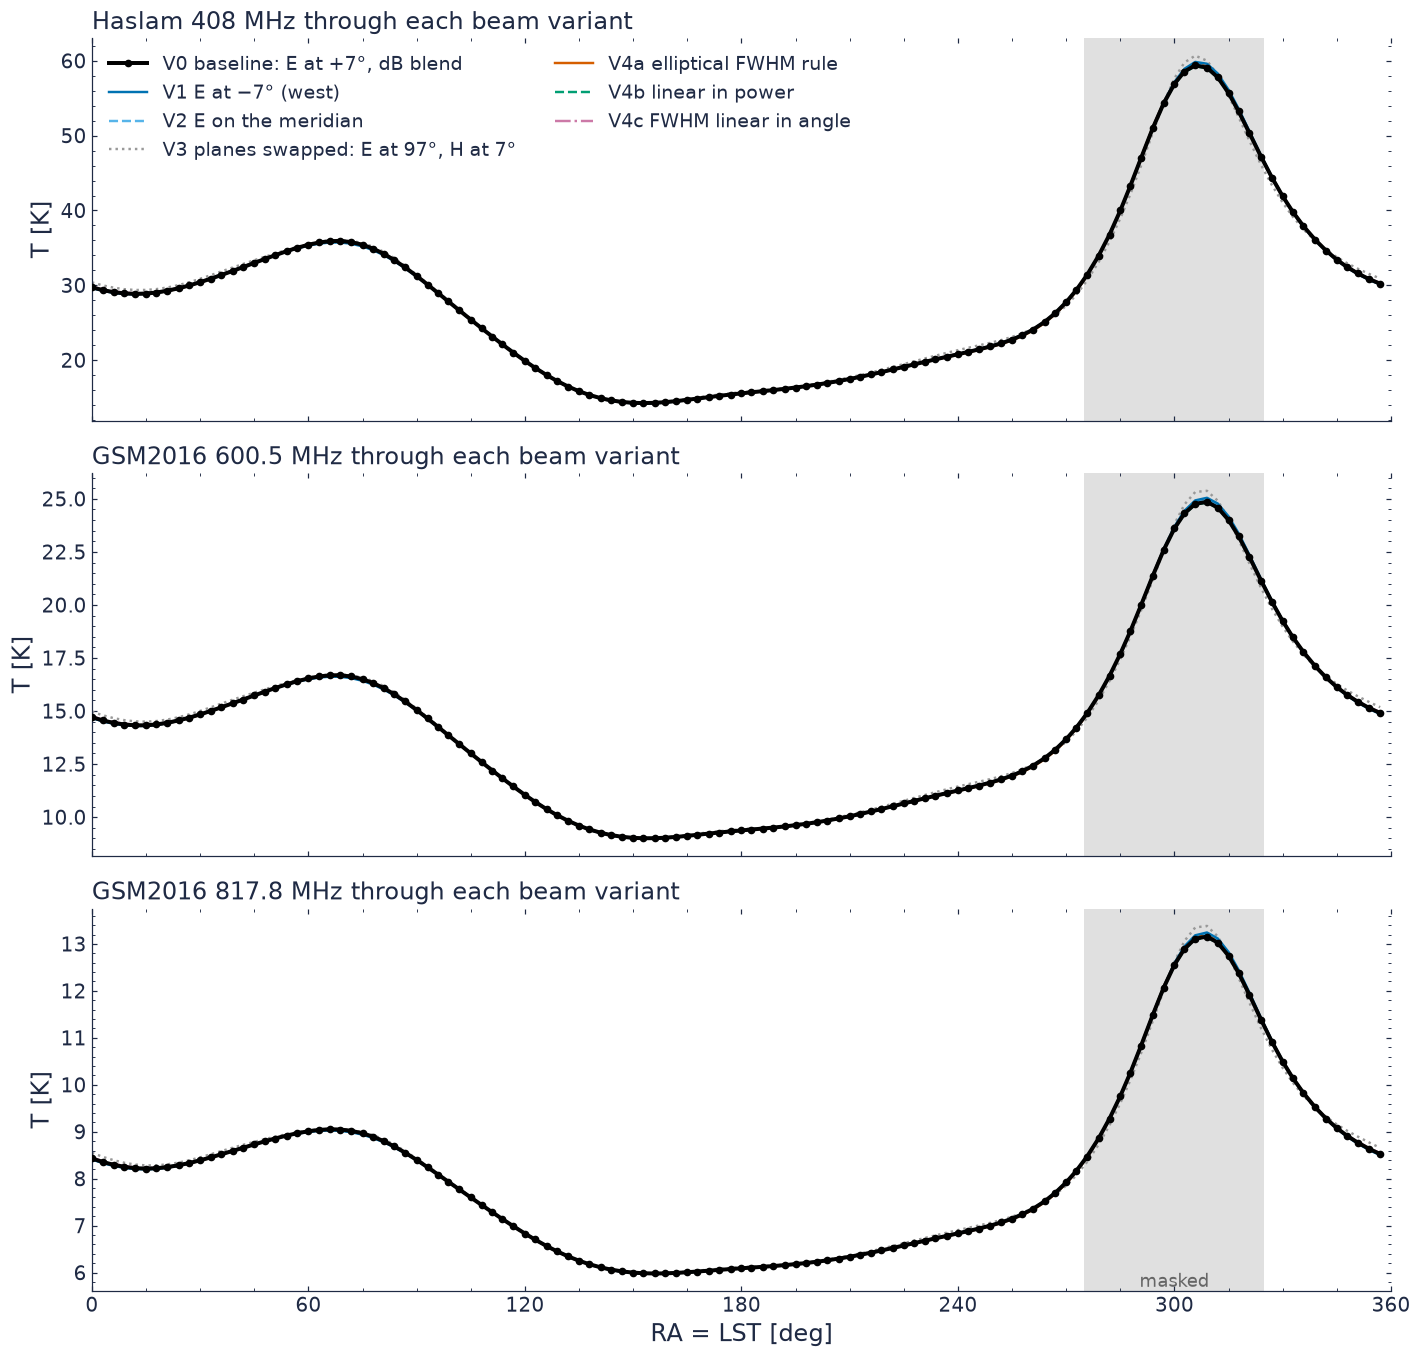

saved test_outputs/beam_variants/figA_T_vs_RA_beam_variants.png


In [30]:
# Figure A: T against RA (= LST) through every variant, one panel per sky model.
BV_RC = {"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 16, "legend.fontsize": 12.5,
         "xtick.labelsize": 13, "ytick.labelsize": 13}

def shade_mask(ax):
    lo, hi = MASK_RA - MASK_HALF, MASK_RA + MASK_HALF
    ax.axvspan(lo, hi, color="0.88", zorder=0, lw=0)
    if hi > 360:
        ax.axvspan(0, hi - 360, color="0.88", zorder=0, lw=0)

def bv_save(fig, name):
    fig.savefig(BV_OUT / f"{name}.png")
    plt.show()
    print(f"saved {os.path.relpath(BV_OUT / f'{name}.png', REPO)}")

with plt.rc_context(BV_RC):
    fig, axes = plt.subplots(len(SKIES), 1, figsize=(13, 4.2 * len(SKIES)), sharex=True)
    for ax, n in zip(axes, SKIES):
        shade_mask(ax)
        for v in reversed(list(VARIANTS)):                  # V0 drawn last, on top
            ax.plot(BV_RA, BV_T[(v, n)], color=VCOL[v], ls=VLS[v], lw=2.6 if v == "V0" else 1.6,
                    label=VARIANTS[v]["label"], zorder=3 if v == "V0" else 2)
        ax.set_ylabel("T [K]")
        ax.set_title(f"{n} MHz through each beam variant", loc="left")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    h, l = axes[0].get_legend_handles_labels()
    axes[0].legend(h[::-1], l[::-1], ncol=2, loc="upper left")
    axes[-1].set_xlabel("RA = LST [deg]")
    axes[-1].set_xlim(0, 360); axes[-1].set_xticks(range(0, 361, 60))
    axes[-1].text(MASK_RA, axes[-1].get_ylim()[0], "masked", ha="center", va="bottom", fontsize=12, color="0.4")
    fig.tight_layout()
    bv_save(fig, "figA_T_vs_RA_beam_variants")

#### Figure B: each variant minus V0

The top row is in K and the bottom row in % of V0. The orange band is the TRIS ±1σ (`ring_sigma`) at that frequency:
about 0.067 K at 600.5 MHz and 0.430 K at 817.8 MHz. Haslam has no TRIS band. The masked RA range is shaded grey.

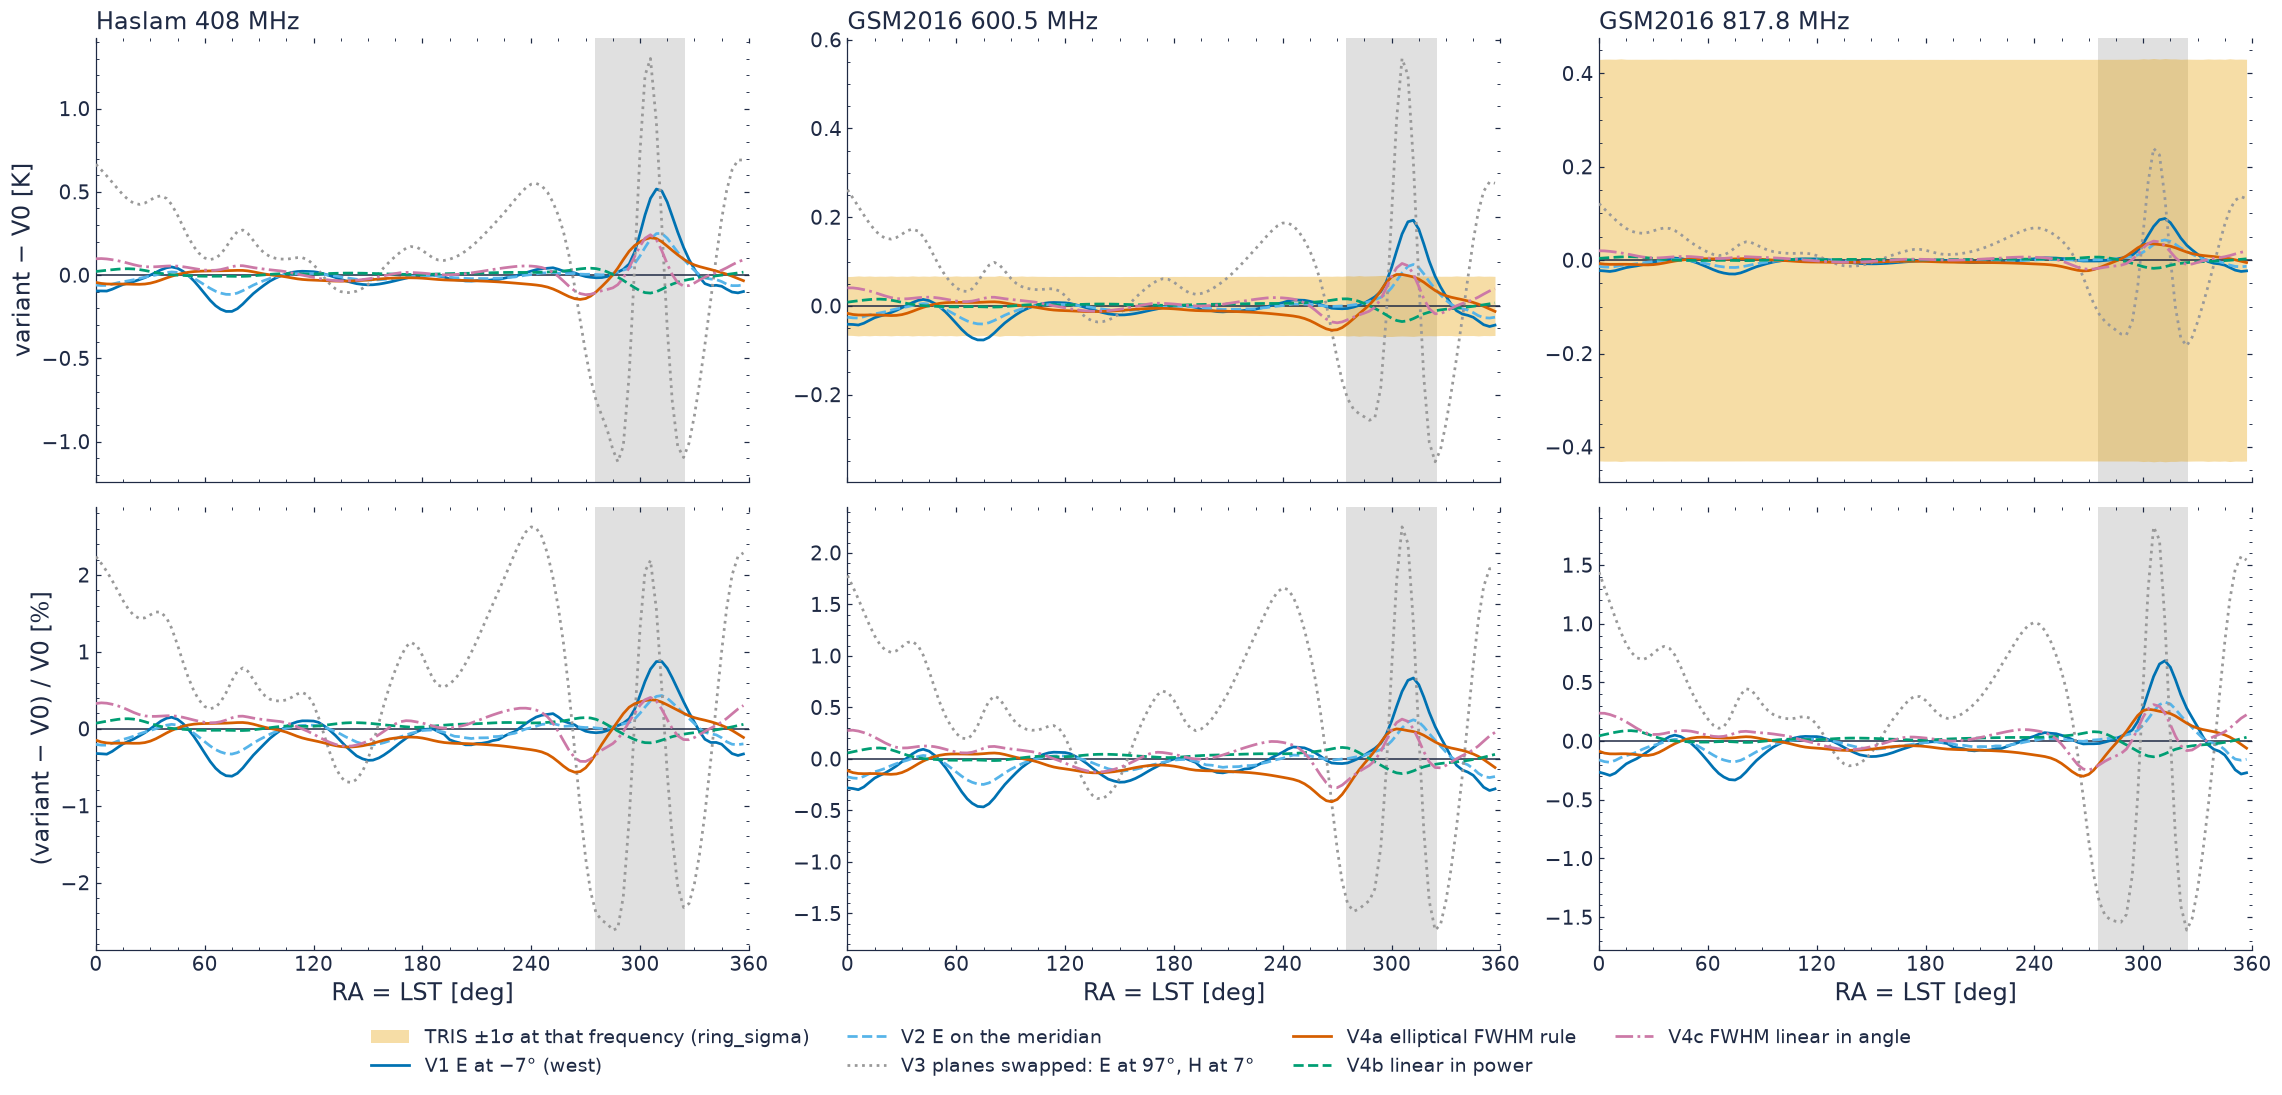

saved test_outputs/beam_variants/figB_difference_from_V0.png


In [31]:
# Figure B: variant − V0 in K (top) and in % of V0 (bottom), with the TRIS ±1σ (ring_sigma) for the TRIS bands.
OTHERS = [v for v in VARIANTS if v != "V0"]

with plt.rc_context(BV_RC):
    fig, axes = plt.subplots(2, len(SKIES), figsize=(7 * len(SKIES), 9.5), sharex=True)
    for j, (n, (nu, tkey)) in enumerate(SKIES.items()):
        v0 = BV_T[("V0", n)]
        for i, ax in enumerate(axes[:, j]):
            shade_mask(ax)
            if i == 0 and tkey:
                s = BV_TRIS[tkey][1]
                ax.fill_between(BV_RA, -s, s, color="#E69F00", alpha=0.35, lw=0, zorder=1,
                                label="TRIS ±1σ at that frequency (ring_sigma)")
            ax.axhline(0, color=COLORS["ink"])
            for v in OTHERS:
                d = BV_T[(v, n)] - v0
                ax.plot(BV_RA, d if i == 0 else 100 * d / v0, color=VCOL[v], ls=VLS[v], lw=1.8,
                        label=VARIANTS[v]["label"], zorder=3)
            for side in ("top", "right"):
                ax.spines[side].set_visible(False)
        axes[0, j].set_title(f"{n} MHz", loc="left")
        axes[1, j].set_xlabel("RA = LST [deg]")
    axes[0, 0].set_ylabel("variant − V0 [K]")
    axes[1, 0].set_ylabel("(variant − V0) / V0 [%]")
    axes[-1, 0].set_xlim(0, 360); axes[-1, 0].set_xticks(range(0, 361, 60))
    h, l = axes[0, 1].get_legend_handles_labels()
    fig.legend(h, l, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.06))
    fig.tight_layout()
    bv_save(fig, "figB_difference_from_V0")

#### Table 3: size of the change from V0

The statistics use the samples outside the mask (103).
* **max |Δ|** is the signed value at the largest |Δ|.
* **rms in TRIS σ** is the rms over samples of (variant − V0)/`ring_sigma`.
* **samples with |Δ| > σ** counts samples where the change exceeds the TRIS σ at that sample.
* The **nside 64** columns repeat rms and max from the resolution check.

In [32]:
# Table 3: variant − V0 per sky model, outside the mask and where both have coverage >= 0.5.
# "in TRIS σ" = rms over samples of (variant − V0) / ring_sigma, for the TRIS bands only.
def diff_stats(T, v, n):
    d = T[(v, n)] - T[("V0", n)]
    pct = 100 * d / T[("V0", n)]
    ok = np.isfinite(d) & ~BV_MASK
    k = np.flatnonzero(ok)[np.argmax(np.abs(d[ok]))]
    kp = np.flatnonzero(ok)[np.argmax(np.abs(pct[ok]))]
    tkey = SKIES[n][1]
    row = {"variant": v, "sky model": n, "samples": int(ok.sum()),
           "rms [K]": np.sqrt(np.mean(d[ok] ** 2)), "max |Δ| [K]": d[k], "RA of max [deg]": BV_RA[k],
           "rms [%]": np.sqrt(np.mean(pct[ok] ** 2)), "max |Δ| [%]": pct[kp], "RA of max % [deg]": BV_RA[kp],
           "median TRIS σ [K]": np.nan, "rms in TRIS σ": np.nan, "samples with |Δ| > σ": np.nan}
    if tkey:
        s = BV_TRIS[tkey][1]
        row["median TRIS σ [K]"] = np.median(s[ok])
        row["rms in TRIS σ"] = np.sqrt(np.mean((d[ok] / s[ok]) ** 2))
        row["samples with |Δ| > σ"] = int(np.sum(np.abs(d[ok]) > s[ok]))
    return row

table3 = pd.DataFrame([diff_stats(BV_T, v, n) for n in SKIES for v in OTHERS])
if BV_T_RES is not None:
    res = pd.DataFrame([diff_stats(BV_T_RES, v, n) for n in SKIES for v in OTHERS])
    table3[f"rms [K], nside {RES_CHECK_NSIDE}"] = res["rms [K]"].values
    table3[f"max |Δ| [K], nside {RES_CHECK_NSIDE}"] = res["max |Δ| [K]"].values
table3.to_csv(BV_OUT / "table3_difference_from_V0.csv", index=False, float_format="%.6g")
with pd.option_context("display.width", 250, "display.max_columns", 30):
    print(table3.set_index(["sky model", "variant"]).round(3).to_string())
print(f"\nsaved {os.path.relpath(BV_OUT / 'table3_difference_from_V0.csv', REPO)}")

                       samples  rms [K]  max |Δ| [K]  RA of max [deg]  rms [%]  max |Δ| [%]  RA of max % [deg]  median TRIS σ [K]  rms in TRIS σ  samples with |Δ| > σ  rms [K], nside 64  max |Δ| [K], nside 64
sky model     variant                                                                                                                                                                                           
Haslam 408    V1           103    0.069       -0.218            71.75    0.236       -0.616              75.00                NaN            NaN                   NaN              0.069                 -0.222
              V2           103    0.038       -0.116            75.00    0.129       -0.328              75.00                NaN            NaN                   NaN              0.038                 -0.118
              V3           103    0.350       -1.009           327.00    1.299        2.625             240.00                NaN            NaN                   N

#### Table 4: GSM2016 through each variant against the TRIS rings

The score is the rms over samples of (model − TRIS)/`ring_sigma`, outside the mask.

Two extra columns:
* The mean model − TRIS in K.
* The score after that mean is subtracted, since a zero-level or calibration difference would sit in the mean.

**This is not a test of the beam orientation.** GSM2016 is not the TRIS sky, and the calibration and zero-level
offsets differ from the data as well. A lower score for one variant is therefore not evidence that the beam is
oriented or interpolated that way.

In [33]:
# Table 4: GSM2016 through each variant against the TRIS ring at the same frequency, outside the mask.
# score = rms over samples of (model − TRIS) / ring_sigma.  Also given: the mean model − TRIS in K, and the
# score after that mean is subtracted (the mean is where a zero-level or calibration difference would sit).
rows = []
for n, (nu, tkey) in SKIES.items():
    if not tkey:
        continue
    t, s = BV_TRIS[tkey]
    for v in VARIANTS:
        d = BV_T[(v, n)] - t
        ok = np.isfinite(d) & ~BV_MASK
        mean = np.mean(d[ok])
        rows.append({"TRIS ring": tkey, "variant": v, "samples": int(ok.sum()),
                     "score: rms((model − TRIS)/σ)": np.sqrt(np.mean((d[ok] / s[ok]) ** 2)),
                     "mean model − TRIS [K]": mean,
                     "score after removing the mean": np.sqrt(np.mean(((d[ok] - mean) / s[ok]) ** 2)),
                     "rms model − TRIS [K]": np.sqrt(np.mean(d[ok] ** 2))})
table4 = pd.DataFrame(rows)
table4.to_csv(BV_OUT / "table4_model_vs_TRIS_score.csv", index=False, float_format="%.6g")
with pd.option_context("display.width", 250):
    print(table4.set_index(["TRIS ring", "variant"]).round(3).to_string())
print(f"\nsaved {os.path.relpath(BV_OUT / 'table4_model_vs_TRIS_score.csv', REPO)}")
print("Caveat: GSM2016 is not the TRIS sky, and the calibration and zero levels differ as well, so a lower "
      "score is not evidence for one beam orientation or interpolation.")

                   samples  score: rms((model − TRIS)/σ)  mean model − TRIS [K]  score after removing the mean  rms model − TRIS [K]
TRIS ring variant                                                                                                                   
TRIS_600  V0           103                        31.609                  2.087                          4.525                 2.109
          V1           103                        31.405                  2.074                          4.450                 2.095
          V2           103                        31.488                  2.079                          4.492                 2.101
          V3           103                        32.591                  2.156                          4.262                 2.175
          V4a          103                        31.492                  2.078                          4.677                 2.101
          V4b          103                        31.656             

#### Summary (run 2026-11-02)

The figures are outside the masked RA 299.9 ± 25°. The TRIS σ is 0.066–0.069 K at 600.5 MHz and 0.43 K at
817.8 MHz.

**More than the TRIS error:**
* **V3, planes swapped** (the extreme bound), at 600.5 MHz:
  * rms 0.124 K = 1.85σ, maximum −0.32 K at RA 327°.
  * 51 of 103 samples exceed σ: RA 0–54°, 75–87°, 213–273° and 327–357°.
* **V1, E plane 7° west instead of 7° east**, at 600.5 MHz:
  * rms 0.026 K = 0.38σ, maximum −0.077 K at RA 75°.
  * 4 samples exceed σ, at RA 69–78°.
  * Inside the mask its difference reaches 2.8σ (about +0.19 K at RA ≈ 310°).

**Within the TRIS error at every sample outside the mask:**
* **V2** (E plane on the meridian): rms 0.21σ, maximum −0.041 K at 600.5 MHz.
* **V4a** (elliptical FWHM rule): rms 0.27σ, maximum −0.055 K.
* **V4b** (linear in power): rms 0.09σ, maximum +0.016 K.
* **V4c** (FWHM linear in angle): rms 0.26σ, maximum +0.041 K.
* **Every variant at 817.8 MHz, including V3:** the largest change is −0.165 K (V3, RA 327°) against σ = 0.43 K.
  The rest stay below 0.03 K.

**At 408 MHz** (Haslam, no TRIS σ):
* V3 changes the curve by 0.35 K rms (1.3%) and up to −1.0 K.
* V1 changes it by 0.069 K rms, up to −0.22 K at RA 72°.
* The others change it by 0.016–0.049 K rms, up to 0.15 K.

**The nside 16 grid does not limit these numbers.** Every rms and maximum agrees with the nside 64 rerun to within
0.01 K.

**Against the TRIS data (Table 4):**
* The scores change by less than 1% between V0, V1, V2 and V4a–c: 31.4–31.7 at 600.5 MHz and 7.37–7.39 at
  817.8 MHz.
* The mean GSM2016 − TRIS of +2.1 K (600.5 MHz) and +3.2 K (817.8 MHz) sets almost all of the score.
* With that mean removed, the scores are 4.3–4.7 and 0.57–0.58.
* None of this ranks the beam variants (see the caveat above Table 4).

In [34]:
# Total notebook run time: from the first code cell (which sets _NB_T0) to here.
import time as _nb_time
if "_NB_T0" in globals():
    _dt = _nb_time.time() - _NB_T0
    print(f"total notebook run time: {_dt:.0f} s ({int(_dt // 3600)}h {int(_dt % 3600 // 60):02d}m {int(_dt % 60):02d}s)")
else:
    print("total notebook run time: not recorded (the first code cell was not run)")

total notebook run time: 2109 s (0h 35m 08s)
